# CFPB Complaint Classification and AI Governance

**INFO 4340 Final Project | Alex Toth & Tri Ho**

## Business Case and Question

### Background

The CFPB received about 6,635,400 complaints in 2025, roughly 553,000 a month, up from about 352,400 in 2019. It sent 90% to companies for review and response, referred 3% to other regulators and found 7% not actionable; credit or consumer reporting made up 88% of the year's complaints (CFPB, 2025 annual report, pp. 5 and 7). CFPB sends each complaint to the company named in it, 97% of them within a day (p. 3). The Issue travels with the complaint and shapes which team handles it inside the company. This project uses the June 2026 export of the Consumer Complaint Database: 620,794 complaints, 16,820 of them with a published narrative.

On the complaint form, the consumer picks a Product, then a Sub-product, then an Issue from a menu that depends on those two, and then a Sub-issue. That menu is a weak link. A consumer may pick an Issue that does not truly describe their problem, because the menu is long to work through, because its wording reflects an insider's view, or because the label names the problem without pointing toward a fix. When the label misses the problem, the complaint lands in the wrong queue at the company and has to be re-tagged and passed on, and at over half a million complaints a month that rework repeats at scale.

AI is already part of this process. The CFPB links the recent growth in complaints to large language models and AI agents that let bad actors flood the system with duplicate and spurious submissions (CFPB, 2025 annual report, p. 75), and some narratives we read look AI-assisted; one plainly pastes in a whole conversation with an AI assistant.

### Motivation

**Automation, not replacement.** The aim is to find the right pocket to automate: clear complaints with a clear Issue. Clear complaints arrive at the company already in the right queue the first time, and the company's complaint staff have more time for the vague ones, where an LLM would fail. Consumers benefit too: an easier menu, and a response from the right team. The Human Review rule in Governance is what separates the two.

### Business Question

**How closely does a zero-shot LLM's Issue choice match the Issue consumers select, compared with a free trained classifier, and which complaints can it label reliably enough to pass on without a closer human look?**

### Scope

We test one Issue per complaint, chosen from the menu of the consumer's own Product and Sub-product, and score it against the consumer's recorded Issue, with a trained classifier as the free benchmark. An expanded menu, multiple suggestions, Sub-issue suggestions, Product and Sub-product suggestions, and a staff-side study (would staff pick the LLM's Issue or the consumer's?) are future work.

**Source.** Consumer Financial Protection Bureau, *Consumer Response Annual Report, January 1 - December 31, 2025* (March 2026), `cfpb_2025-cr-annual-report_2026-03.pdf` in the project folder.

## Set Up

Libraries, settings, the data file's path, and the helpers used in more than one section: `check()` prints a PASS/FAIL line for every check in the notebook, `test_scores()` gives a model's accuracy, macro F1 and weighted F1, `wilson_ci()` gives a 95% confidence interval for a rate, and `read_text_csv()` reads a saved CSV with every column as text.

In [1]:
# --- Setup ---------------------------------------------------------------
# Libraries, settings, the data path and the helpers used in more than one section.
import hashlib
import json
import os
import re
import sys
import textwrap
import time
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import anthropic
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import openpyxl
from openpyxl.cell.cell import ILLEGAL_CHARACTERS_RE
from openpyxl.styles import Alignment, Font
from openpyxl.worksheet.datavalidation import DataValidation
import pandas as pd
import pypdf
from pypdf import PdfReader
import scipy
from scipy.stats import binomtest, chi2_contingency, norm
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

# Paths resolve from the project root, so the notebook runs on either partner's machine
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "raw" / "CCDB_Export_19_June_2026.zip"
# The CFPB complaint form's Product / Sub-product / Issue options (August 2023, the latest major revision)
FORM_PATH = PROJECT_DIR / "reference" / "cfpb_consumer_complaint_form_product_issue_options_August_2023_FINAL.pdf"


def check(name, passed, detail=""):
    """Print one PASS/FAIL line for a named check; returns whether it passed."""
    print(f"{'PASS' if passed else 'FAIL'}  {name}  {detail}")
    return passed


def read_text_csv(path):
    """Read a CSV as text; only empty cells count as missing, so text such as "NA" stays text."""
    return pd.read_csv(path, dtype=str, keep_default_na=False, na_values=[""])


def test_scores(y_true, y_pred):
    """Accuracy, macro F1 and weighted F1; the F1 scores cover the Issues present in y_true."""
    labels = sorted(y_true.unique())
    return pd.Series({
        "Accuracy": accuracy_score(y_true, y_pred),
        f"Macro F1 ({len(labels)} Issues in test)": f1_score(y_true, y_pred, labels=labels,
                                                              average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0),
    })


def wilson_ci(k, n, level=0.95):
    """Wilson score interval for the proportion k / n (works on arrays); returns (low, high)."""
    z = norm.ppf(0.5 + level / 2)
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    # The interval always holds the rate and lies in [0, 1]; clipping removes rounding noise at rates of 0 or 1
    return np.clip(centre - half, 0.0, p), np.clip(centre + half, p, 1.0)


print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__, "| pypdf:", pypdf.__version__,
      "| scipy:", scipy.__version__, "| scikit-learn:", sklearn.__version__, "| anthropic:", anthropic.__version__, "| openpyxl:", openpyxl.__version__)
assert FORM_PATH.exists(), f"Form file not found: {FORM_PATH}"

Python: 3.12.10
pandas: 3.0.5 | numpy: 2.5.3 | matplotlib: 3.11.1 | pypdf: 6.21.3 | scipy: 1.18.1 | scikit-learn: 1.9.0 | anthropic: 2.3.0 | openpyxl: 3.1.5


## Load Data

The CFPB Consumer Complaint Database export of complaints received in June 2026 (source and download steps in the project `README.md`, under Data). Every column is read as text, so types change only in Clean.

In [2]:
# --- Load data -----------------------------------------------------------
# Fingerprint of the June 2026 export, recorded when we first profiled it (2026-10-24).
# A different value means the file is not the one we profiled, so stop before reading it.
EXPECTED_SHA256 = "3021c8af9eeed4971a92f15be21c7ce08cf3c1337151de255e5b12bf782049df"
assert DATA_PATH.exists(), f"Data file not found: {DATA_PATH}"
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert check("file fingerprint matches the profiled export", actual_sha256 == EXPECTED_SHA256,
             f"(expected {EXPECTED_SHA256[:12]}..., actual {actual_sha256[:12]}...)"), "Wrong data file; do not continue"

# Read every column as text; types get converted on purpose in Clean
df_raw = pd.read_csv(DATA_PATH, dtype=str)

EXPECTED_COLS = [
    "Date received", "Product", "Sub-product", "Issue", "Sub-issue",
    "Consumer complaint narrative", "Company public response", "Company",
    "State", "ZIP code", "Tags", "Submitted via", "Date sent to company",
    "Company response to consumer", "Timely response?", "Complaint ID",
]
results = [
    check(f"{len(EXPECTED_COLS)} columns in the expected order", list(df_raw.columns) == EXPECTED_COLS),
    check("row count", len(df_raw) == 620_794, f"(expected 620,794, actual {len(df_raw):,})"),
    check("Complaint ID is unique", df_raw["Complaint ID"].is_unique),
]
assert all(results), "A load check failed; see the FAIL lines above"

print(f"\nLoaded {len(df_raw):,} rows x {df_raw.shape[1]} columns "
      f"({df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory)")

# Preview without the narrative column to keep the output short
df_raw.drop(columns=["Consumer complaint narrative"]).head(3)

PASS  file fingerprint matches the profiled export  (expected 3021c8af9eee..., actual 3021c8af9eee...)
PASS  16 columns in the expected order  
PASS  row count  (expected 620,794, actual 620,794)
PASS  Complaint ID is unique  

Loaded 620,794 rows x 16 columns (670 MB in memory)


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2026-06-07,Credit card,General-purpose credit card or charge card,Closing your account,Company closed your account,NaN,OneMain Finance Corporation,TN,37087,NaN,Web,2026-06-07,Closed with explanation,Yes,22972138
1,2026-06-06,Credit reporting or other personal consumer reports,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't recognize,NaN,"EQUIFAX, INC.",MI,48221,NaN,Web,2026-06-06,Closed with explanation,Yes,22960234
2,2026-06-02,Debt collection,Other debt,Electronic communications,"You told them to stop contacting you, but they keep trying",NaN,"Landmark Strategy Group, LLC",NC,28278,NaN,Web,2026-08-28,Untimely response,No,22819786


## Explore

What the export contains, and the evidence behind three decisions: which complaints the models can read, what they predict, and which copies to drop.
- **Structure, Value Counts, Raw Data Dictionary:** every column of the full export profiled.
- **Narrative Subset:** the complaints with a narrative, the only ones a language model can read, compared with the full export.
- **Target Candidates:** four possible targets; relief is set aside and Issue is chosen.
- **Duplicate Narratives:** repeated and scripted texts, and the rule for removing them.

### Structure

Dimensions, data types, missingness and uniqueness for every column, computed directly from the raw export. Everything here is read off the data; no outside assumptions.

In [3]:
# --- Profile: structure ----------------------------------------------------
n_rows, n_cols = df_raw.shape
print(f"Dimensions: {n_rows:,} rows x {n_cols} columns")

profile = pd.DataFrame({
    "dtype":     df_raw.dtypes.astype(str),
    "non_null":  df_raw.notna().sum(),
    "null_n":    df_raw.isna().sum(),
    "null_%":    (100 * df_raw.isna().mean()).round(1),
    "n_unique":  df_raw.nunique(),
    "unique_%":  (100 * df_raw.nunique() / n_rows).round(2),
})

display(profile)

Dimensions: 620,794 rows x 16 columns


,dtype,non_null,null_n,null_%,n_unique,unique_%
Date received,str,620794,0,0.0,30,0.00
Product,str,620794,0,0.0,11,0.00
Sub-product,str,620794,0,0.0,55,0.01
Issue,str,620794,0,0.0,85,0.01
Sub-issue,str,613772,7022,1.1,208,0.03
Consumer complaint narrative,str,16820,603974,97.3,15380,2.48
Company public response,str,389489,231305,37.3,9,0.00
Company,str,620794,0,0.0,1831,0.29
State,str,620223,571,0.1,60,0.01
ZIP code,str,620329,465,0.1,14756,2.38


### Value Counts

How often each value appears in the category columns: the options a consumer picks when filing (Product, Sub-product, Issue, Sub-issue) and the other fixed-value fields (Company, State, Tags, how the complaint was submitted, how the company responded). Complaint ID, the dates, ZIP code and the narrative are skipped; the narrative gets its own sections later.

Columns with up to 15 values are listed in full, the rest show their top 10; missing values appear as `NaN`.

In [4]:
# --- Profile: value counts -------------------------------------------------
SKIP_COLS = ["Complaint ID", "Consumer complaint narrative",   # identifier, free text
             "Date received", "Date sent to company",          # dates: covered in Structure and Clean
             "ZIP code"]                                       # location code, not a category
FULL_LIST_MAX = 15  # list every value when a column has at most this many
TOP_N = 10

for col in df_raw.columns.drop(SKIP_COLS):
    vc = df_raw[col].value_counts(dropna=False)
    n_distinct = int(profile.loc[col, "n_unique"])  # int() tells VS Code this is a whole number (else it flags the <= below)
    shown = vc if n_distinct <= FULL_LIST_MAX else vc.head(TOP_N)
    label = "all values" if n_distinct <= FULL_LIST_MAX else f"top {TOP_N} of {n_distinct:,}"

    print(f"\n=== {col} ({label}) ===")
    for value, count in shown.items():
        print(f"  {str(value)[:60]:60} {count:>9,}  {100 * count / n_rows:5.1f}%")


=== Product (all values) ===
  Credit reporting or other personal consumer reports            565,831   91.1%
  Debt collection                                                 27,629    4.5%
  Checking or savings account                                      7,671    1.2%
  Credit card                                                      7,453    1.2%
  Money transfer, virtual currency, or money service               3,037    0.5%
  Mortgage                                                         2,967    0.5%
  Vehicle loan or lease                                            2,002    0.3%
  Student loan                                                     1,724    0.3%
  Payday loan, title loan, personal loan, or advance loan          1,588    0.3%
  Prepaid card                                                       523    0.1%
  Debt or credit management                                          369    0.1%

=== Sub-product (top 10 of 55) ===
  Credit reporting                         

### Raw Data Dictionary

One row per raw column of the full export. How Clean treats each column is in the Cleaned Data Dictionary at the end. Sources for each part:
- `kind`, `observed`: read off the raw export (Structure, Value Counts and direct counts).
- `null_%`, `n_unique`: pulled from the `profile` table, not typed by hand.
- `cfpb_description`: quoted from the CFPB page *How we share complaint data*, table "What we publish in the Consumer Complaint Database" (https://www.consumerfinance.gov/complaint/data-use/, page last updated 2026-09-14, filtered for June, 2026). The page does not describe the narrative field.

In [5]:
# --- Data dictionary -------------------------------------------------------
NOT_DESCRIBED = "Not described on the CFPB data-use page"

FIELD_NOTES = {
    "Date received": {
        "kind": "date",
        "cfpb_description": "The date the CFPB received the complaint.",
        "observed": "30 distinct dates; stored as YYYY-MM-DD text",
    },
    "Product": {
        "kind": "category",
        "cfpb_description": "The type of product the consumer identified in the complaint.",
        "observed": "11 values; credit reporting is 91.1% of rows",
    },
    "Sub-product": {
        "kind": "category",
        "cfpb_description": "The type of sub-product the consumer identified in the complaint.",
        "observed": "55 values; 'I do not know' in 18,577 rows (3.0%)",
    },
    "Issue": {
        "kind": "category",
        "cfpb_description": "The issue the consumer identified in the complaint.",
        "observed": "85 values; top 3 (all credit reporting) cover 90.6%",
    },
    "Sub-issue": {
        "kind": "category",
        "cfpb_description": "The sub-issue the consumer identified in the complaint.",
        "observed": "208 values; 1.1% missing",
    },
    "Consumer complaint narrative": {
        "kind": "text",
        "cfpb_description": NOT_DESCRIBED,
        "observed": "Filled in 2.7% of rows; 15,380 unique texts out of 16,820 (repeats exist)",
    },
    "Company public response": {
        "kind": "category",
        "cfpb_description": "The company's optional, public-facing response to a consumer's complaint.",
        "observed": "9 values; 37.3% missing; one fixed text covers 62.2%",
    },
    "Company": {
        "kind": "category",
        "cfpb_description": "The complaint is about this company.",
        "observed": "1,831 companies; the three largest cover 88.7%",
    },
    "State": {
        "kind": "geo",
        "cfpb_description": "The state of the mailing address provided by the consumer.",
        "observed": "60 values (more than 50 states + DC); 0.1% missing",
    },
    "ZIP code": {
        "kind": "geo",
        "cfpb_description": "The mailing ZIP code provided by the consumer.",
        "observed": "465 blank plus 1,694 'XXXXX' (masking not documented as XXXXX)",
    },
    "Tags": {
        "kind": "flag",
        "cfpb_description": "Data that supports easier searching and sorting of complaints "
                            "submitted by or on behalf of consumers.",
        "observed": "97.8% missing; 758 rows combine 'Older American, Servicemember'",
    },
    "Submitted via": {
        "kind": "category",
        "cfpb_description": "How the complaint was submitted to the CFPB.",
        "observed": "4 values; Web is 99.5%",
    },
    "Date sent to company": {
        "kind": "date",
        "cfpb_description": "The date the CFPB sent the complaint to the company.",
        "observed": "80 distinct dates (vs. 30 for Date received)",
    },
    "Company response to consumer": {
        "kind": "category",
        "cfpb_description": "This is how the company responded.",
        "observed": "5 values; monetary relief 0.5%; 448 'In progress'",
    },
    "Timely response?": {
        "kind": "flag",
        "cfpb_description": "Whether the company gave a timely response.",
        "observed": "Yes/No; 3,139 'No' vs. 2,233 'Untimely response' in the column above",
    },
    "Complaint ID": {
        "kind": "id",
        "cfpb_description": "The unique identification number for a complaint.",
        "observed": "Unique for all 620,794 rows",
    },
}
assert list(FIELD_NOTES) == list(df_raw.columns), "Dictionary doesn't match the raw columns (names or order)"

data_dict = pd.DataFrame.from_dict(FIELD_NOTES, orient="index")
data_dict.insert(1, "null_%", profile["null_%"])
data_dict.insert(2, "n_unique", profile["n_unique"])
data_dict.index.name = "column"

with pd.option_context("display.max_colwidth", 120):
    display(data_dict)

,kind,null_%,n_unique,cfpb_description,observed
column,,,,,
Date received,date,0.0,30,The date the CFPB received the complaint.,30 distinct dates; stored as YYYY-MM-DD text
Product,category,0.0,11,The type of product the consumer identified in the complaint.,11 values; credit reporting is 91.1% of rows
Sub-product,category,0.0,55,The type of sub-product the consumer identified in the complaint.,"55 values; 'I do not know' in 18,577 rows (3.0%)"
Issue,category,0.0,85,The issue the consumer identified in the complaint.,85 values; top 3 (all credit reporting) cover 90.6%
Sub-issue,category,1.1,208,The sub-issue the consumer identified in the complaint.,208 values; 1.1% missing
Consumer complaint narrative,text,97.3,15380,Not described on the CFPB data-use page,"Filled in 2.7% of rows; 15,380 unique texts out of 16,820 (repeats exist)"
Company public response,category,37.3,9,"The company's optional, public-facing response to a consumer's complaint.",9 values; 37.3% missing; one fixed text covers 62.2%
Company,category,0.0,1831,The complaint is about this company.,"1,831 companies; the three largest cover 88.7%"
State,geo,0.1,60,The state of the mailing address provided by the consumer.,60 values (more than 50 states + DC); 0.1% missing


### Narrative Subset

Only complaints with a consumer narrative can be read by a language model, so check how that subset compares with the full export.

In [6]:
# --- Explore: narrative subset vs. all complaints --------------------------
NARRATIVE_COL = "Consumer complaint narrative"
has_narrative = df_raw[NARRATIVE_COL].fillna("").str.strip() != ""
df_narrative = df_raw[has_narrative]
print(f"Complaints with a narrative: {has_narrative.sum():,} of {len(df_raw):,} ({has_narrative.mean():.1%})")

# Product mix in each population, and how often each product's complaints include a narrative
by_product = pd.DataFrame({
    "all_n": df_raw["Product"].value_counts(),
    "narrative_n": df_narrative["Product"].value_counts(),
})
by_product["all_%"] = 100 * by_product["all_n"] / by_product["all_n"].sum()
by_product["narrative_%"] = 100 * by_product["narrative_n"] / by_product["narrative_n"].sum()
by_product["has_narrative_%"] = 100 * by_product["narrative_n"] / by_product["all_n"]  # narratives / all complaints
by_product = (by_product[["all_n", "all_%", "narrative_n", "narrative_%", "has_narrative_%"]]
              .sort_values("narrative_n", ascending=False))

results = [
    check("all-complaint shares add to 100%", np.isclose(by_product["all_%"].sum(), 100),
          f"({by_product['all_%'].sum():.1f}%)"),
    check("narrative shares add to 100%", np.isclose(by_product["narrative_%"].sum(), 100),
          f"({by_product['narrative_%'].sum():.1f}%)"),
]
assert all(results), "A share check failed; see the FAIL lines above"
display(by_product.round({"all_%": 1, "narrative_%": 1, "has_narrative_%": 2}))

Complaints with a narrative: 16,820 of 620,794 (2.7%)
PASS  all-complaint shares add to 100%  (100.0%)
PASS  narrative shares add to 100%  (100.0%)


,all_n,all_%,narrative_n,narrative_%,has_narrative_%
Product,,,,,
Debt collection,27629,4.5,5098,30.3,18.45
Checking or savings account,7671,1.2,3270,19.4,42.63
Credit card,7453,1.2,2840,16.9,38.11
"Money transfer, virtual currency, or money service",3037,0.5,1340,8.0,44.12
Mortgage,2967,0.5,1151,6.8,38.79
Vehicle loan or lease,2002,0.3,793,4.7,39.61
Credit reporting or other personal consumer reports,565831,91.1,751,4.5,0.13
"Payday loan, title loan, personal loan, or advance loan",1588,0.3,636,3.8,40.05
Student loan,1724,0.3,576,3.4,33.41


#### Chart: Product Mix, All Complaints vs. Narratives

The table above as a picture: the narrative subset has a very different product mix from the full export. One row per product, with its share of all complaints and its share of narratives, joined by a line. Same base as the table above (all rows, including 'In progress').

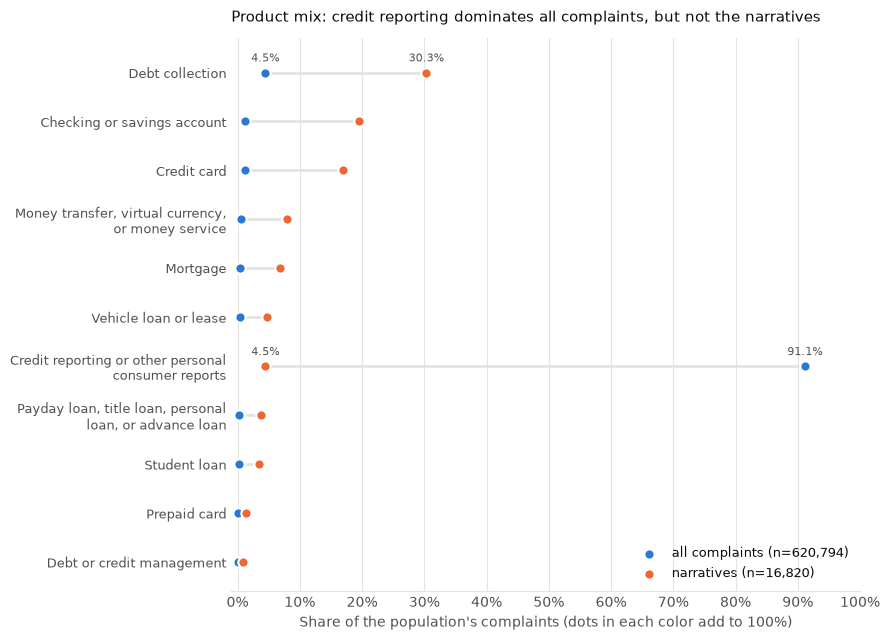

In [7]:
# --- Chart: product mix, all complaints vs. narratives ----------------------
# Chart colors for every chart in the notebook: blue = all complaints, orange = narratives
# (a colorblind-safe pair), plus grays for text and gridlines
POP_COLORS = {"all complaints": "#2a78d6", "narratives": "#eb6834"}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

# Plot: products sorted by narrative share, highest at the top
mix = by_product.sort_values("narrative_%")
y = np.arange(len(mix))

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.hlines(y, mix["all_%"], mix["narrative_%"], color=GRID, lw=2, zorder=1)
for col, name in [("all_%", "all complaints"), ("narrative_%", "narratives")]:
    total = mix[col.replace("%", "n")].sum()
    ax.scatter(mix[col], y, s=55, color=POP_COLORS[name], edgecolor="white", linewidth=1.5, zorder=3,
               label=f"{name} (n={total:,})")

# Direct labels on the two products that move the most
for product in ["Credit reporting or other personal consumer reports", "Debt collection"]:
    row = y[mix.index.get_loc(product)]
    for col in ["all_%", "narrative_%"]:
        ax.annotate(f"{mix.loc[product, col]:.1f}%", (mix.loc[product, col], row), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=8, color=INK_MUTED)

ax.set_yticks(y, [textwrap.fill(p, 34) for p in mix.index], fontsize=9, color=INK)
ax.set_ylim(-0.6, len(mix) - 0.3)
ax.set_xlim(-1, 100)
ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(10))
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
ax.set_xlabel("Share of the population's complaints (dots in each color add to 100%)", color=INK_MUTED)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=INK_MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK)
ax.set_title("Product mix: credit reporting dominates all complaints, but not the narratives",
             loc="left", fontsize=11, color=INK, pad=12)
fig.tight_layout()
plt.show()

**How to read the chart**

Think of it as two pie charts drawn as dots, with one row per product:
- **Blue dot:** the product's share of all 620,794 complaints (the product mix of the full export).
- **Orange dot:** the product's share of the 16,820 narratives (the product mix of the narrative subset).
- **Each color adds to 100%** across the 11 products, so when one product's share shrinks, the others must grow.
- **Gray line:** the gap between the two shares. The longer the line, the more the narratives over- or under-represent that product.

*Example:* credit card has fewer narratives than complaints (2,840 vs. 7,453), as a subset must. But it is a bigger slice of a much smaller pie: 16.9% of narratives vs. 1.2% of all complaints.

**What it shows**

1. **Credit reporting nearly disappears:** 91.1% of all complaints, but 4.5% of narratives.
2. **Debt collection becomes the largest product:** 4.5% of all complaints, but 30.3% of narratives.
3. **Every other product gains share,** e.g. checking/savings 1.2% → 19.4% and credit card 1.2% → 16.9%.

**Why:** only 0.13% of credit-reporting complaints include a narrative (751 of 565,831), against 18.5% for debt collection, 33-44% for every other product, and 2.7% overall (`has_narrative_%` in the table above). The data does not say why.

**Implication:** the narratives are not a representative sample of the export. Anything learned from them, including the model, describes complaints led by debt collection, checking/savings and credit card, with very few about credit reporting. The same product mix explains why the overall relief rates of the two groups differ (Relief Patterns).

*Note:* shares here include complaints still 'In progress', so credit reporting reads 91.1% here vs. 91.2% of *closed* complaints in the relief charts.

### Target Candidates

Four columns could be the model's target, compared here within the narratives (the only complaints an LLM can read):
- **Company response to consumer** (relief): *how the complaint ended*, reported by the company. Evaluated first, in Candidate 1, and set aside.
- **Product, Sub-product, Issue:** *what the complaint is about*, picked by the consumer when filing. Evaluated in Candidates 2-4; **Issue is chosen**.

What the table measures:
- `classes_>=30` / `classes_>=100`: classes with enough narratives to score on their own.
- `classes_per_product`: how many options one product offers (Sub-product and Issue options depend on the product).
- `largest_%` / `top5_%`: how much the biggest classes dominate; a dominant class makes accuracy look high without meaning much.

In [8]:
# --- Explore: target candidates (narrative subset) --------------------------
TARGET_CANDIDATES = ["Company response to consumer", "Product", "Sub-product", "Issue"]  # in the order evaluated
MIN_CLASS_SMALL, MIN_CLASS_LARGE = 30, 100


def describe_target(col):
    """Class structure of one candidate target within the narrative subset."""
    vc = df_narrative[col].value_counts()
    per_product = df_narrative.groupby("Product")[col].nunique()
    return {
        "classes": len(vc),
        f"classes_>={MIN_CLASS_SMALL}": int((vc >= MIN_CLASS_SMALL).sum()),
        f"classes_>={MIN_CLASS_LARGE}": int((vc >= MIN_CLASS_LARGE).sum()),
        "classes_per_product": f"{per_product.min()}-{per_product.max()}",
        "largest_class": str(vc.index[0])[:45],
        "largest_%": round(100 * vc.iloc[0] / vc.sum(), 1),
        "top5_%": round(100 * vc.head(5).sum() / vc.sum(), 1),
    }


n_missing = int(df_narrative[TARGET_CANDIDATES].isna().sum().sum())
assert check("no missing labels in any candidate", n_missing == 0, f"(missing: {n_missing})")

targets = pd.DataFrame({col: describe_target(col) for col in TARGET_CANDIDATES}).T
display(targets)

PASS  no missing labels in any candidate  (missing: 0)


,classes,classes_>=30,classes_>=100,classes_per_product,largest_class,largest_%,top5_%
Company response to consumer,4,4,4,3-4,Closed with explanation,76.5,100.0
Product,11,11,11,1-1,Debt collection,30.3,81.4
Sub-product,52,37,26,2-11,Checking account,16.0,54.1
Issue,83,53,38,5-28,Attempts to collect debt not owed,13.7,40.8


#### Candidate 1: Relief Patterns

Could a model read a narrative and predict how the complaint ends (`Company response to consumer`)? This part describes which complaints end in relief, for all complaints and for the narratives; it fits no model. **Relief is set aside**; the four reasons are at the end of this part (*Why Relief Was Not Chosen as the Target*).

**What the response categories mean.** Companies "select the closure category that is supported by their actions and written response", one per complaint (CFPB, *2025 Consumer Response Annual Report*, published March 2026, section "Complaint response categories", pp. 12-13; https://files.consumerfinance.gov/f/documents/cfpb_2025-cr-annual-report_2026-03.pdf):
- *Closed with monetary relief*: "company reported providing objective, measurable, and verifiable monetary relief to the consumer as a direct result of the steps that have or will be taken in response to the complaint."
- *Closed with non-monetary relief*: "company reported providing other objective and verifiable relief to the consumer [...] (e.g., stopping unwanted calls from debt collectors; correcting account information; correcting inaccurate data provided or reported in a credit report; issuing corrected documents; restoring account access; and, addressing formerly unmet customer service issues)."
- *Closed with explanation*: "company reported that the complaint did not result in relief but provided a written explanation tailored to the issues raised by the consumer."

Two consequences for reading the rates: every category is *company-reported*, not verified by us, and the export has no dollar amounts. The quoted section does not define `Untimely response` or `In progress`; how we treat them below is our choice.

**How the rates are computed**
- **Monetary**, **non-monetary** and **any relief** (either of the two). Each complaint has one closure category, so monetary + non-monetary = any relief. The tables report monetary and any relief; the charts show monetary and non-monetary.
- `In progress` complaints have no final outcome and are excluded; `Untimely response` counts as closed without relief.
- Each rate has a 95% Wilson confidence interval (suited to small proportions).
- The company table ranks only companies with at least `MIN_GROUP_N` (100) complaints, so small ones can't top the list by chance.
- All rates are associations, not causes: a high rate says which complaints *tend* to end in relief, not why.

In [9]:
# --- Explore: relief patterns ----------------------------------------------
OUTCOME_COL = "Company response to consumer"
MONETARY = "Closed with monetary relief"
NON_MONETARY = "Closed with non-monetary relief"
MIN_GROUP_N = 100  # groups smaller than this are not ranked
TOP_N = 10


def relief_table(df, by):
    """Monetary and any-relief rates per group with 95% CIs; 'In progress' complaints excluded."""
    closed = df[df[OUTCOME_COL] != "In progress"]
    grouped = closed.assign(
        monetary=closed[OUTCOME_COL].eq(MONETARY),
        any_relief=closed[OUTCOME_COL].isin([MONETARY, NON_MONETARY]),
    ).groupby(by)[["monetary", "any_relief"]]
    n = grouped.size()
    counts = grouped.sum()

    out = pd.DataFrame({"n": n})
    for name in ["monetary", "any_relief"]:
        low, high = wilson_ci(counts[name], n)
        out[f"{name}_%"] = (100 * counts[name] / n).round(1)
        out[f"{name}_95CI"] = [f"{100 * a:.1f}-{100 * b:.1f}" for a, b in zip(low, high)]
    return out


populations = {"all complaints": df_raw, "narratives": df_narrative}

# Overall baseline for each population
for name, df in populations.items():
    overall = relief_table(df.assign(_all="all"), "_all").iloc[0]
    print(f"{name:15} n={overall['n']:>8,}  monetary {overall['monetary_%']:4.1f}% ({overall['monetary_95CI']})  "
          f"any relief {overall['any_relief_%']:4.1f}% ({overall['any_relief_95CI']})")

# 1. Product: both populations side by side
by_product_relief = pd.concat({name: relief_table(df, "Product") for name, df in populations.items()}, axis=1)
display(by_product_relief.sort_values(("all complaints", "monetary_%"), ascending=False))

# 2. Company (narratives): top groups by monetary rate among companies with n >= MIN_GROUP_N
company = relief_table(df_narrative, "Company")
eligible = company[company["n"] >= MIN_GROUP_N]
print(f"\nCompany | narratives: top {TOP_N} by monetary relief "
      f"({len(eligible)} of {len(company)} companies have n >= {MIN_GROUP_N})")
display(eligible.sort_values("monetary_%", ascending=False).head(TOP_N))

all complaints  n= 620,346  monetary  0.5% (0.4-0.5)  any relief 35.2% (35.1-35.3)
narratives      n=  16,820  monetary  7.1% (6.7-7.5)  any relief 20.6% (20.0-21.2)


all complaints  \
                                                                     n   
Product                                                                  
Credit card                                                       7380   
Checking or savings account                                       7637   
Prepaid card                                                       521   
Money transfer, virtual currency, or money service                3025   
Payday loan, title loan, personal loan, or advance loan           1550   
Debt or credit management                                          362   
Vehicle loan or lease                                             1992   
Mortgage                                                          2940   
Student loan                                                      1712   
Debt collection                                                  27502   
Credit reporting or other personal consumer reports             565725   

                                                                    \
                                                        monetary_%   
Product                                                              
Credit card                                                   16.5   
Checking or savings account                                   13.4   
Prepaid card                                                  12.9   
Money transfer, virtual currency, or money service             9.2   
Payday loan, title loan, personal loan, or advance loan        3.3   
Debt or credit management                                      3.3   
Vehicle loan or lease                                          2.2   
Mortgage                                                       1.8   
Student loan                                                   0.4   
Debt collection                                                0.2   
Credit reporting or other personal consumer reports            0.0   

                                                                       \
                                                        monetary_95CI   
Product                                                                 
Credit card                                                 15.6-17.3   
Checking or savings account                                 12.7-14.2   
Prepaid card                                                10.3-16.0   
Money transfer, virtual currency, or money service           8.2-10.3   
Payday loan, title loan, personal loan, or advance loan       2.5-4.3   
Debt or credit management                                     1.9-5.7   
Vehicle loan or lease                                         1.6-3.0   
Mortgage                                                      1.4-2.3   
Student loan                                                  0.2-0.8   
Debt collection                                               0.1-0.2   
Credit reporting or other personal consumer reports           0.0-0.0   

                                                                      \
                                                        any_relief_%   
Product                                                                
Credit card                                                     26.0   
Checking or savings account                                     19.1   
Prepaid card                                                    18.2   
Money transfer, virtual currency, or money service              16.8   
Payday loan, title loan, personal loan, or advance loan          5.7   
Debt or credit management                                       18.8   
Vehicle loan or lease                                            9.1   
Mortgage                                                         5.4   
Student loan                                                     2.4   
Debt collection                                                 26.5   
Credit reporting or other personal consumer reports             36.5   

      


Company | narratives: top 10 by monetary relief (35 of 1024 companies have n >= 100)


,n,monetary_%,monetary_95CI,any_relief_%,any_relief_95CI
Company,,,,,
"BANK OF AMERICA, NATIONAL ASSOCIATION",599,35.9,32.2-39.8,40.4,36.5-44.4
"CITIBANK, N.A.",583,26.2,22.8-30.0,42.4,38.4-46.4
"Bread Financial Holdings, Inc.",134,25.4,18.8-33.4,51.5,43.1-59.8
"Paypal Holdings, Inc",496,24.4,20.8-28.4,46.6,42.2-51.0
TD BANK US HOLDING COMPANY,137,19.0,13.3-26.4,40.1,32.3-48.5
AMERICAN EXPRESS COMPANY,256,17.6,13.4-22.7,23.0,18.3-28.6
UNITED SERVICES AUTOMOBILE ASSOCIATION,116,16.4,10.7-24.2,22.4,15.8-30.8
SYNCHRONY FINANCIAL,380,15.3,12.0-19.2,17.9,14.4-22.1
WELLS FARGO & COMPANY,562,13.0,10.5-16.0,23.5,20.2-27.2


##### Chart: Monetary Relief by Product

The product table above as a picture: one row per product, one dot per population (all complaints vs. narratives) with its 95% Wilson CI. Dashed lines mark each population's overall rate. Same rules as `relief_table()` ('In progress' excluded), and the cell checks that its numbers match that table before plotting.

PASS  all complaints: n per product matches relief_table  (expected total 620,346, actual 620,346)
PASS  all complaints: rate per product matches relief_table  (max abs difference 0.0 points)
PASS  all complaints: every rate inside its CI  
PASS  narratives: n per product matches relief_table  (expected total 16,820, actual 16,820)
PASS  narratives: rate per product matches relief_table  (max abs difference 0.0 points)
PASS  narratives: every rate inside its CI  


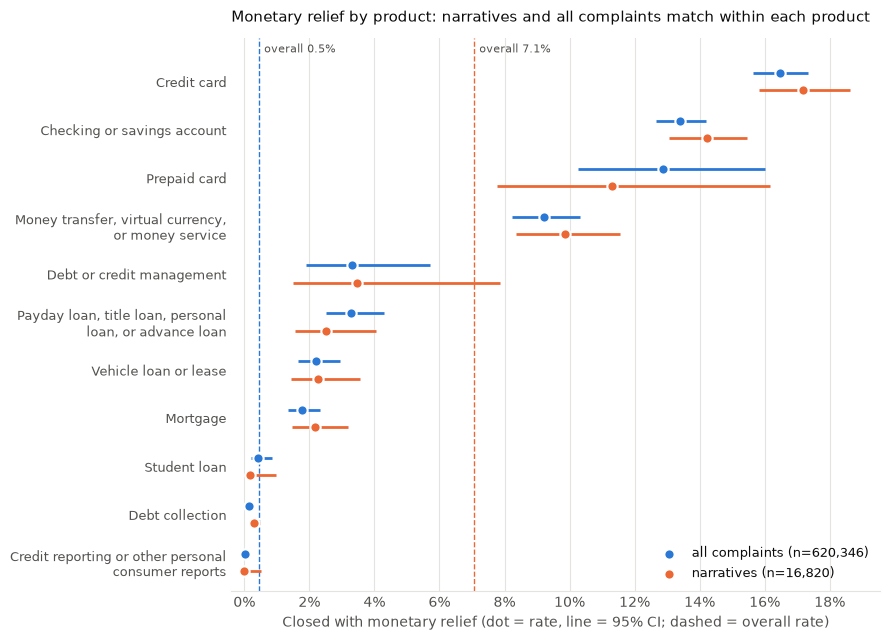

In [10]:
# --- Chart: monetary relief by product -------------------------------------
DODGE = 0.18  # vertical offset within a row so the two CIs don't overlap


def relief_points(df, outcome):
    """Rate of one outcome and its 95% Wilson CI (in %) per product; 'In progress' excluded."""
    closed = df[df[OUTCOME_COL] != "In progress"]
    is_outcome = closed[OUTCOME_COL].eq(outcome).groupby(closed["Product"])
    k, n = is_outcome.sum(), is_outcome.size()
    low, high = wilson_ci(k, n)
    return pd.DataFrame({"n": n, "k": k, "rate": 100 * k / n, "low": 100 * low, "high": 100 * high})


def plot_relief_dots(points, xlabel, title, tick_step):
    """Dot plot per product, one dot + CI per population, sorted by the all-complaints rate (highest on top)."""
    order = points["all complaints"].sort_values("rate").index
    y = np.arange(len(order))

    fig, ax = plt.subplots(figsize=(9, 6.5))
    for offset, (name, pts) in zip([DODGE, -DODGE], points.items()):
        pts = pts.reindex(order)
        color = POP_COLORS[name]
        overall = 100 * pts["k"].sum() / pts["n"].sum()
        ax.axvline(overall, color=color, lw=1, ls="--", zorder=1)
        ax.text(overall + 0.15, len(order) - 0.45, f"overall {overall:.1f}%", color=INK_MUTED, fontsize=8, va="bottom")
        ax.hlines(y + offset, pts["low"], pts["high"], color=color, lw=2, zorder=2)
        ax.scatter(pts["rate"], y + offset, s=55, color=color, edgecolor="white", linewidth=1.5, zorder=3,
                   label=f"{name} (n={pts['n'].sum():,})")

    ax.set_yticks(y, [textwrap.fill(p, 34) for p in order], fontsize=9, color=INK)
    ax.set_ylim(-0.6, len(order) - 0.1)
    ax.set_xlim(-0.4, None)  # just below 0 so dots at 0% aren't clipped
    ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(tick_step))
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(decimals=0))
    ax.set_xlabel(f"{xlabel} (dot = rate, line = 95% CI; dashed = overall rate)", color=INK_MUTED)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK, pad=12)
    fig.tight_layout()
    plt.show()


monetary_points = {name: relief_points(df_pop, MONETARY) for name, df_pop in populations.items()}

# Checks: the plotted numbers must match relief_table(), and each dot must sit inside its CI
results = []
for name, df_pop in populations.items():
    expected = relief_table(df_pop, "Product")
    pts = monetary_points[name].reindex(expected.index)
    rate_diff = (pts["rate"].round(1) - expected["monetary_%"]).abs().max()
    results += [
        check(f"{name}: n per product matches relief_table", (pts["n"] == expected["n"]).all(),
              f"(expected total {expected['n'].sum():,}, actual {pts['n'].sum():,})"),
        check(f"{name}: rate per product matches relief_table", rate_diff == 0,
              f"(max abs difference {rate_diff:.1f} points)"),
        check(f"{name}: every rate inside its CI", pts["rate"].between(pts["low"], pts["high"]).all()),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

plot_relief_dots(monetary_points, xlabel="Closed with monetary relief", tick_step=2,
                 title="Monetary relief by product: narratives and all complaints match within each product")

**How to read the chart**

- **Dot:** the share of a product's closed complaints that ended in monetary relief (it counts complaints, not dollars). Blue = all complaints, orange = narratives. *Example:* 488 of 2,840 credit-card narratives (17.2%) got monetary relief, vs. 16.5% of all 7,380 closed credit-card complaints.
- **Line through the dot:** the 95% confidence interval, the plausible range given how many complaints the group has. Big groups get short lines, small groups long ones. **If a row's two lines overlap, the data can't tell the two groups apart.**
- **Dashed lines:** each group's overall rate across all products, 0.5% for all complaints (2,855 of 620,346) and 7.1% for narratives (1,190 of 16,820). They are weighted by how many complaints each product has, so they mostly reflect the product mix.
- Gaps are in percentage points: credit card 16.5% vs. mortgage 1.8% is a 14.7-point gap.

**What it shows**

1. **Product drives the rate.** Credit card, checking/savings, prepaid card and money transfer sit at about 9-17%; every other product is under 4%, and credit reporting is about 0%.
2. **Within each product, narratives match all complaints.** In every row the blue and orange CIs overlap. Debt collection overlaps only narrowly (0.15% vs. 0.29%), a gap of about 0.1 points at a very low rate.
3. **The overall gap (0.5% vs. 7.1%) comes from product mix, not from the narrative.** Credit reporting (about 0%) is 91.2% of all closed complaints but only 4.5% of narratives. The four high-relief products are 3.0% of all complaints but 45.6% of narratives. Comparing the dashed lines alone would wrongly suggest narratives are about 14 times more likely to get monetary relief.

**Limits.** The categories are company-reported, and the export has no dollar amounts. For the report, quote narrative relief rates per product, or state that the overall 7.1% reflects the product mix.

##### Chart: Non-Monetary Relief by Product

Same layout as the monetary chart, for `Closed with non-monetary relief`. Each complaint has one closure category, so for every product monetary + non-monetary = any relief; the cell checks that against `relief_table()` before plotting, and lists the products where the two populations' CIs do not overlap.

PASS  all complaints: n per product matches relief_table  (expected total 620,346, actual 620,346)
PASS  all complaints: monetary + non-monetary = any relief  (max abs difference 0.0 points)
PASS  all complaints: every rate inside its CI  
PASS  narratives: n per product matches relief_table  (expected total 16,820, actual 16,820)
PASS  narratives: monetary + non-monetary = any relief  (max abs difference 0.0 points)
PASS  narratives: every rate inside its CI  

CIs that don't overlap (2 of 11 products):
  Credit reporting or other personal consumer reports: all 36.5% (36.4-36.6) vs. narratives 40.9% (37.4-44.4)
  Debt collection: all 26.3% (25.8-26.9) vs. narratives 24.3% (23.2-25.5)


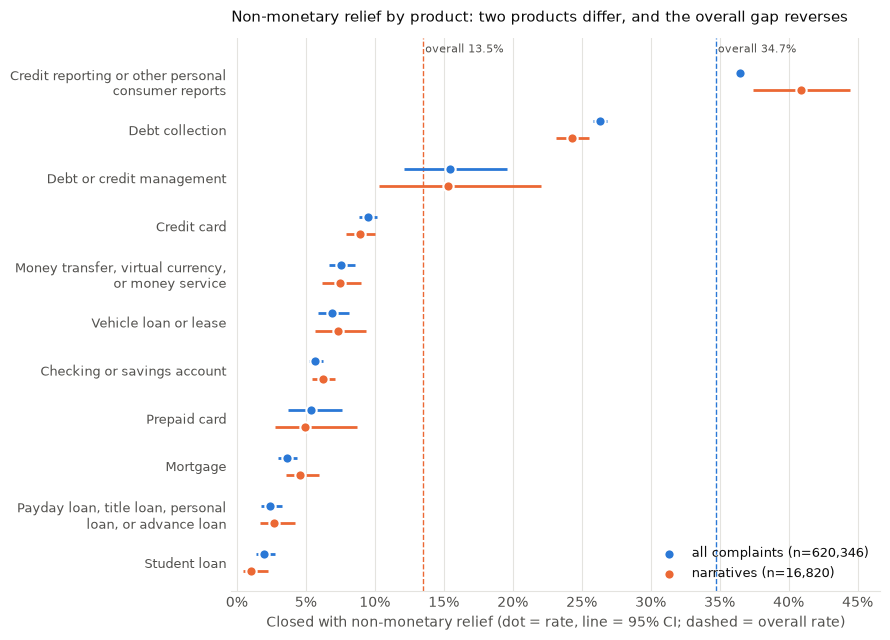

In [11]:
# --- Chart: non-monetary relief by product ---------------------------------
non_monetary_points = {name: relief_points(df_pop, NON_MONETARY) for name, df_pop in populations.items()}

# Checks: n matches relief_table(); monetary + non-monetary counts reproduce its any-relief rate
results = []
for name, df_pop in populations.items():
    expected = relief_table(df_pop, "Product")
    pts = non_monetary_points[name].reindex(expected.index)
    any_k = pts["k"] + monetary_points[name].reindex(expected.index)["k"]
    any_diff = ((100 * any_k / pts["n"]).round(1) - expected["any_relief_%"]).abs().max()
    results += [
        check(f"{name}: n per product matches relief_table", (pts["n"] == expected["n"]).all(),
              f"(expected total {expected['n'].sum():,}, actual {pts['n'].sum():,})"),
        check(f"{name}: monetary + non-monetary = any relief", any_diff == 0,
              f"(max abs difference {any_diff:.1f} points)"),
        check(f"{name}: every rate inside its CI", pts["rate"].between(pts["low"], pts["high"]).all()),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

# Products where the two populations' CIs don't overlap
all_pts = non_monetary_points["all complaints"]
nar_pts = non_monetary_points["narratives"].reindex(all_pts.index)
no_overlap = (nar_pts["low"] > all_pts["high"]) | (nar_pts["high"] < all_pts["low"])
print(f"\nCIs that don't overlap ({no_overlap.sum()} of {len(no_overlap)} products):")
for product in all_pts.index[no_overlap]:
    a, b = all_pts.loc[product], nar_pts.loc[product]
    print(f"  {product}: all {a['rate']:.1f}% ({a['low']:.1f}-{a['high']:.1f}) "
          f"vs. narratives {b['rate']:.1f}% ({b['low']:.1f}-{b['high']:.1f})")

plot_relief_dots(non_monetary_points, xlabel="Closed with non-monetary relief", tick_step=5,
                 title="Non-monetary relief by product: two products differ, and the overall gap reverses")

**Reading the chart**

Read it like the monetary chart above (same unit, CIs and percentage points). Non-monetary relief means the company reported a concrete, non-cash fix, such as correcting a credit report or stopping collection calls (CFPB definition quoted under Relief Patterns). Because each complaint has one closure category, a product's monetary rate (chart above) plus its non-monetary rate (this chart) is its any-relief rate.

**What it shows**

1. **The overall gap reverses.** Narratives have the *lower* overall rate here: 13.5% (2,272 of 16,820) vs. 34.7% (215,435 of 620,346) for all complaints, the opposite of the monetary chart (7.1% vs. 0.5%). The cause is the same product mix: credit reporting has the highest non-monetary rate and is 91.2% of all closed complaints but only 4.5% of narratives.
2. **Two products differ within the product** (their CIs don't overlap):
   - *Credit reporting*: narratives higher, 40.9% (37.4-44.4) vs. 36.5% (36.4-36.6), a 4.4-point gap.
   - *Debt collection*: narratives lower, 24.3% (23.2-25.5) vs. 26.3% (25.8-26.9), a 2.0-point gap.
3. **The other nine products match**, as in the monetary chart.

**Limits.** The data shows that these two gaps exist, not why. The narrative itself, the kind of issue people write about, or how companies respond to written complaints could each play a part; nothing here separates them.

**Implication.** For both relief types, most of the difference between narratives and all complaints comes from product mix; within products, narratives mostly look like all complaints, except credit reporting and debt collection here. What this means for relief as a target is in the next cell.

##### Why Relief Was Not Chosen as the Target

Four reasons, from the tables and charts above:

1. **The classes do not separate cleanly.** If monetary relief is the thing to predict, every other outcome falls into one "not monetary" class. That class would mix *Closed with non-monetary relief* (the company made a concrete fix) with *Closed with explanation*, which CFPB defines as no relief at all. Two very different outcomes would share one label, and which of the two a complaint gets depends on how the company reports its own response.
2. **One class dominates.** *Closed with explanation* is 76.5% of narratives (Target Candidates table above), and monetary relief is 7.1% (1,190 of 16,820). A model that always predicts "no relief" would look accurate without reading anything.
3. **The structured fields already explain most of it.** Product drives the relief rate: monetary relief is about 9-17% for credit card, checking/savings, prepaid card and money transfer, under 4% for the other products, and about 0% for credit reporting. The company matters too: among narratives, Bank of America gave monetary relief in 35.9% of complaints and Wells Fargo in 13.0%. Most of the answer is known before anyone reads the narrative.
4. **Having a narrative makes little difference.** Within a product, complaints with a narrative get relief at about the same rate as all complaints. For monetary relief, every product's confidence intervals overlap; for non-monetary relief, only credit reporting (+4.4 points) and debt collection (-2.0 points) differ. The overall gaps come from product mix.

**Next:** the three remaining candidates, labels the consumer picks to describe their own complaint, so the narrative itself should carry the signal.

#### Candidates 2-4: Product, Sub-product and Issue

With relief set aside, the search moves to the three labels the consumer picks when filing: Product first, then a Sub-product and an Issue from the options that Product offers. Each describes *what the complaint is about*, which is what the narrative is written to explain. The practical question: does each class have enough narratives to train and score a model?

##### Chart: Class Sizes per Target Candidate

One panel per candidate, one dot per class, on a log scale; dashed lines mark `MIN_CLASS_SMALL` (30) and `MIN_CLASS_LARGE` (100) narratives. Counts include duplicate narratives; the deduplicated Issue counts are in Clean > Modeling Set: Issue Class Sizes.

PASS  Product: classes / >=30 / >=100 match the table  (expected (11, 11, 11), actual (11, 11, 11))
PASS  Product: classes add up to all narratives  (16,820 of 16,820)
PASS  Sub-product: classes / >=30 / >=100 match the table  (expected (52, 37, 26), actual (52, 37, 26))
PASS  Sub-product: classes add up to all narratives  (16,820 of 16,820)
PASS  Issue: classes / >=30 / >=100 match the table  (expected (83, 53, 38), actual (83, 53, 38))
PASS  Issue: classes add up to all narratives  (16,820 of 16,820)


,classes >=100,narratives >=100,% >=100,classes 30-99,narratives 30-99,% 30-99,classes <30,narratives <30,% <30
Product,11.0,16820.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
Sub-product,26.0,15927.0,94.7,11.0,673.0,4.0,15.0,220.0,1.3
Issue,38.0,15683.0,93.2,15.0,886.0,5.3,30.0,251.0,1.5


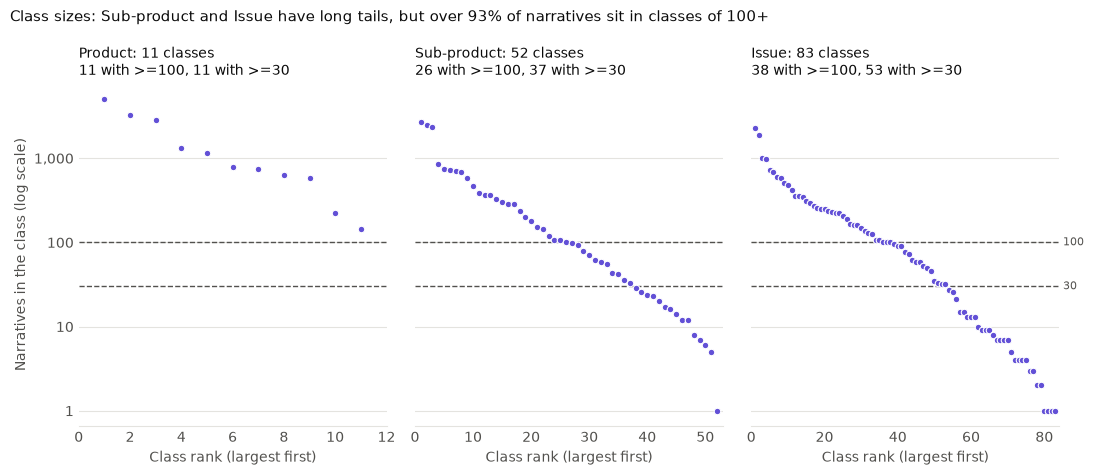

In [12]:
# --- Chart: class sizes per target candidate --------------------------------
CLASS_TARGETS = ["Product", "Sub-product", "Issue"]  # Company response is an outcome, not a "what is it about" label
CLASS_COLOR = "#6250d6"  # palette slot 7; blue/orange stay reserved for all complaints vs. narratives

class_sizes = {col: df_narrative[col].value_counts() for col in CLASS_TARGETS}

# Checks: class counts match the Target Candidates table, and each target's classes cover every narrative
results = []
for col, vc in class_sizes.items():
    row = targets.loc[col]
    expected = (int(row["classes"]), int(row[f"classes_>={MIN_CLASS_SMALL}"]), int(row[f"classes_>={MIN_CLASS_LARGE}"]))
    actual = (len(vc), int((vc >= MIN_CLASS_SMALL).sum()), int((vc >= MIN_CLASS_LARGE).sum()))
    results += [
        check(f"{col}: classes / >=30 / >=100 match the table", actual == expected, f"(expected {expected}, actual {actual})"),
        check(f"{col}: classes add up to all narratives", vc.sum() == len(df_narrative), f"({vc.sum():,} of {len(df_narrative):,})"),
    ]
assert all(results), "A chart check failed; see the FAIL lines above"

# How many classes, and narratives, sit in each class-size band (band_summary is reused in Clean)
def band_summary(vc: pd.Series) -> dict:
    """Classes and narratives in each class-size band."""
    bands_ = {">=100": vc >= MIN_CLASS_LARGE, "30-99": vc.between(MIN_CLASS_SMALL, MIN_CLASS_LARGE - 1), "<30": vc < MIN_CLASS_SMALL}
    out = {}
    for name, mask in bands_.items():
        out[f"classes {name}"] = int(mask.sum())
        out[f"narratives {name}"] = int(vc[mask].sum())
        out[f"% {name}"] = round(100 * vc[mask].sum() / vc.sum(), 1)
    return out


bands = pd.DataFrame({col: band_summary(vc) for col, vc in class_sizes.items()}).T
display(bands)

# Plot: one panel per target, shared log y-axis
fig, axes = plt.subplots(1, 3, figsize=(11, 4.8), sharey=True)
for ax, (col, vc) in zip(axes, class_sizes.items()):
    rank = np.arange(1, len(vc) + 1)
    ax.scatter(rank, vc.values, s=22, color=CLASS_COLOR, edgecolor="white", linewidth=0.8, zorder=3)
    for threshold in [MIN_CLASS_SMALL, MIN_CLASS_LARGE]:
        ax.axhline(threshold, color=INK_MUTED, lw=1, ls="--", zorder=1)
    n30, n100 = int((vc >= MIN_CLASS_SMALL).sum()), int((vc >= MIN_CLASS_LARGE).sum())
    ax.set_title(f"{col}: {len(vc)} classes\n{n100} with >=100, {n30} with >=30", loc="left", fontsize=10, color=INK)
    ax.set_yscale("log")
    ax.set_xlim(0, len(vc) + 1)
    ax.set_xlabel("Class rank (largest first)", color=INK_MUTED)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(which="both", colors=INK_MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

axes[0].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_ylabel("Narratives in the class (log scale)", color=INK_MUTED)
for threshold in [MIN_CLASS_SMALL, MIN_CLASS_LARGE]:
    axes[-1].text(axes[-1].get_xlim()[1], threshold, f" {threshold}", va="center", ha="left", fontsize=8, color=INK_MUTED)
fig.suptitle("Class sizes: Sub-product and Issue have long tails, but over 93% of narratives sit in classes of 100+", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
plt.show()

**How to read the chart**

- **Each dot is one class** (e.g. one Issue), ranked from largest (left) to smallest (right). Its height is how many narratives carry that label.
- **Log scale:** each gridline is 10 times the one below (1, 10, 100, 1,000), so classes of 5 narratives stay visible next to classes of thousands.
- **Dashed lines at 30 and 100** mark how much data a class needs to be scored on its own. A test set gets only part of each class, and small samples give wide confidence intervals: 80% recall measured on 6 test examples has a 95% CI of about 44-97%, on 30 examples about 63-90%. So under 30 a class can't be scored reliably, 30-99 can be scored with wide CIs, and 100+ can be scored on its own. These are rules of thumb, not fixed standards.

**What it shows** (from the table above the chart)

1. **Product:** all 11 classes have at least 100 narratives (smallest: 144), so every class can be scored.
2. **Sub-product:** 26 of 52 classes have 100+, holding 15,927 narratives (94.7%). The 15 classes under 30 hold only 220 narratives (1.3%).
3. **Issue:** 38 of 83 classes have 100+, holding 15,683 narratives (93.2%). The 30 classes under 30 hold only 251 narratives (1.5%).
4. **The long tails are thin.** Sub-product and Issue have many small classes, but those classes hold few narratives.

**Decision: Issue is the target.** It is the label that best fits a model reading the narrative:
- **Most specific.** Product names the kind of account ("Debt collection"); Issue names what went wrong ("Attempts to collect debt not owed"), which is what a narrative is written to explain.
- **Enough data to score.** Its 38 classes of 100+ hold 93.2% of narratives; the 30 classes under 30 hold only 1.5%.

All 83 Issues stay as classes, with no merging into "Other": Issue options depend on Product and Sub-product, so merging or dropping rare classes would remove options consumers actually see (for Payday loans, 18 of the 28 Issues used have under 30 narratives).

### Duplicate Narratives

Some narratives appear more than once. Copies that land in both the training and the test set let the baseline score on text it has already seen, so its results would look better than they are. Two types turn up in the 16,820 narratives:
- **Type 1: the same text filed more than once.** Copies count as the same text after ignoring punctuation and capitals.
- **Type 2: a template.** One script copied over and over with only the collector's name and the account number changed, so the copies are not identical text.

**Result:** both types are removed in Clean. Together with the form check in the next section, 14,755 narratives remain for modeling, still covering all 83 Issues.

#### Type 1: The Same Text Filed More Than Once

Two narratives are copies when their whole text matches after normalizing: lowercase, punctuation turned into spaces, whitespace collapsed. Redaction marks (XXXX) stay, because CFPB applies them to every narrative. The normalized form is used only for matching; the models read the original text.

In [13]:
# --- Duplicates, Type 1: the same text filed more than once -----------------
# Clean reuses comparison_key().
def comparison_key(text: pd.Series) -> pd.Series:
    """Lowercase, punctuation to spaces, collapse whitespace, trim. Redaction marks (XXXX) are kept."""
    return (text.str.lower()
                .str.replace(r"[^\w\s]", " ", regex=True)
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())


texts = df_narrative[NARRATIVE_COL]
narr_key = comparison_key(texts)
exact_extra = int(texts.duplicated().sum())
key_extra = int(narr_key.duplicated().sum())
expected_exact = len(texts) - int(profile.loc[NARRATIVE_COL, "n_unique"])

results = [
    check("exact copies match the structure profile", exact_extra == expected_exact,
          f"(expected {expected_exact:,}, actual {exact_extra:,})"),
    check("normalizing never finds fewer copies", key_extra >= exact_extra, f"(exact {exact_extra:,}, normalized {key_extra:,})"),
    check("no empty keys", (narr_key != "").all(), f"(empty: {(narr_key == '').sum():,})"),
]
assert all(results), "A duplicate check failed; see the FAIL lines above"

print(f"\nExtra copies, exact text:        {exact_extra:,}")
print(f"Extra copies, after normalizing: {key_extra:,} ({100 * key_extra / len(texts):.1f}% of {len(texts):,} narratives)")


def first_difference(a: str, b: str, width: int = 25) -> str:
    """Both texts around the first character where they differ."""
    i = next((k for k, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))
    lo = max(0, i - width)
    return f"{a[lo:i + width]!r}  vs.  {b[lo:i + width]!r}"


# What normalizing adds: texts that differ only in punctuation or capitals
variants = texts.groupby(narr_key).agg(copies="size", raw_texts="nunique")
merged = variants[variants["raw_texts"] > 1].sort_values("copies", ascending=False)
examples = []
for key in merged.index:   # three different kinds of difference, from the most-copied texts
    a, b = sorted(texts[narr_key == key].unique()[:2], key=len)
    diff = first_difference(a, b)
    if diff not in examples:
        examples.append(diff)
    if len(examples) == 3:
        break
print(f"\nNormalizing merges {len(merged):,} groups of slightly different texts, for example:")
for diff in examples:
    print("  ", diff)

# The largest groups: how many copies, and across how many companies
groups = df_narrative.groupby(narr_key).agg(copies=("Complaint ID", "size"), companies=("Company", "nunique"),
                                             issues=("Issue", "nunique"))
repeated = groups[groups["copies"] > 1]
print(f"\nTexts that repeat: {len(repeated):,}, covering {repeated['copies'].sum():,} narratives")
largest = repeated.sort_values("copies", ascending=False).head(5).reset_index(drop=True)
largest["starts_with"] = [texts[narr_key == k].iloc[0][:70] for k in
                          repeated.sort_values("copies", ascending=False).head(5).index]
display(largest)

# Do the copies of a text agree on Issue?
disagree = int((repeated["issues"] > 1).sum())
print(f"Repeated texts whose copies disagree on Issue: {disagree} of {len(repeated):,}")

PASS  exact copies match the structure profile  (expected 1,440, actual 1,440)
PASS  normalizing never finds fewer copies  (exact 1,440, normalized 1,488)
PASS  no empty keys  (empty: 0)

Extra copies, exact text:        1,440
Extra copies, after normalizing: 1,488 (8.8% of 16,820 narratives)

Normalizing merges 44 groups of slightly different texts, for example:
   'gnificant stress and XXXX affecting my mental heal'  vs.  'gnificant stress and XXXX, affecting my mental hea'
   'edit!! Account number is XXXX is falsely reporting'  vs.  'edit!! Account number is # XXXX is falsely reporti'
   'ile a complaint against JEFFERSON CAPITAL LLC for '  vs.  'ile a complaint against Jefferson Capital, LLC for'

Texts that repeat: 329, covering 1,817 narratives


,copies,companies,issues,starts_with
0,278,93,1,This debt collector has engaged in conduct that violates the Fair Debt
1,194,3,1,There are collection accounts on my report that I believe contain inac
2,96,47,1,I am writing to formally request debt validation for a collection acco
3,45,31,1,I am formally disputing the validity of the alleged collection and cha
4,31,18,1,Delete this account because you can not furnish any documentation that


Repeated texts whose copies disagree on Issue: 14 of 329


**Findings**
- **1,440 extra copies of exact text**; normalizing adds 48 more that differ only by a comma, a "#" before a redaction mark, or capitals: **1,488 in all (8.8% of narratives)**.
- The largest groups run to hundreds of copies across dozens of companies (the top text: 278 copies, 93 companies), so some texts look like shared scripts rather than one person's complaint.
- Copies almost always agree on Issue: 14 of 329 repeated texts disagree.

#### Type 2: The Template Family

One script recurs with only the collector's name and the redacted account number changed, so Type 1 cannot merge the copies:

> *"[collector] is falsely reporting on my credit. I have never had any accounts with them. Per my research [collector] is a debt collector..."*

A narrative belongs to the family when it contains at least 2 of the script's 4 fixed sentences (2, not 4, because some copies have typos or are cut off).

In [14]:
# --- Duplicates, Type 2: the template family -------------------------------
# Clean reuses these definitions.
# The script's four fixed sentences, in comparison-key form (lowercase, no punctuation)
TEMPLATE_SIGNATURES = [
    "is falsely reporting on my credit i have never had any accounts with them",
    "is a debt collector they are falsely reporting on my credit",
    "is falsely reporting to my credit file and is against my rights and fair credit act",
    "of investigation consumer report you are in violation",
]
TEMPLATE_MIN_HITS = 2  # 2 of 4 tolerates the typos and cut-off text seen in some copies


def template_signature_hits(key: pd.Series) -> pd.Series:
    """Number of template sentences each comparison key contains (0 to len(TEMPLATE_SIGNATURES))."""
    return sum(key.str.contains(sig, regex=False).astype(int) for sig in TEMPLATE_SIGNATURES)


template_hits = template_signature_hits(narr_key)
is_template = template_hits >= TEMPLATE_MIN_HITS
family_rows = df_narrative[is_template]
n_partial = int(template_hits.between(1, TEMPLATE_MIN_HITS - 1).sum())

results = [
    check("family found", is_template.any(),
          f"({len(family_rows):,} complaints, {narr_key[is_template].nunique():,} different texts after normalizing)"),
    check("no narrative sits just below the threshold", n_partial == 0, f"(expected 0, actual {n_partial:,})"),
]
assert all(results), "A template-family check failed; see the FAIL lines above"
print("Fixed sentences matched per complaint:", template_hits[is_template].value_counts().sort_index().to_dict())

# Two copies: the same script with a different collector's name
print()
for key in narr_key[is_template].value_counts().index[:2]:
    print(textwrap.fill(texts[narr_key == key].iloc[0], width=110), "\n")

# Same labels, different filers
cols = ["Product", "Sub-product", "Issue", "Sub-issue", "Submitted via", "Company", "State", "ZIP code", "Date received"]
family_profile = pd.DataFrame({
    "distinct values": family_rows[cols].nunique(),
    "most common": family_rows[cols].mode().iloc[0],
    "most common %": (100 * family_rows[cols].apply(lambda s: s.value_counts().iloc[0]) / len(family_rows)).round(1),
})
display(family_profile)

PASS  family found  (322 complaints, 149 different texts after normalizing)
PASS  no narrative sits just below the threshold  (expected 0, actual 0)
Fixed sentences matched per complaint: {2: 1, 3: 13, 4: 308}

CREDIT COLL is falsely reporting on my credit. I have never had any accounts with them. Per my research CREDIT
COLL is a debt collector. They are falsely reporting on my credit!! Account number is # XXXX is falsely
reporting to my credit file and is against my rights and fair credit act. Under U.S Code 1618d - Disclosure of
investigation consumer report ; you are in violation. 

JEFFCAPSYS is falsely reporting on my credit. I have never had any accounts with them. Per my research
JEFFCAPSYS is a debt collector. They are falsely reporting on my credit!! Account number is XXXX is falsely
reporting to my credit file and is against my rights and fair credit act. Under U.S Code 1618d - Disclosure of
investigation consumer report ; you are in violation. 



,distinct values,most common,most common %
Product,1,Debt collection,100.0
Sub-product,1,I do not know,100.0
Issue,1,Attempts to collect debt not owed,100.0
Sub-issue,2,Debt was result of identity theft,99.4
Submitted via,1,Web,100.0
Company,28,CL Holdings LLC,22.0
State,27,FL,21.4
ZIP code,186,61821,4.0
Date received,20,2026-06-09,14.6


**Findings**
- **322 complaints (149 different texts, 1.9% of narratives)** follow the script.
- **The labels are identical:** all are Debt collection / Sub-product "I do not know" / Issue "Attempts to collect debt not owed", and 99.4% have Sub-issue "Debt was result of identity theft". All came through the web form.
- **The filers are not:** 186 ZIP codes, 27 states, 28 companies and 20 filing dates. A single filer is unlikely; an advocacy group or credit-repair service handing out a script would fit, but the data cannot say who wrote it.

#### Decision

Clean applies these rules to the narratives and logs every drop:
1. **Template family: drop every copy.** Keeping one copy per variant would still leave many near-identical texts with one shared label, which would give the baseline easy answers if they split across train and test.
2. **Copies that disagree on Issue: keep the majority Issue**, and drop the text on a tie (7 texts). The same words carry different labels, so the label a model learns from them is uncertain.
3. **All other copies: keep one per normalized text**, the first in file order.

**Result:** with the form check in the next section, 14,755 narratives remain for modeling, still covering all 83 Issues. The Explore sections keep every row, since each complaint is a real filing.

**Limitations.** Only this one template was searched for by its wording. Other scripts that vary in more than formatting would survive as separate narratives; similarity matching (e.g. TF-IDF cosine) could look for them.

### Issues vs. the Complaint Form

A consumer picks a Product and Sub-product first; the form then offers a fixed menu of Issues for that pair. The CFPB publishes every menu in its complaint form options document (`reference/cfpb_consumer_complaint_form_product_issue_options_August_2023_FINAL.pdf`, August 2023, the latest major revision). If the data agree with the form, every narrative's Issue is on its menu.

Checking 16,820 narratives against a 40-page PDF by hand is not practical, so Claude Code ran the check in code: the first cell reads the form's tables into menus (the parser from Assignment 7), the second compares each narrative's Issue to its menu. Modeling reuses the same menus as the options in the LLM prompt.

In [15]:
# --- Explore: read the complaint form into Issue menus ------------------------
# Result: printed_menus, (Product, Sub-product) -> {Issue: the form's description}. Clean and Modeling reuse it.
# How it works: a PDF stores each piece of text with its position, font and size. The form's product pages are
# tables (sub-product | issue | sub-issue), so each piece is placed in a column by its x position, and the
# formatting tells what it is: bold 12pt = sub-product name, a Wingdings bullet = start of an Issue.

# Layout of the form's product pages (measured from the PDF; units are PDF points)
FORM_PAGES = range(6, 39)     # product tables; later pages are the change-log appendix
SUB_COL_MAX_X = 280           # sub-product column is left of this
ISSUE_COL_MAX_X = 600         # issue column sits between the two; sub-issues start at x=613 or later
TABLE_TOP_Y = 500             # text above this is the page title
WRAP_GAP = 16                 # a label line this close below another label is the same name, wrapped
GROUP_GAP = 35                # sub-products this close share one issue list; a wider gap starts a new row

# Form spelling -> data spelling
SUBPRODUCT_RENAMES = {
    "CD": "CD (Certificate of Deposit)",
    "International money transfer (remittance)": "International money transfer",
    "Federal student loan": "Federal student loan servicing",
}
ISSUE_RENAMES = {"Charged up-front or unexpected fees": "Charged upfront or unexpected fees"}
# A starred option is not a real Issue: this one sends the consumer to the credit reporting product
CREDIT_REPORT_REDIRECT = "Problem with credit report or credit score"

CHANGE_NOTE = re.compile(r"\(\s*(added|revised|moved|split|removed)\s*\)", re.IGNORECASE)


def clean_form_text(text):
    """Join line breaks, straighten curly quotes, drop change notes like '(added)'."""
    text = text.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    return re.sub(r"\s+", " ", CHANGE_NOTE.sub("", text)).strip()


def split_description(text):
    """'Managing an account (deposits, ...)' -> ('Managing an account', 'deposits, ...')."""
    match = re.match(r"^(.*?)\s*\((.*)\)$", text)
    return (match.group(1), match.group(2)) if match else (text, "")


def page_lines(page):
    """The page title and its table text as lines (column, y, runs), top to bottom."""
    runs = []

    def visit(text, cm, tm, font, size):
        if text.strip():
            scale = (tm[0] or 1) * (cm[0] or 1)
            runs.append({"x": tm[4] * (cm[0] or 1) + cm[4], "y": tm[5] * (cm[3] or 1) + cm[5],
                         "size": round(size * scale, 1), "text": text.strip(),
                         "font": str(font.get("/BaseFont", "")).split("+")[-1] if font else ""})

    page.extract_text(visitor_text=visit)
    title = " ".join(r["text"] for r in runs if r["size"] == 24.0)
    lines = defaultdict(list)
    for r in runs:
        is_header = r["text"] in ("Issue", "Sub-issue") or r["text"].startswith("Sub-product")
        if r["y"] >= TABLE_TOP_Y or r["size"] not in (11.0, 12.0) or is_header:
            continue
        column = "sub" if r["x"] < SUB_COL_MAX_X else "issue" if r["x"] < ISSUE_COL_MAX_X else "subissue"
        lines[(column, round(r["y"]))].append(r)
    ordered = sorted(lines.items(), key=lambda kv: -kv[0][1])
    return title, [(col, y, sorted(rs, key=lambda r: r["x"])) for (col, y), rs in ordered]


def parse_page(page):
    """The page's product and its rows: each row has sub-product labels and the issues they share."""
    product, lines = page_lines(page)

    # Sub-product column: labels (12pt bold), their descriptions (11pt), and '(continued)' (italic)
    rows, prev_y, prev_was_label = [], None, False
    for col, y, rs in (l for l in lines if l[0] == "sub"):
        continued = any("Italic" in r["font"] and "continued" in r["text"].lower() for r in rs)
        rs = [r for r in rs if not ("Italic" in r["font"] and "continued" in r["text"].lower())]
        if not rs:
            rows[-1]["continued"] = True
            continue
        text = " ".join(r["text"] for r in rs)
        gap = None if prev_y is None else prev_y - y
        prev_y = y
        if not any(r["size"] == 12.0 for r in rs):
            prev_was_label = False                        # description under a label
            continue
        if prev_was_label and gap <= WRAP_GAP:
            rows[-1]["labels"][-1] += " " + text          # long name wrapped onto a second line
        elif gap is not None and gap <= GROUP_GAP:
            rows[-1]["labels"].append(text)               # another sub-product sharing this row's issues
        else:
            rows.append({"labels": [text], "continued": False, "top": y, "issues": []})
        rows[-1]["continued"] |= continued
        prev_was_label = True

    # Issue column: each issue starts at a bullet marker; lines without a marker continue it
    issues = []
    for col, y, rs in (l for l in lines if l[0] == "issue"):
        text = " ".join(r["text"] for r in rs if not r["font"].startswith("Wingdings"))
        if any(r["font"].startswith("Wingdings") for r in rs):
            issues.append({"y": y, "text": text})
        elif issues:
            issues[-1]["text"] += " " + text
        else:
            raise ValueError(f"Issue text before the first issue marker: {text!r}")
    for issue in issues:   # an issue belongs to the lowest row that starts at or above it
        [r for r in rows if r["top"] + 3 >= issue["y"]][-1]["issues"].append(issue["text"])
    return product, rows


# Read every product page; merge rows that continue from the previous page
reader = PdfReader(FORM_PATH)
form_rows = []
for page_no in FORM_PAGES:
    product, rows = parse_page(reader.pages[page_no - 1])
    for row in rows:
        if row["continued"] and form_rows and form_rows[-1]["product"] == product:
            # The first label is the "(continued)" pointer (a repeated name, or "Mortgages");
            # any other label is a sub-product joining the row
            prev = form_rows[-1]
            prev["issues"] += row["issues"]
            known = {clean_form_text(l) for l in prev["labels"]}
            prev["labels"] += [l for l in row["labels"][1:] if clean_form_text(l) not in known]
        else:
            form_rows.append({"product": product, "labels": row["labels"], "issues": row["issues"]})

# Menus exactly as the form prints them; starred options (redirects, dead ends) are skipped,
# but the menus that offer the credit report redirect are noted
printed_menus, redirect_menus = {}, set()
for row in form_rows:
    menu, has_redirect = {}, False
    for raw in row["issues"]:
        text = clean_form_text(raw)
        if text.endswith("*"):
            has_redirect |= text.rstrip("*").strip() == CREDIT_REPORT_REDIRECT
            continue
        name, description = split_description(text)
        menu.setdefault(ISSUE_RENAMES.get(name, name), description)
    for label in row["labels"]:
        sub_product = SUBPRODUCT_RENAMES.get(clean_form_text(label), clean_form_text(label))
        printed_menus[(row["product"], sub_product)] = menu
        if has_redirect:
            redirect_menus.add((row["product"], sub_product))

# Assignment 7 found 55 menus and 328 options; a different number means the PDF or the parser changed
n_options = sum(len(m) for m in printed_menus.values())
results = [
    check("menus read from the form", len(printed_menus) == 55, f"(expected 55, actual {len(printed_menus)})"),
    check("Issue options read from the form", n_options == 328, f"(expected 328, actual {n_options})"),
]
assert all(results), "A form check failed; see the FAIL lines above"
print(f"\n{len(redirect_menus)} menus offer the starred '{CREDIT_REPORT_REDIRECT}' redirect")
example = ("Credit card", "General-purpose credit card or charge card")
print(f"\nExample menu, {example[0]} / {example[1]}:")
for issue in printed_menus[example]:
    print("  -", issue)


PASS  menus read from the form  (expected 55, actual 55)
PASS  Issue options read from the form  (expected 328, actual 328)

23 menus offer the starred 'Problem with credit report or credit score' redirect

Example menu, Credit card / General-purpose credit card or charge card:
  - Getting a credit card
  - Advertising and marketing, including promotional offers
  - Trouble using your card
  - Fees or interest
  - Problem with a purchase shown on your statement
  - Problem when making payments
  - Struggling to pay your bill
  - Closing your account
  - Other features, terms, or problems


In [16]:
# --- Explore: each narrative's Issue vs. its form menu ----------------------
# Clean reuses on_form_menu().
MENU_ISSUES = {(product, sub, issue) for (product, sub), menu in printed_menus.items() for issue in menu}


def on_form_menu(df: pd.DataFrame) -> pd.Series:
    """True where the row's Issue is on the form's menu for its Product and Sub-product."""
    triples = zip(df["Product"].astype(str), df["Sub-product"].astype(str), df["Issue"].astype(str))
    return pd.Series([t in MENU_ISSUES for t in triples], index=df.index)


narrative_pairs = set(zip(df_narrative["Product"], df_narrative["Sub-product"]))
missing_pairs = narrative_pairs - set(printed_menus)
is_off_menu = ~on_form_menu(df_narrative)
off_menu = df_narrative[is_off_menu]
credit_report_issues = set(printed_menus[("Credit reporting or other personal consumer reports", "Credit reporting")])
off_menu_pairs = set(zip(off_menu["Product"], off_menu["Sub-product"]))

results = [
    check("every narrative's Product / Sub-product has a form menu", not missing_pairs,
          f"(missing: {missing_pairs or 'none'})"),
    check("off-menu Issues found", is_off_menu.any(),
          f"({len(off_menu):,} of {len(df_narrative):,} narratives, {is_off_menu.mean():.1%})"),
    check("every off-menu Issue is a credit reporting option", off_menu["Issue"].isin(credit_report_issues).all(),
          f"({off_menu['Issue'].nunique()} different Issues)"),
    check("every off-menu narrative's menu offers the credit report redirect", off_menu_pairs <= redirect_menus,
          f"({len(off_menu_pairs)} menus, all among the {len(redirect_menus)} with the redirect)"),
]
assert all(results), "A form-menu check failed; see the FAIL lines above"

# Where they sit: counts by Product, then by Issue
by_product = off_menu["Product"].astype(str).value_counts().rename("narratives").to_frame()
by_product.loc["Total"] = by_product["narratives"].sum()
print()
display(by_product)
print("By Issue:")
print(off_menu["Issue"].astype(str).value_counts().to_string(header=False))

# One per Product: what the consumer wrote
print("\nOne narrative per Product (first 400 characters):")
for _, row in off_menu.groupby("Product", observed=True).sample(n=1, random_state=SEED).iterrows():
    excerpt = row[NARRATIVE_COL][:400] + ("..." if len(row[NARRATIVE_COL]) > 400 else "")
    print(f"\n--- {row['Product']} / {row['Sub-product']} | Issue: {row['Issue']} | {row['Company']}")
    print(textwrap.fill(excerpt, width=110))


PASS  every narrative's Product / Sub-product has a form menu  (missing: none)
PASS  off-menu Issues found  (428 of 16,820 narratives, 2.5%)
PASS  every off-menu Issue is a credit reporting option  (6 different Issues)
PASS  every off-menu narrative's menu offers the credit report redirect  (17 menus, all among the 23 with the redirect)



,narratives
Product,
Credit card,184
Student loan,74
Vehicle loan or lease,72
Mortgage,43
"Payday loan, title loan, personal loan, or advance loan",36
Checking or savings account,19
Total,428


By Issue:
Incorrect information on your report                               214
Problem with a company's investigation into an existing problem    151
Improper use of your report                                         35
Credit monitoring or identity theft protection services             17
Problem with fraud alerts or security freezes                        8
Unable to get your credit report or credit score                     3

One narrative per Product (first 400 characters):

--- Checking or savings account / Other banking product or service | Issue: Problem with a company's investigation into an existing problem | CAPITAL ONE FINANCIAL CORPORATION
I am filing a complaint against Capital One banking because they have restricted and closed all my bank and
credit card accounts due to a fraudulent mobile deposit that was completely unauthorized. My personal data was
severely compromised ; unauthorized third parties gained access to my mobile device and compromised my primary
email 

**Findings**
- **428 narratives (2.5%) have an Issue that is not on their Product / Sub-product menu.** All other narratives match the form.
- **All 428 use an option from the credit reporting product's list** (mostly "Incorrect information on your report" and "Problem with a company's investigation into an existing problem"), under credit cards, student loans, mortgages, vehicle loans, personal loans and bank accounts.
- **Each sits under a menu that offers the starred redirect** "Problem with credit report or credit score". The form's footnote says choosing it "will take the consumer to the credit reporting product", so these complaints should be filed under credit reporting, yet they kept their original Product. The data do not say why.
- **Most sampled narratives are about credit reports,** with the lender as the one reporting to the bureaus; one (Capital One closing a customer's accounts after a fraudulent deposit) reads more like the original product.

**Decision:** Clean drops the 428, right after keeping narratives and before the duplicate rules. Their Product and Issue contradict the form, so neither model can learn a consistent label from them, and the LLM, which picks from the form's menu, could never give their recorded Issue.

## Clean

`clean_ccdb()` builds the modeling set, `df_clean`, from the raw export in one function, so it can be rerun on another export. `df_raw` is never modified. Three stages:
1. **Rows:** narratives only, then Issues the form does not offer (*Issues vs. the Complaint Form*), then the duplicate rules from *Duplicate Narratives > Decision*.
2. **Columns:** only the columns the models need, each with a role (`COLUMN_ROLES`):

| Role | Columns | Why |
|---|---|---|
| id | Complaint ID | join key |
| input | narrative | what both models read |
| target | Issue | what they predict |
| context | Product, Sub-product | given to the LLM with the narrative |
| subgroup | Company, State, Date received, Older American, Servicemember | for the sub-group evaluation |

   Dropped: Sub-issue, a finer split of Issue chosen after it, would give the target away; Company response to consumer, Company public response, Timely response? and Date sent to company are known only after the company responds. Any of them can be added back if the evaluation needs it.
3. **Types:** label columns become categories; the narrative stays text.

In [17]:
# --- Cleaning pipeline -----------------------------------------------------
# Every column the modeling set keeps, and its role (Older American / Servicemember are split out of Tags)
COLUMN_ROLES = {
    "Complaint ID": "id",
    "Consumer complaint narrative": "input",
    "Issue": "target",
    "Product": "context",
    "Sub-product": "context",
    "Company": "subgroup",
    "State": "subgroup",
    "Date received": "subgroup",
    "Older American": "subgroup",
    "Servicemember": "subgroup",
}
CATEGORY_COLS = ["Issue", "Product", "Sub-product", "Company", "State"]


def clean_ccdb(raw):
    """Build the modeling set from a raw CCDB export read with dtype=str.

    Returns (cleaned DataFrame, row funnel). The input is not modified.
    """
    funnel = [("raw export", len(raw))]

    # 1. Rows: narratives only, then Issues the form does not offer (Explore > Issues vs. the Complaint Form),
    #    then the duplicate rules (Explore > Duplicate Narratives > Decision)
    df = raw[raw[NARRATIVE_COL].fillna("").str.strip() != ""].copy()
    funnel.append(("narratives only", len(df)))

    df = df[on_form_menu(df)]
    funnel.append(("Issue not on form menu", len(df)))
    key = comparison_key(df[NARRATIVE_COL]).rename("key")

    template = template_signature_hits(key) >= TEMPLATE_MIN_HITS
    df, key = df[~template], key[~template]
    funnel.append(("template family", len(df)))

    votes = pd.crosstab(key, df["Issue"])                       # one row per text: copies per Issue
    is_tie = votes.eq(votes.max(axis=1), axis=0).sum(axis=1) > 1  # two or more Issues share the top count
    tied = key.map(is_tie)
    df, key = df[~tied], key[~tied]
    funnel.append(("Issue ties", len(df)))

    minority = df["Issue"] != key.map(votes.idxmax(axis=1))     # copy outvoted by its text's majority Issue
    df, key = df[~minority], key[~minority]
    funnel.append(("minority Issue", len(df)))

    df = df[~key.duplicated(keep="first")]                       # one copy per text, first in file order
    funnel.append(("duplicate texts", len(df)))

    # 2. Columns: Tags -> two yes/no flags, Date received -> datetime, keep only the role columns
    tags = df["Tags"].fillna("")
    unknown_tags = set(tags.str.split(", ").explode()) - {"", "Older American", "Servicemember"}
    assert not unknown_tags, f"Unexpected Tags values: {unknown_tags}"
    df["Older American"] = tags.str.contains("Older American", regex=False)
    df["Servicemember"] = tags.str.contains("Servicemember", regex=False)
    df["Date received"] = pd.to_datetime(df["Date received"], format="%Y-%m-%d")  # stops on any other format
    df = df[list(COLUMN_ROLES)]

    # 3. Types: label columns become categories; the narrative stays text
    df[CATEGORY_COLS] = df[CATEGORY_COLS].astype("category")

    funnel = pd.DataFrame(funnel, columns=["step", "rows left"])
    funnel["dropped"] = (-funnel["rows left"].diff()).astype("Int64")
    return df, funnel

In [18]:
# --- Run cleaning + checks -------------------------------------------------
df_clean, funnel = clean_ccdb(df_raw)
display(funnel)

# The rules restated from the Explore variables (is_off_menu, narr_key, is_template), to check df_clean against
explore_keep = ~is_off_menu & ~is_template
explore_key, explore_issue = narr_key[explore_keep], df_narrative.loc[explore_keep, "Issue"]
votes = pd.crosstab(explore_key, explore_issue)
tied_texts = votes.index[votes.eq(votes.max(axis=1), axis=0).sum(axis=1) > 1]
clean_key = comparison_key(df_clean[NARRATIVE_COL])
received = df_clean["Date received"]
step = funnel.set_index("step")

results = [
    check("narratives match Explore", step.loc["narratives only", "rows left"] == len(df_narrative),
          f"(expected {len(df_narrative):,}, actual {step.loc['narratives only', 'rows left']:,})"),
    check("off-menu rows dropped match Explore", step.loc["Issue not on form menu", "dropped"] == is_off_menu.sum(),
          f"(expected {is_off_menu.sum():,}, actual {step.loc['Issue not on form menu', 'dropped']:,})"),
    check("template rows dropped match Explore",
          step.loc["template family", "dropped"] == (is_template & ~is_off_menu).sum(),
          f"(expected {(is_template & ~is_off_menu).sum():,}, actual {step.loc['template family', 'dropped']:,})"),
    check("every non-template text kept once, except Issue ties",
          set(clean_key) == set(explore_key) - set(tied_texts) and clean_key.is_unique,
          f"(expected {explore_key.nunique() - len(tied_texts):,}, actual {len(df_clean):,})"),
    check("each kept text has its majority Issue",
          (df_clean["Issue"].astype(str).values == votes.idxmax(axis=1).reindex(clean_key).values).all()),
    check("every Issue is on its form menu", on_form_menu(df_clean).all()),
    check("no template narratives remain", (template_signature_hits(clean_key) < TEMPLATE_MIN_HITS).all()),
    check("Complaint ID unique", df_clean["Complaint ID"].is_unique),
    check("Date received within June 2026", received.between("2026-06-01", "2026-06-30").all(),
          f"({received.min():%Y-%m-%d} to {received.max():%Y-%m-%d})"),
    check("columns match COLUMN_ROLES", list(df_clean.columns) == list(COLUMN_ROLES)),
    check("df_raw untouched", list(df_raw.columns) == EXPECTED_COLS and len(df_raw) == 620_794),
]
assert all(results), "A cleaning check failed; see the FAIL lines above"

print(f"\nModeling set: {len(df_clean):,} narratives, {df_clean['Issue'].nunique():,} Issue classes, "
      f"{df_clean.shape[1]} columns")

,step,rows left,dropped
0,raw export,620794,<NA>
1,narratives only,16820,603974
2,Issue not on form menu,16392,428
3,template family,16070,322
4,Issue ties,16054,16
5,minority Issue,16048,6
6,duplicate texts,14755,1293


PASS  narratives match Explore  (expected 16,820, actual 16,820)
PASS  off-menu rows dropped match Explore  (expected 428, actual 428)
PASS  template rows dropped match Explore  (expected 322, actual 322)
PASS  every non-template text kept once, except Issue ties  (expected 14,755, actual 14,755)
PASS  each kept text has its majority Issue  
PASS  every Issue is on its form menu  
PASS  no template narratives remain  
PASS  Complaint ID unique  
PASS  Date received within June 2026  (2026-06-01 to 2026-06-30)
PASS  columns match COLUMN_ROLES  
PASS  df_raw untouched  

Modeling set: 14,755 narratives, 83 Issue classes, 10 columns


### Modeling Set: Issue Class Sizes

The Target Candidates chart counted every narrative, duplicates included; this chart repeats the Issue panel on `df_clean`, the modeling set (off-menu Issues and duplicates removed), with the earlier count shown for comparison. Same thresholds: `MIN_CLASS_SMALL` (30) and `MIN_CLASS_LARGE` (100).

PASS  after adds up to the modeling set  (expected 14,755, actual 14,755)
PASS  no class grows  (min dropped: 0)
PASS  no class disappears  (83 of 83 classes left)


,classes >=100,narratives >=100,% >=100,classes 30-99,narratives 30-99,% 30-99,classes <30,narratives <30,% <30
all narratives,38,15683,93.2,15,886,5.3,30,251,1.5
modeling set,38,13656,92.6,15,884,6.0,30,215,1.5


Largest drops:


,before,after,dropped,dropped_%
Issue,,,,
Attempts to collect debt not owed,2297,1660,637,27.7
Incorrect information on your report,587,221,366,62.4
Written notification about debt,974,652,322,33.1
Took or threatened to take negative or legal action,688,373,315,45.8
Problem with a company's investigation into an existing problem,298,104,194,65.1


Classes under 30 in the modeling set: 30 (215 narratives, 251 before)
Lost any narratives: 4 of 30
  Credit monitoring or identity theft protection services: 21 -> 2
  Problem with fraud alerts or security freezes: 15 -> 2
  Unable to get your credit report or credit score: 4 -> 1
  Problem with a company's investigation into an existing issue: 2 -> 1


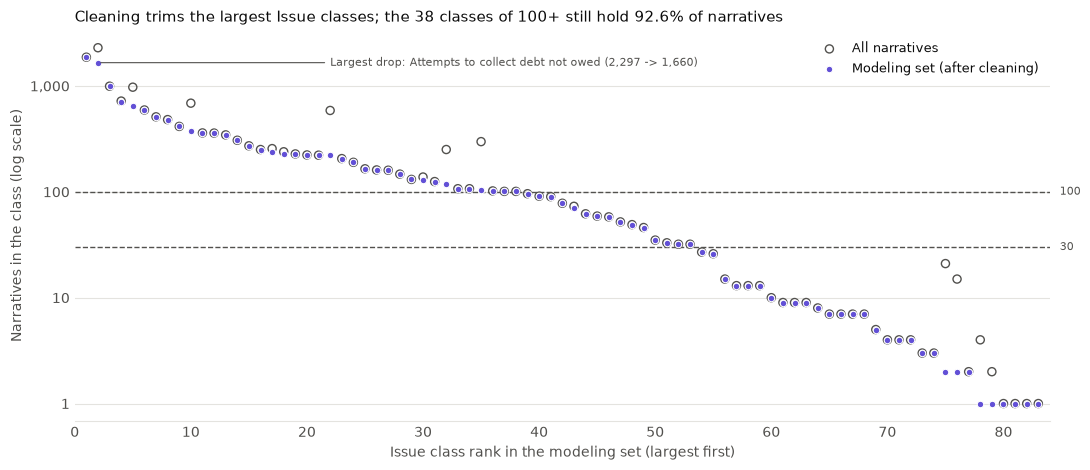

In [19]:
# --- Chart: Issue class sizes in the modeling set -----------------------------
# Same thresholds as the Target Candidates chart; "before" = all narratives, "after" = df_clean.
issue_before = class_sizes["Issue"]  # counted in the Target Candidates class-size chart
issue_after = df_clean["Issue"].value_counts()
issue_after = issue_after[issue_after > 0]  # a category column also lists empty categories

issue_sizes = (pd.DataFrame({"before": issue_before, "after": issue_after}).fillna(0).astype(int)
               .sort_values(["after", "before"], ascending=False))
issue_sizes["dropped"] = issue_sizes["before"] - issue_sizes["after"]
issue_sizes["dropped_%"] = (100 * issue_sizes["dropped"] / issue_sizes["before"]).round(1)

results = [
    check("after adds up to the modeling set", issue_after.sum() == len(df_clean),
          f"(expected {len(df_clean):,}, actual {issue_after.sum():,})"),
    check("no class grows", (issue_sizes["dropped"] >= 0).all(), f"(min dropped: {issue_sizes['dropped'].min()})"),
    check("no class disappears", (issue_sizes["after"] > 0).all(), f"({len(issue_after)} of {len(issue_before)} classes left)"),
]
assert all(results), "A chart check failed; see the FAIL lines above"


# band_summary() is defined in the Target Candidates class-size chart
issue_bands = pd.DataFrame([band_summary(issue_before), band_summary(issue_after)], index=["all narratives", "modeling set"])
display(issue_bands)

# Classes that lost the most narratives
print("Largest drops:")
display(issue_sizes.sort_values("dropped", ascending=False).head(5))

# The rare classes: how many lost any narratives
rare = issue_sizes[issue_sizes["after"] < MIN_CLASS_SMALL]
lost = rare[rare["dropped"] > 0]
print(f"Classes under {MIN_CLASS_SMALL} in the modeling set: {len(rare)} "
      f"({rare['after'].sum():,} narratives, {rare['before'].sum():,} before)")
print(f"Lost any narratives: {len(lost)} of {len(rare)}")
for issue, before, after in zip(lost.index, lost["before"], lost["after"]):
    print(f"  {issue}: {before} -> {after}")

# Plot: modeling-set count per class (violet), with the all-narratives count as a hollow gray ring
rank = np.arange(1, len(issue_sizes) + 1)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.scatter(rank, issue_sizes["before"], s=34, facecolor="none", edgecolor=INK_MUTED, linewidth=1, zorder=2,
           label="All narratives")
ax.scatter(rank, issue_sizes["after"], s=22, color=CLASS_COLOR, edgecolor="white", linewidth=0.8, zorder=3,
           label="Modeling set (after cleaning)")
for threshold in [MIN_CLASS_SMALL, MIN_CLASS_LARGE]:
    ax.axhline(threshold, color=INK_MUTED, lw=1, ls="--", zorder=1)
    ax.text(len(issue_sizes) + 1.5, threshold, f" {threshold}", va="center", ha="left", fontsize=8, color=INK_MUTED)

top_drop = issue_sizes["dropped"].idxmax()
r = issue_sizes.index.get_loc(top_drop) + 1
ax.annotate(f"Largest drop: {top_drop} ({issue_sizes.loc[top_drop, 'before']:,} -> {issue_sizes.loc[top_drop, 'after']:,})",
            (r, issue_sizes.loc[top_drop, "after"]), xytext=(22, issue_sizes.loc[top_drop, "after"]), textcoords="data",
            va="center", fontsize=8, color=INK_MUTED, arrowprops={"arrowstyle": "-", "color": INK_MUTED, "lw": 0.8})

ax.set_yscale("log")
ax.set_xlim(0, len(issue_sizes) + 1)
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Issue class rank in the modeling set (largest first)", color=INK_MUTED)
ax.set_ylabel("Narratives in the class (log scale)", color=INK_MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(which="both", colors=INK_MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(frameon=False, loc="upper right", fontsize=9, labelcolor=INK)
ax.set_title(f"Cleaning trims the largest Issue classes; the {issue_bands.loc['modeling set', 'classes >=100']} classes "
             f"of 100+ still hold {issue_bands.loc['modeling set', '% >=100']}% of narratives", loc="left", fontsize=11, color=INK)
fig.tight_layout()
plt.show()

**Reading the chart**

- **One column per Issue class**, ranked by its size in the modeling set (largest on the left), on the same log scale as the Target Candidates chart.
- **Violet dot:** narratives in the modeling set. **Gray ring:** all narratives, before cleaning. Where the ring sits above the dot, that class lost copies; where they overlap, it lost none.
- **Dashed lines** at 30 and 100 narratives, the same scoring thresholds as before.

**What it shows** (from the tables above the chart)

1. **The bands did not change:** 38 classes still have 100+ narratives (13,656, 92.6% of the modeling set), 15 have 30-99 (884, 6.0%), and 30 have under 30 (215, 1.5%).
2. **The drops sit in a few large classes.** In debt collection, duplicates: *Attempts to collect debt not owed* lost 637 (27.7%, including the 322 template complaints), *Written notification about debt* 322 (33.1%), and *Took or threatened to take negative or legal action* 315 (45.8%). In credit reporting, duplicates plus mostly the off-menu rows: *Incorrect information on your report* lost 366 (62.4%), *Problem with a company's investigation into an existing problem* 194 (65.1%) and *Improper use of your report* 132 (52.6%).
3. **The tail is mostly untouched.** The 30 classes under 30 narratives held 251 narratives before cleaning and 215 after; 26 of them lost none. Two credit-reporting classes shrink sharply because most of their narratives were off-menu: *Credit monitoring or identity theft protection services* (21 to 2) and *Problem with fraud alerts or security freezes* (15 to 2).

**The decision holds:** after cleaning, no Issue drops out and no class falls into a lower size band, so all 83 stay as classes. Rare classes are examined in the sub-group evaluation, after the overall results.

### Cleaned Data Dictionary

One row per column of `df_clean`, the modeling set. `role` comes from `COLUMN_ROLES` in Clean; `dtype`, `null_%` and `n_unique` are read off `df_clean`; `cleaning_applied` says what Clean did to the column. Row-level rules (narratives only, duplicates) are in the row funnel under Clean.

In [20]:
# --- Cleaned data dictionary -------------------------------------------------
# What Clean did to each kept column
CLEANING_APPLIED = {
    "Complaint ID": "None; unique key",
    "Consumer complaint narrative": "None; the text is unchanged.",
    "Issue": "Copies of one text that disagreed: majority Issue kept, ties dropped; to category",
    "Product": "To category",
    "Sub-product": "To category; 'I do not know' kept as its own value",
    "Company": "To category",
    "State": "To category",
    "Date received": "Text (YYYY-MM-DD) to datetime",
    "Older American": "Yes/no flag split out of Tags",
    "Servicemember": "Yes/no flag split out of Tags",
}
assert list(CLEANING_APPLIED) == list(df_clean.columns), "Dictionary doesn't match df_clean's columns (names or order)"

clean_dict = pd.DataFrame({
    "role": pd.Series(COLUMN_ROLES),
    "dtype": df_clean.dtypes.astype(str),
    "null_%": (100 * df_clean.isna().mean()).round(1),
    "n_unique": df_clean.nunique(),
    "cleaning_applied": pd.Series(CLEANING_APPLIED),
})
clean_dict.index.name = "column"

with pd.option_context("display.max_colwidth", 120):
    display(clean_dict)

,role,dtype,null_%,n_unique,cleaning_applied
column,,,,,
Complaint ID,id,str,0.0,14755,None; unique key
Consumer complaint narrative,input,str,0.0,14755,None; the text is unchanged.
Issue,target,category,0.0,83,"Copies of one text that disagreed: majority Issue kept, ties dropped; to category"
Product,context,category,0.0,11,To category
Sub-product,context,category,0.0,52,To category; 'I do not know' kept as its own value
Company,subgroup,category,0.0,991,To category
State,subgroup,category,0.7,57,To category
Date received,subgroup,datetime64[us],0.0,30,Text (YYYY-MM-DD) to datetime
Older American,subgroup,bool,0.0,2,Yes/no flag split out of Tags


### Export

Saves the modeling set and its dictionary, after checking every column's type:
- `df_clean` goes to `data/processed/ccdb_modeling_set_june_2026.csv` (committed for grading; it is the one file in `data/processed/` that `.gitignore` lets through, besides the split). A CSV stores text only; Modeling reads it back and re-applies the types listed in the dictionary.
- The Cleaned Data Dictionary goes into the project `README.md`, between the `DATA DICTIONARY` markers.

In [21]:
# --- Export: schema check, CSV, README dictionary ----------------------------
PROCESSED_PATH = PROJECT_DIR / "data" / "processed" / "ccdb_modeling_set_june_2026.csv"
README_PATH = PROJECT_DIR / "README.md"
START, END = "<!-- DATA DICTIONARY START -->", "<!-- DATA DICTIONARY END -->"

# 1. Schema: every column has the type the models expect
EXPECTED_DTYPES = {
    "Complaint ID": "str", "Consumer complaint narrative": "str",
    "Issue": "category", "Product": "category", "Sub-product": "category", "Company": "category", "State": "category",
    "Date received": "datetime64[us]", "Older American": "bool", "Servicemember": "bool",
}
actual_dtypes = df_clean.dtypes.astype(str).to_dict()
wrong = {c: actual_dtypes.get(c) for c, t in EXPECTED_DTYPES.items() if actual_dtypes.get(c) != t}
assert check("every column has its expected type", not wrong and list(actual_dtypes) == list(EXPECTED_DTYPES),
             f"(mismatches: {wrong or 'none'})"), "Schema check failed; do not export"

# 2. CSV (read back and checked at the start of Modeling)
df_clean.to_csv(PROCESSED_PATH, index=False, encoding="utf-8")


# 3. README: replace the text between the markers with the dictionary as a Markdown table
def md_cell(value):
    """A table cell's text, with any | escaped so it doesn't split the cell."""
    return str(value).replace("|", r"\|")


header = ["column"] + list(clean_dict.columns)
table = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
table += ["| " + " | ".join(md_cell(v) for v in [col, *row]) + " |" for col, row in clean_dict.iterrows()]
block = "\n".join([
    f"Processed file: `data/processed/{PROCESSED_PATH.name}`, {len(df_clean):,} rows x {df_clean.shape[1]} columns "
    "(the modeling set built by `clean_ccdb()`). Types are not stored in a CSV; re-apply the `dtype` column when reading it.",
    "",
    *table,
])

readme = README_PATH.read_text(encoding="utf-8")
assert readme.count(START) == 1 and readme.count(END) == 1, "README markers missing or repeated"
before, rest = readme.split(START)
_, after = rest.split(END)
README_PATH.write_text(f"{before}{START}\n{block}\n{END}{after}", encoding="utf-8")

written = README_PATH.read_text(encoding="utf-8")
assert check("README dictionary written", all(f"| {c} |" in written for c in clean_dict.index),
             f"({len(clean_dict)} columns between the markers)"), "README check failed"
print(f"\nSaved {PROCESSED_PATH.relative_to(PROJECT_DIR).as_posix()} ({PROCESSED_PATH.stat().st_size / 1e6:.1f} MB) "
      f"and updated {README_PATH.relative_to(PROJECT_DIR).as_posix()}")

PASS  every column has its expected type  (mismatches: none)
PASS  README dictionary written  (10 columns between the markers)

Saved data/processed/ccdb_modeling_set_june_2026.csv (24.6 MB) and updated README.md


## Modeling

**The workflow.** Claude Sonnet 5.5 (the LLM) reads each complaint narrative with its Product and Sub-product, picks the Issue from the form's menu for that pair, and returns 1-3 evidence quotes, its reasoning and a confidence from 0 to 1. In production it would label every complaint submitted with a narrative, not only the ones published in the public database used here.

**The benchmarks.** Two classifiers built by Alex: Classifier A (TF-IDF and logistic regression on the narrative alone) and Classifier B (the same model, limited to the same menus as the LLM). All three models are scored on the same 2,950 test narratives.

Every model starts from the saved modeling set. The first cell reads the CSV back, re-applies the types from the Cleaned Data Dictionary, and checks that the result matches `df_clean`.

In [22]:
# --- Load the modeling set ----------------------------------------------------
df_model = read_text_csv(PROCESSED_PATH)   # only empty cells count as missing, so "NA" in a narrative stays text
df_model["Date received"] = pd.to_datetime(df_model["Date received"], format="%Y-%m-%d")
for col in ["Older American", "Servicemember"]:
    df_model[col] = df_model[col].map({"True": True, "False": False}).astype(bool)
df_model[CATEGORY_COLS] = df_model[CATEGORY_COLS].astype("category")

model_dtypes = df_model.dtypes.astype(str).to_dict()
type_mismatches = {c: t for c, t in model_dtypes.items() if EXPECTED_DTYPES.get(c) != t}
results = [
    check("row and column count match df_clean", df_model.shape == df_clean.shape,
          f"(expected {df_clean.shape}, actual {df_model.shape})"),
    check("every column has its expected type", not type_mismatches, f"(mismatches: {type_mismatches or 'none'})"),
    check("narratives identical to df_clean",
          (df_model["Consumer complaint narrative"].values == df_clean["Consumer complaint narrative"].values).all()),
    check("Issue labels identical to df_clean",
          (df_model["Issue"].astype(str).values == df_clean["Issue"].astype(str).values).all()),
    check("missing State values match df_clean", df_model["State"].isna().sum() == df_clean["State"].isna().sum(),
          f"(expected {df_clean['State'].isna().sum()}, actual {df_model['State'].isna().sum()})"),
]
assert all(results), "A load check failed; see the FAIL lines above"
print(f"\nModeling set loaded: {len(df_model):,} narratives, {df_model['Issue'].nunique()} Issue classes")

PASS  row and column count match df_clean  (expected (14755, 10), actual (14755, 10))
PASS  every column has its expected type  (mismatches: none)
PASS  narratives identical to df_clean  
PASS  Issue labels identical to df_clean  
PASS  missing State values match df_clean  (expected 108, actual 108)

Modeling set loaded: 14,755 narratives, 83 Issue classes


#### Train / Test Split

One split, used by both models: 80% train, 20% test, stratified on Issue so each class keeps its share in both parts, with `SEED` for repeatability. The LLM labels the test set only; the baseline classifier learns from train and is scored on the same test set, so the two are compared on identical narratives.

Stratifying needs at least two narratives per class, so the Issues with a single narrative go to train. The split is saved as `data/processed/split_ids.csv` (Complaint ID and split) and committed, so both partners use the same rows even with a different scikit-learn version.


In [23]:
# --- Train / test split -------------------------------------------------------
# Result: df_model["split"] = "train" / "test", saved to data/processed/split_ids.csv
TEST_SIZE = 0.20
SPLIT_PATH = PROJECT_DIR / "data" / "processed" / "split_ids.csv"

issue_counts = df_model["Issue"].value_counts()
issue_counts = issue_counts[issue_counts > 0]          # a category column also lists empty categories
single_issues = issue_counts.index[issue_counts == 1]  # can't be stratified: go to train
splittable = df_model[~df_model["Issue"].isin(single_issues)]

train_ids, test_ids = train_test_split(splittable["Complaint ID"], test_size=TEST_SIZE,
                                       stratify=splittable["Issue"].astype(str), random_state=SEED)
df_model["split"] = np.where(df_model["Complaint ID"].isin(test_ids), "test", "train")
df_model[["Complaint ID", "split"]].to_csv(SPLIT_PATH, index=False, encoding="utf-8")

is_test = df_model["split"].eq("test")
saved = pd.read_csv(SPLIT_PATH, dtype=str)
results = [
    check("train + test = modeling set", len(train_ids) + len(test_ids) + len(single_issues) == len(df_model),
          f"({(~is_test).sum():,} train + {is_test.sum():,} test = {len(df_model):,}; "
          f"{len(single_issues)} single-narrative Issues in train)"),
    check("no Complaint ID in both parts", not set(train_ids) & set(test_ids)),
    check("every test Issue is also in train",
          set(df_model.loc[is_test, "Issue"]) <= set(df_model.loc[~is_test, "Issue"])),
    check("saved file matches df_model", saved.equals(df_model[["Complaint ID", "split"]].astype(str)),
          f"({len(saved):,} rows)"),
]
assert all(results), "A split check failed; see the FAIL lines above"

# How many test narratives each Issue gets: the base for scoring it
test_counts = df_model.loc[is_test, "Issue"].value_counts().reindex(issue_counts.index, fill_value=0)
bands = pd.cut(test_counts, bins=[-1, 0, 4, 19, np.inf], labels=["0", "1-4", "5-19", "20+"])
print("\nIssues by number of test narratives:")
print(bands.value_counts().sort_index().to_string(header=False))
print("\nIssues with no test narratives (all their narratives are in train):")
for issue in test_counts.index[test_counts == 0]:
    print(f"  {issue} ({issue_counts[issue]} total)")


PASS  train + test = modeling set  (11,805 train + 2,950 test = 14,755; 6 single-narrative Issues in train)
PASS  no Complaint ID in both parts  
PASS  every test Issue is also in train  
PASS  saved file matches df_model  (14,755 rows)

Issues by number of test narratives:
0        9
1-4     19
5-19    17
20+     38

Issues with no test narratives (all their narratives are in train):
  Credit monitoring or identity theft protection services (2 total)
  Problem with fraud alerts or security freezes (2 total)
  Vehicle was damaged or destroyed the vehicle (2 total)
  Identity theft protection or other monitoring services (1 total)
  Overdraft, savings, or rewards features (1 total)
  Problem with a company's investigation into an existing issue (1 total)
  Unable to get your credit report or credit score (1 total)
  Unexpected fees (1 total)
  Was approved for a loan, but didn't receive money (1 total)


### Baseline Classifier: TF-IDF + Logistic Regression

The benchmark for the LLM, built by Alex and brought in here with the same method and settings. It reads **the narrative only** and predicts the Issue:

- **TF-IDF** turns each narrative into numbers: one column per word in the training vocabulary, weighted by how often the word appears in that narrative and how rare it is across all narratives.
- **Logistic regression** learns a weight for every word and Issue from the 11,805 train narratives, then gives each test narrative a probability for every one of the 83 Issues; the highest wins.

**Tuning.** Five-fold cross-validation on train compares six settings: regularization strength `C` (0.1, 1, 10) with and without balanced class weights. The score is macro F1, so each Issue counts equally. Issues with fewer than five train narratives can't appear in every validation fold, so they stay in the fitting part of every fold and the score covers the rest. The best setting is refit on all of train, then scored once on the same 2,950 test narratives the LLM labels.

In [24]:
# --- Baseline classifier: TF-IDF + logistic regression, tuned on train ----------
# Alex's pipeline. Input: the narrative only. Result: best_classifier
# tune() and show_search() are reused by Classifier B, so both are tuned and reported the same way
TEXT_COL, TARGET_COL = "Consumer complaint narrative", "Issue"
N_FOLDS = 5
PARAM_GRID = {"classifier__C": [0.1, 1.0, 10.0], "classifier__class_weight": [None, "balanced"]}

train_rows = df_model[df_model["split"].eq("train")]
X_train, y_train = train_rows[TEXT_COL], train_rows[TARGET_COL].astype(str)

# Issues with fewer than N_FOLDS train narratives stay in the fitting part of every fold;
# the validation score covers the other Issues
train_counts = y_train.value_counts()
cv_labels = train_counts.index[train_counts >= N_FOLDS].tolist()
eligible = y_train.isin(cv_labels).to_numpy()
regular_rows, rare_rows = np.flatnonzero(eligible), np.flatnonzero(~eligible)
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_folds = [(np.concatenate([regular_rows[fit], rare_rows]), regular_rows[val])
            for fit, val in splitter.split(regular_rows, y_train.iloc[regular_rows])]



def tune(features, scoring, X, y):
    """Grid search over PARAM_GRID on cv_folds: the features step, then logistic regression.
    Returns the fitted search and the tuning time in minutes."""
    search = GridSearchCV(
        Pipeline([("features", features),
                  ("classifier", LogisticRegression(max_iter=2000, random_state=SEED))]),
        param_grid=PARAM_GRID, scoring=scoring, cv=cv_folds, refit=True, n_jobs=-1, error_score="raise",
    )
    start = time.time()
    search.fit(X, y)
    return search, (time.time() - start) / 60


def show_search(search, minutes, heading):
    """The cross-validation results, best first, and the chosen setting."""
    grid = pd.DataFrame(search.cv_results_)
    table = pd.DataFrame({"C": grid["param_classifier__C"],
                          "class weight": grid["param_classifier__class_weight"].fillna("none"),
                          "mean macro F1": grid["mean_test_score"].round(4),
                          "std": grid["std_test_score"].round(4)}).sort_values("mean macro F1", ascending=False)
    print(f"\n{heading}")
    print(table.to_string(index=False))
    print(f"\nChosen: {search.best_params_} | tuning time {minutes:.1f} minutes")


search, minutes = tune(TfidfVectorizer(), make_scorer(f1_score, labels=cv_labels, average="macro", zero_division=0),
                       X_train, y_train)
best_classifier = search.best_estimator_

n_issues = df_model[TARGET_COL].nunique()
results = [
    check("final model knows every Issue", len(best_classifier.classes_) == n_issues,
          f"(expected {n_issues}, actual {len(best_classifier.classes_)})"),
]
assert all(results), "A classifier check failed; see the FAIL lines above"

print(f"\nValidation covers {len(cv_labels)} Issues; {len(rare_rows)} narratives from "
      f"{y_train.nunique() - len(cv_labels)} rarer Issues are used only for fitting")
show_search(search, minutes, "Cross-validation, best first:")

PASS  final model knows every Issue  (expected 83, actual 83)

Validation covers 68 Issues; 29 narratives from 15 rarer Issues are used only for fitting

Cross-validation, best first:
   C class weight  mean macro F1    std
10.0     balanced         0.3216 0.0077
 1.0     balanced         0.2946 0.0043
10.0         none         0.2891 0.0044
 0.1     balanced         0.2233 0.0066
 1.0         none         0.2014 0.0056
 0.1         none         0.0442 0.0013

Chosen: {'classifier__C': 10.0, 'classifier__class_weight': 'balanced'} | tuning time 3.2 minutes


In [25]:
# --- Baseline classifier: score on the test set, save predictions ----------------
# Result: outputs/classifier/test_classifier_predictions.csv, same columns as the LLM's predictions file
CLASSIFIER_DIR = PROJECT_DIR / "outputs" / "classifier"
CLASSIFIER_PREDICTIONS_PATH = CLASSIFIER_DIR / "test_classifier_predictions.csv"
CLASSIFIER_DIR.mkdir(parents=True, exist_ok=True)


def save_predictions(rows, y_pred, path):
    """One row per narrative (Complaint ID, Product, Sub-product, true and predicted Issue), written to path."""
    predictions = (rows[["Complaint ID", "Product", "Sub-product", "Issue"]].astype(str)
                   .rename(columns={"Issue": "true_issue"}))
    predictions["predicted_issue"] = y_pred
    predictions.to_csv(path, index=False, encoding="utf-8")
    return predictions


test_rows = df_model[df_model["split"].eq("test")]
y_test = test_rows[TARGET_COL].astype(str)
y_pred = best_classifier.predict(test_rows[TEXT_COL])
classifier_scores = test_scores(y_test, y_pred)
classifier_predictions = save_predictions(test_rows, y_pred, CLASSIFIER_PREDICTIONS_PATH)

results = [
    check("one prediction per test narrative", len(classifier_predictions) == is_test.sum()
          and classifier_predictions["Complaint ID"].is_unique,
          f"(expected {is_test.sum():,}, actual {len(classifier_predictions):,})"),
]
assert all(results), "A prediction check failed; see the FAIL lines above"

print("\nTest scores:")
print(classifier_scores.round(4).to_string())
print(f"\nPredictions written to {CLASSIFIER_PREDICTIONS_PATH.relative_to(PROJECT_DIR)} ({len(classifier_predictions):,} rows)")

PASS  one prediction per test narrative  (expected 2,950, actual 2,950)

Test scores:
Accuracy                        0.4814
Macro F1 (74 Issues in test)    0.3368
Weighted F1                     0.4815

Predictions written to outputs\classifier\test_classifier_predictions.csv (2,950 rows)


**Results**
- **Tuning:** `C = 10` with balanced class weights scored best (mean validation macro F1 0.322 over 68 Issues). Balanced weights helped at every `C`. `C = 10` is the largest value tried, so a larger one might score higher still.
- **Test set:** the classifier matched the consumer's Issue for **48.1%** of the 2,950 test narratives. Macro F1 is **0.337** over the 74 Issues that have test narratives, and weighted F1 is 0.482. The gap between macro and weighted F1 shows that it does worse on the smaller Issues.
- **Same as Alex's notebook:** the predictions here match his exported file on all 2,950 narratives.
- **Inputs differ from the LLM's:** the classifier sees only the narrative, while the LLM also gets the Product, Sub-product and that pair's Issue menu. Classifier B, next, gives it the same menu.

### Classifier B: the Same Classifier, Limited to the Form's Menu

Alex's second version of the benchmark. It is the same TF-IDF + logistic regression model and still learns from **the narrative only**. One step changes, at prediction time: the narrative's Product and Sub-product look up its Issue menu (`printed_menus`, the same menus the LLM gets), and the classifier picks the highest-probability Issue **on that menu**. Classifier B and the LLM therefore choose from the same options, which answers the caveat above. From here on the baseline is called Classifier A.

**Tuning.** The same six settings and the same five folds as Classifier A, with one difference: each validation prediction is limited to its menu before macro F1 is scored, so the chosen setting is the best one for menu-limited predictions.

- **Menus:** Alex's notebook reads the menus from its own `issue_menus.csv`. That file holds exactly the 328 options of `printed_menus` (checked by Claude Code, none on only one side), so this notebook uses `printed_menus` and needs no extra file.
- **Caveat:** Version B was designed after Classifier A had been scored on this test set, so the A vs. B comparison is exploratory.

In [26]:
# --- Classifier B: menu-limited predictions, tuned on train --------------------
# Alex's Version B. Input: the narrative; Product and Sub-product only pick the menu. Result: best_classifier_b
# Reuses Classifier A's train rows, cv_labels and cv_folds, so both are tuned on identical folds
MENU_COLS = ["Product", "Sub-product"]
MENU_ISSUES_BY_PAIR = {pair: set(menu) for pair, menu in printed_menus.items()}


def predict_from_menu(model, rows):
    """For each narrative, the highest-probability Issue on its Product / Sub-product menu."""
    proba = model.predict_proba(rows)
    pairs = zip(rows["Product"].astype(str), rows["Sub-product"].astype(str))
    on_menu = np.array([[issue in MENU_ISSUES_BY_PAIR[pair] for issue in model.classes_] for pair in pairs])
    if not on_menu.any(axis=1).all():
        raise ValueError("A narrative's menu has no Issue the model was trained on")
    return model.classes_[np.where(on_menu, proba, -1.0).argmax(axis=1)]


def menu_macro_f1(model, rows, y_true):
    """The tuning score: macro F1 over cv_labels after limiting each prediction to its menu."""
    return f1_score(y_true, predict_from_menu(model, rows), labels=cv_labels, average="macro", zero_division=0)


X_train_b = train_rows[[TEXT_COL, *MENU_COLS]].astype(str)
train_pairs = set(zip(X_train_b["Product"], X_train_b["Sub-product"]))
true_on_menu = [issue in MENU_ISSUES_BY_PAIR[pair]
                for pair, issue in zip(zip(X_train_b["Product"], X_train_b["Sub-product"]), y_train)]
results = [
    check("every train narrative's Product / Sub-product has a menu", train_pairs <= set(MENU_ISSUES_BY_PAIR),
          f"({len(train_pairs)} pairs in train)"),
    check("every train narrative's Issue is on its menu", all(true_on_menu),
          f"({sum(true_on_menu):,} of {len(true_on_menu):,})"),
]
assert all(results), "A menu check failed; see the FAIL lines above"

# Only the narrative reaches TF-IDF; the Product / Sub-product columns are dropped there (used only for the menu)
search_b, minutes_b = tune(ColumnTransformer([("tfidf", TfidfVectorizer(), TEXT_COL)]), menu_macro_f1,
                           X_train_b, y_train)
best_classifier_b = search_b.best_estimator_

results = [
    check("final model knows every Issue", len(best_classifier_b.classes_) == n_issues,
          f"(expected {n_issues}, actual {len(best_classifier_b.classes_)})"),
]
assert all(results), "A classifier check failed; see the FAIL lines above"

show_search(search_b, minutes_b,
            f"Cross-validation with menu-limited predictions ({len(cv_labels)} Issues scored), best first:")

PASS  every train narrative's Product / Sub-product has a menu  (52 pairs in train)
PASS  every train narrative's Issue is on its menu  (11,805 of 11,805)
PASS  final model knows every Issue  (expected 83, actual 83)

Cross-validation with menu-limited predictions (68 Issues scored), best first:
   C class weight  mean macro F1    std
10.0     balanced         0.4422 0.0171
 1.0     balanced         0.4409 0.0159
 0.1     balanced         0.4061 0.0170
10.0         none         0.4043 0.0085
 1.0         none         0.3073 0.0035
 0.1         none         0.1228 0.0018

Chosen: {'classifier__C': 10.0, 'classifier__class_weight': 'balanced'} | tuning time 3.2 minutes


In [27]:
# --- Classifier B: score on the test set, save predictions ----------------------
# Result: outputs/classifier/test_classifier_b_predictions.csv, same columns as Classifier A's file
CLASSIFIER_B_PREDICTIONS_PATH = CLASSIFIER_DIR / "test_classifier_b_predictions.csv"

X_test_b = test_rows[[TEXT_COL, *MENU_COLS]].astype(str)
y_pred_b = predict_from_menu(best_classifier_b, X_test_b)

classifier_b_scores = test_scores(y_test, y_pred_b)
classifier_b_predictions = save_predictions(test_rows, y_pred_b, CLASSIFIER_B_PREDICTIONS_PATH)

pred_on_menu = [issue in MENU_ISSUES_BY_PAIR[pair]
                for pair, issue in zip(zip(X_test_b["Product"], X_test_b["Sub-product"]), y_pred_b)]
results = [
    check("one prediction per test narrative", len(classifier_b_predictions) == is_test.sum()
          and classifier_b_predictions["Complaint ID"].is_unique,
          f"(expected {is_test.sum():,}, actual {len(classifier_b_predictions):,})"),
    check("every prediction is on its narrative's menu", all(pred_on_menu),
          f"({sum(pred_on_menu):,} of {len(pred_on_menu):,})"),
]
assert all(results), "A prediction check failed; see the FAIL lines above"

print("\nTest scores:")
print(pd.DataFrame({"Classifier A (narrative only)": classifier_scores,
                    "Classifier B (menu)": classifier_b_scores}).round(4).to_string())
print(f"\nPredictions written to {CLASSIFIER_B_PREDICTIONS_PATH.relative_to(PROJECT_DIR)} ({len(classifier_b_predictions):,} rows)")

PASS  one prediction per test narrative  (expected 2,950, actual 2,950)
PASS  every prediction is on its narrative's menu  (2,950 of 2,950)

Test scores:
                              Classifier A (narrative only)  Classifier B (menu)
Accuracy                                             0.4814               0.6031
Macro F1 (74 Issues in test)                         0.3368               0.4332
Weighted F1                                          0.4815               0.6057

Predictions written to outputs\classifier\test_classifier_b_predictions.csv (2,950 rows)


**Results**
- **Tuning:** `C = 10` with balanced class weights scored best again (mean validation macro F1 0.442 over 68 Issues, vs. 0.322 for Classifier A). Unlike Classifier A, `C = 1` is close behind (0.441, well within one standard deviation), so the edge of the grid matters less here.
- **Test set:** Classifier B matched the consumer's Issue for **60.3%** of the 2,950 test narratives, up from 48.1% for Classifier A (+12.2 points). Macro F1 rose from 0.337 to **0.433** and weighted F1 from 0.482 to 0.606. Limiting the choice to the menu removes every Issue the form would not have offered, which is where much of Classifier A's error was.
- **Smaller Issues are still the weak spot:** the gap between macro F1 (0.433) and weighted F1 (0.606) remains.
- **Same as Alex's notebook:** the predictions here match his exported file on all 2,950 narratives.
- **Same inputs as the LLM:** both now get the narrative and choose from that narrative's menu, so the Evaluation section compares the LLM with Classifier B on equal terms (and keeps Classifier A as the narrative-only reference).

#### The LLM's Options: Issue Menus from the Complaint Form

The LLM picks each narrative's Issue from the menu the form offers for its Product and Sub-product: `printed_menus`, read from the form in *Issues vs. the Complaint Form*. The form prints 29 Issue lists, and several sub-products share each one (all 11 debt collection sub-products get the same list), which gives the 55 menus counted there. Three lists repeat word for word elsewhere in the form, so 26 are distinct. Each is shown once below, with the sub-products that use it and how many test narratives the LLM labels with it.


In [28]:
# --- The LLM's options: every distinct Issue menu ---------------------------
# Sub-products whose menus are identical (same Issues, same order) are listed together
menu_groups = defaultdict(list)
for (product, sub_product), menu in printed_menus.items():
    menu_groups[(product, tuple(menu))].append(sub_product)

test_pairs = df_model.loc[df_model["split"].eq("test"), ["Product", "Sub-product"]].astype(str)
test_per_pair = test_pairs.value_counts()

results = [
    check("every menu in exactly one group", sum(len(subs) for subs in menu_groups.values()) == len(printed_menus),
          f"({len(printed_menus)} menus in {len(menu_groups)} distinct groups)"),
    check("every test narrative has a menu", set(test_per_pair.index) <= set(printed_menus),
          f"({len(test_per_pair)} Product / Sub-product pairs in test)"),
]
assert all(results), "A menu check failed; see the FAIL lines above"

for product in dict.fromkeys(p for p, _ in menu_groups):   # products in form order
    print(f"\n=== {product}")
    for (p, issues), subs in menu_groups.items():
        if p != product:
            continue
        n_test = sum(test_per_pair.get((product, s), 0) for s in subs)
        print(f"\n  Sub-products: {', '.join(subs)}")
        print(f"  {len(issues)} options | {n_test:,} test narratives")
        for issue in issues:
            print(f"    - {issue}")

# Saved for the Evaluation section, which runs without the form PDF: one row per menu option
MENUS_PATH = PROJECT_DIR / "data" / "processed" / "issue_menus.csv"
pd.DataFrame([(p, s, issue) for (p, s), menu in printed_menus.items() for issue in menu],
             columns=["Product", "Sub-product", "Issue"]).to_csv(MENUS_PATH, index=False, encoding="utf-8")
print(f"\nMenus written to {MENUS_PATH.relative_to(PROJECT_DIR)} ({sum(len(m) for m in printed_menus.values())} options)")

PASS  every menu in exactly one group  (55 menus in 26 distinct groups)
PASS  every test narrative has a menu  (49 Product / Sub-product pairs in test)

=== Checking or savings account

  Sub-products: CD (Certificate of Deposit)
  3 options | 8 test narratives
    - Opening an account
    - Managing an account
    - Closing an account

  Sub-products: Checking account, Other banking product or service, Savings account
  5 options | 642 test narratives
    - Opening an account
    - Managing an account
    - Closing an account
    - Problem caused by your funds being low
    - Problem with a lender or other company charging your account

=== Credit card

  Sub-products: General-purpose credit card or charge card, Store credit card
  9 options | 522 test narratives
    - Getting a credit card
    - Advertising and marketing, including promotional offers
    - Trouble using your card
    - Fees or interest
    - Problem with a purchase shown on your statement
    - Problem when making pa

#### The LLM Labeler

The labeler is the v2 prompt from Assignment 7, unchanged; v2 scored best there. For each narrative the LLM gets its Product, Sub-product, the Issue menu the form offers for that pair (with the form's short descriptions) and the narrative, and returns a JSON record: 1-3 evidence quotes, its reasoning, the Issue and a confidence from 0 to 1. The output schema limits the Issue to that narrative's menu, so every answer is a valid option.

| Setting | Value |
|---|---|
| Model | `claude-sonnet-5-5` |
| Effort | `medium` |
| Max tokens | 16,000 (room for thinking plus the JSON record) |

This cell only builds the requests; nothing is sent. The batch cell below sends them.

In [29]:
# --- The LLM labeler: prompt and request (nothing is sent here) ----------------
# The v2 prompt from Assignment 7, word for word; build_request() turns one narrative into one API request
LABELER_MODEL = "claude-sonnet-5-5"
LABELER_MAX_TOKENS = 16_000   # room for the model's thinking plus the JSON record
LABELER_EFFORT = "medium"

V2_SYSTEM = """You label consumer complaints filed with the Consumer Financial Protection Bureau (CFPB). When filing, a consumer picks the issue that best describes their problem from a fixed list for their product. From the narrative alone, pick the issue the consumer most likely chose.

Rules:
- Choose the issue that matches the consumer's main problem, meaning what they want fixed, not every problem they mention.
- Use the issue descriptions to tell similar issues apart.
- Evidence: 1-3 short quotes copied exactly from the narrative.
- Reasoning: 2-3 sentences linking the evidence to the issue, including why the closest alternative fits less well.
- Confidence: the probability (0 to 1) that your issue is the one the consumer picked. Lower it when the narrative is vague or two issues fit.
- Personal details in narratives are masked as XXXX. Ignore them."""

USER_TEMPLATE = """Product: {product}
Sub-product: {sub_product}

Which issue does this complaint describe? Choose one of the issues the complaint form offers for this sub-product:
{menu}

Complaint narrative:
{narrative}

Give short quotes from the narrative as evidence, your reasoning, the issue, and your confidence from 0 to 1."""


def format_menu(menu):
    """The menu as a bulleted list, with the form's descriptions where it has them."""
    return "\n".join(f"- {issue}: {text}" if text else f"- {issue}" for issue, text in menu.items())


def output_schema(menu):
    """The JSON record the labeler returns; issue is limited to the complaint's menu."""
    return {
        "type": "object",
        "properties": {
            "evidence": {"type": "array", "items": {"type": "string"}},
            "reasoning": {"type": "string"},
            "issue": {"type": "string", "enum": list(menu)},
            "confidence": {"type": "number"},
        },
        "required": ["evidence", "reasoning", "issue", "confidence"],
        "additionalProperties": False,
    }


def build_request(row, model=LABELER_MODEL, thinking_display=None):
    """The exact API request for one narrative (a df_model row), for the given model.
    thinking_display="summarized" also returns a readable summary of the model's thinking (no extra cost)."""
    product, sub_product = str(row["Product"]), str(row["Sub-product"])
    menu = printed_menus[(product, sub_product)]
    user = USER_TEMPLATE.format(product=product, sub_product=sub_product,
                                menu=format_menu(menu), narrative=row[NARRATIVE_COL])
    request = {
        "model": model,
        "max_tokens": LABELER_MAX_TOKENS,
        "system": V2_SYSTEM,
        "messages": [{"role": "user", "content": user}],
        "output_config": {"effort": LABELER_EFFORT,
                          "format": {"type": "json_schema", "schema": output_schema(menu)}},
    }
    if thinking_display:
        request["thinking"] = {"type": "adaptive", "display": thinking_display}
    return request


# Free checks on every test narrative: a request builds, and the true Issue is one of its allowed answers
df_test = df_model[df_model["split"].eq("test")]
test_requests = {cid: build_request(row) for cid, row in zip(df_test["Complaint ID"], df_test.to_dict("records"))}
allowed = {cid: r["output_config"]["format"]["schema"]["properties"]["issue"]["enum"] for cid, r in test_requests.items()}
true_issue_allowed = [str(issue) in allowed[cid] for cid, issue in zip(df_test["Complaint ID"], df_test["Issue"])]
first_row = df_test.iloc[0]
rebuilt_same = json.dumps(build_request(first_row), sort_keys=True) == json.dumps(test_requests[first_row["Complaint ID"]], sort_keys=True)

results = [
    check("a request builds for every test narrative", len(test_requests) == len(df_test),
          f"(expected {len(df_test):,}, actual {len(test_requests):,})"),
    check("every true Issue is an allowed answer", all(true_issue_allowed),
          f"({sum(true_issue_allowed):,} of {len(true_issue_allowed):,})"),
    check("building a request twice gives the same request", rebuilt_same),
]
assert all(results), "A labeler check failed; see the FAIL lines above"

menu_sizes = pd.Series([len(a) for a in allowed.values()])
print(f"\nOptions per test request: min {menu_sizes.min()}, median {menu_sizes.median():.0f}, max {menu_sizes.max()}")

# One filled-in prompt, from a train narrative, exactly as the LLM will read it
example_row = df_model[df_model["split"].eq("train")].sample(1, random_state=SEED).iloc[0]
example = build_request(example_row)
print(f"\nExample request (train narrative {example_row['Complaint ID']}, true Issue: {example_row['Issue']})")
print("\n--- system ---\n" + example["system"])
print("\n--- user ---\n" + example["messages"][0]["content"])


PASS  a request builds for every test narrative  (expected 2,950, actual 2,950)
PASS  every true Issue is an allowed answer  (2,950 of 2,950)
PASS  building a request twice gives the same request  

Options per test request: min 2, median 7, max 11

Example request (train narrative 23515783, true Issue: Took or threatened to take negative or legal action)

--- system ---
You label consumer complaints filed with the Consumer Financial Protection Bureau (CFPB). When filing, a consumer picks the issue that best describes their problem from a fixed list for their product. From the narrative alone, pick the issue the consumer most likely chose.

Rules:
- Choose the issue that matches the consumer's main problem, meaning what they want fixed, not every problem they mention.
- Use the issue descriptions to tell similar issues apart.
- Evidence: 1-3 short quotes copied exactly from the narrative.
- Reasoning: 2-3 sentences linking the evidence to the issue, including why the closest alternativ

### Running the Labeler in Batches

Requests go to the Message Batches API: one submission for many narratives, at half the price of single calls, with results usually back within an hour. `run_batch()` does the whole round trip and saves one record per narrative in `outputs/llm/<stage>.jsonl` (stages are named by model, e.g. `pilot_sonnet`), which is committed, so the notebook runs from saved records without an API key.

- **Nothing is sent unless the run cell's own switch is `True`** (`RUN_SONNET_PILOT`, `RUN_OPUS_PILOT`, ...) and `ANTHROPIC_API_KEY` is set. With the switch off, the cell shows what would be sent and an estimated cost, then reads the saved records. Each cell has its own switch, so turning one on never sends another.
- **No narrative is paid for twice.** A saved record is reused while its request is unchanged (a fingerprint of the exact request), and a submitted batch's ID is saved right away, so a re-run after an interruption collects that batch instead of sending a new one.
- **Failed requests are not saved**, so the next run resends only those. A refused or cut-off answer is saved with an empty output and counts as a miss.

The pilots run the same 20 train narratives through Sonnet 5.5 and Opus 5.5, to check the round trip and compare accuracy and cost before one model labels the test set.

In [30]:
# --- LLM batch runner: send requests as one batch, save one record per narrative ---
# Nothing is sent unless the calling cell passes send=True and an API key is set; saved records are reused
LLM_DIR = PROJECT_DIR / "outputs" / "llm"
# Dollars per million tokens at batch prices (half of the standard price)
BATCH_PRICE_PER_MTOK = {
    "claude-sonnet-5-5": {"input": 1.00, "output": 5.00},    # standard $2 / $10
    "claude-opus-5-5": {"input": 2.00, "output": 10.00},     # standard $4 / $20
}
A7_AVG_TOKENS = {"input": 1376, "output": 220}           # per call, from Assignment 7's 22 v2 records
POLL_SECONDS, MAX_WAIT_MINUTES = 60, 30


def request_hash(request):
    """Fingerprint of the exact request; a saved record is reused only while this matches."""
    return hashlib.sha256(json.dumps(request, sort_keys=True).encode("utf-8")).hexdigest()[:16]


def batch_cost(input_tokens, output_tokens, model=LABELER_MODEL):
    """Dollars at the model's batch prices."""
    price = BATCH_PRICE_PER_MTOK[model]
    return (input_tokens * price["input"] + output_tokens * price["output"]) / 1e6


def make_client():
    """An API client if ANTHROPIC_API_KEY is set (stray spaces or quotes from pasting removed), else None."""
    key = os.environ.get("ANTHROPIC_API_KEY", "").strip().strip("'\"").strip()
    return anthropic.Anthropic(api_key=key) if key else None


def load_records(stage, requests):
    """Saved records for this stage whose request is unchanged, keyed by Complaint ID."""
    path = LLM_DIR / f"{stage}.jsonl"
    saved = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            record = json.loads(line)
            saved[record["complaint_id"]] = record   # a later line replaces an earlier one
    return {cid: rec for cid, rec in saved.items()
            if cid in requests and rec["request_hash"] == request_hash(requests[cid])}


def collect_batch(client, stage, pending, requests, max_wait_minutes=MAX_WAIT_MINUTES):
    """Wait for a submitted batch, then append its results to <stage>.jsonl. Returns True once collected."""
    batch_id = pending["batch_id"]
    for _ in range(max_wait_minutes * 60 // POLL_SECONDS + 1):
        batch = client.messages.batches.retrieve(batch_id)
        if batch.processing_status == "ended":
            break
        print(f"  {batch_id}: {batch.processing_status}, {batch.request_counts.processing} still processing")
        time.sleep(POLL_SECONDS)
    else:
        print(f"  Still processing after {max_wait_minutes} minutes; run this cell again later to collect")
        return False

    new_records, failed = [], Counter()
    for result in client.messages.batches.results(batch_id):
        cid = result.custom_id
        if result.result.type != "succeeded":
            failed[result.result.type] += 1   # errored / canceled / expired: not saved, so resent next run
            continue
        msg = result.result.message
        text = next((b.text for b in msg.content if b.type == "text"), None)
        output = None
        if msg.stop_reason == "end_turn" and text:
            try:
                output = json.loads(text)
            except json.JSONDecodeError:
                pass
        thinking = "\n\n".join(b.thinking for b in msg.content if b.type == "thinking" and b.thinking)
        new_records.append({
            "complaint_id": cid, "request_hash": request_hash(requests[cid]), "batch_id": batch_id,
            "message_id": msg.id,                          # the API's ID for this exact answer (audit trail)
            "ended_at": str(batch.ended_at),               # when the batch finished (the API gives no per-answer time)
            "model": msg.model, "stop_reason": msg.stop_reason,
            "input_tokens": msg.usage.input_tokens, "output_tokens": msg.usage.output_tokens,
            "usage": msg.usage.to_dict(),                  # full usage block: cache and service-tier fields too
            "raw_text": text, "output": output,
            "thinking": thinking,                          # readable summary when requested, else empty
        })
    with open(LLM_DIR / f"{stage}.jsonl", "a", encoding="utf-8") as f:
        for record in new_records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    pending.update(status="collected", ended_at=str(batch.ended_at), saved=len(new_records), failed=dict(failed))
    (LLM_DIR / f"{stage}_batch.json").write_text(json.dumps(pending, indent=1), encoding="utf-8")
    print(f"  Collected {batch_id}: {len(new_records)} saved, failed: {dict(failed) or 'none'}")
    return True


def run_batch(stage, rows, model=LABELER_MODEL, send=False, thinking_display=None, max_wait_minutes=MAX_WAIT_MINUTES):
    """Label rows (df_model rows) with the model through one batch; nothing is sent unless send is True.
    Returns the saved records for these rows as a DataFrame."""
    LLM_DIR.mkdir(parents=True, exist_ok=True)
    requests = {str(cid): build_request(row, model, thinking_display)
                for cid, row in zip(rows["Complaint ID"], rows.to_dict("records"))}
    pending_path = LLM_DIR / f"{stage}_batch.json"
    pending = json.loads(pending_path.read_text(encoding="utf-8")) if pending_path.exists() else None
    saved = load_records(stage, requests)   # read the saved file once
    todo = [cid for cid in requests if cid not in saved]
    client = make_client()
    print(f"Stage '{stage}': {len(requests):,} narratives, {len(requests) - len(todo):,} already saved, "
          f"{len(todo):,} to send | model: {model} | API key set: {client is not None} | send: {send}")

    if pending and pending["status"] == "submitted":
        # A batch was sent earlier and not yet collected: collect it, never send a second one
        print(f"Batch {pending['batch_id']} was submitted earlier ({pending['submitted']} requests)")
        if client is None:
            print("  Set ANTHROPIC_API_KEY to collect it")
        else:
            collect_batch(client, stage, pending, requests, max_wait_minutes)
    elif todo and send and client is not None:
        batch = client.messages.batches.create(
            requests=[{"custom_id": cid, "params": requests[cid]} for cid in todo])
        pending = {"batch_id": batch.id, "submitted": len(todo), "created_at": str(batch.created_at),
                   "status": "submitted"}
        pending_path.write_text(json.dumps(pending, indent=1), encoding="utf-8")   # saved before waiting
        print(f"Submitted batch {batch.id} with {len(todo):,} requests")
        collect_batch(client, stage, pending, requests, max_wait_minutes)
    elif todo:
        estimate = batch_cost(len(todo) * A7_AVG_TOKENS["input"], len(todo) * A7_AVG_TOKENS["output"], model)
        print(f"Nothing sent. Sending {len(todo):,} requests would cost about ${estimate:.2f} at batch prices "
              f"(Assignment 7's average tokens); set this cell's switch to True to send")

    records = load_records(stage, requests)
    if records:
        n_in = sum(r["input_tokens"] for r in records.values())
        n_out = sum(r["output_tokens"] for r in records.values())
        print(f"Saved records: {len(records):,} of {len(requests):,} | tokens in {n_in:,}, out {n_out:,} | "
              f"cost ${batch_cost(n_in, n_out, model):.2f} at batch prices")
    return pd.DataFrame([{
        "Complaint ID": cid, "predicted": (r["output"] or {}).get("issue"),
        "confidence": (r["output"] or {}).get("confidence"), "evidence": (r["output"] or {}).get("evidence"),
        "reasoning": (r["output"] or {}).get("reasoning"), "stop_reason": r["stop_reason"],
        "input_tokens": r["input_tokens"], "output_tokens": r["output_tokens"],
    } for cid, r in records.items()], columns=["Complaint ID", "predicted", "confidence", "evidence", "reasoning",
                                               "stop_reason", "input_tokens", "output_tokens"])


def show_pilot(results, rows, model):
    """Pilot answers next to the consumer's Issue, then the pilot cost projected to the test run."""
    if results.empty:
        print("No saved records yet")
        return
    view = results.merge(rows[["Complaint ID", "Product", "Issue"]].astype(str), on="Complaint ID")
    view["correct"] = view["predicted"] == view["Issue"]
    print(f"\n{model}: {view['correct'].sum()} of {len(view)} match the consumer's Issue "
          f"({len(view)} train narratives: a check of the round trip, not a score)")
    with pd.option_context("display.max_colwidth", 45):
        display(view[["Complaint ID", "Product", "Issue", "predicted", "confidence", "correct",
                      "stop_reason", "output_tokens"]])

    # Cost: measured on the pilot, then projected to the test run (same prompt, same batch prices)
    avg_in, avg_out = results["input_tokens"].mean(), results["output_tokens"].mean()
    per_narrative = batch_cost(avg_in, avg_out, model)
    n_test = int(df_model["split"].eq("test").sum())
    print(f"\nPilot cost: ${batch_cost(results['input_tokens'].sum(), results['output_tokens'].sum(), model):.4f} "
          f"for {len(results)} narratives at batch prices")
    print(f"Average per narrative: {avg_in:,.0f} input + {avg_out:,.0f} output tokens = ${per_narrative:.5f}")
    print(f"Projected test run: {n_test:,} narratives x ${per_narrative:.5f} = about ${n_test * per_narrative:.2f}")


def evaluate_pilot(results, rows):
    """How the pilot answers look: confidence when right vs. wrong, exact evidence, and the misses' reasoning."""
    if results.empty:
        return
    view = results.merge(rows[["Complaint ID", "Product", "Issue", NARRATIVE_COL]].astype(str), on="Complaint ID")
    view["correct"] = view["predicted"] == view["Issue"]
    # Evidence should be copied exactly from the narrative
    view["evidence_exact"] = [all(q in text for q in (quotes or [])) for quotes, text in zip(view["evidence"], view[NARRATIVE_COL])]

    print(f"\nCorrect: {view['correct'].sum()} of {len(view)}")
    print(f"Mean confidence: correct {view.loc[view['correct'], 'confidence'].mean():.2f}, "
          f"wrong {view.loc[~view['correct'], 'confidence'].mean():.2f}")
    print(f"All evidence quotes found word for word in the narrative: {view['evidence_exact'].sum()} of {len(view)}")

    # The misses: what the consumer picked, what the LLM picked, and why
    for _, row in view[~view["correct"]].iterrows():
        print(f"\n--- {row['Complaint ID']} | {row['Product']} | confidence {row['confidence']:.2f}")
        print(f"Consumer picked: {row['Issue']}")
        print(f"LLM picked:      {row['predicted']}")
        print(textwrap.fill("Reasoning: " + (row["reasoning"] or ""), width=110))


# Batch custom IDs allow letters, digits, _ and - (1-64 characters); Complaint IDs are digits
results = [
    check("every Complaint ID is a valid batch custom_id",
          df_model["Complaint ID"].astype(str).str.fullmatch(r"[A-Za-z0-9_-]{1,64}").all()),
    check("every model has a batch price", {LABELER_MODEL, "claude-opus-5-5"} <= set(BATCH_PRICE_PER_MTOK)),
]
assert all(results), "A batch-runner check failed; see the FAIL lines above"


PASS  every Complaint ID is a valid batch custom_id  
PASS  every model has a batch price  


In [31]:
# --- Pilot, Sonnet 5.5: 20 train narratives -------------------------------------
RUN_SONNET_PILOT = False   # True sends the narratives not saved yet (about $0.05 for 20)
PILOT_SIZE = 20
pilot_rows = df_model[df_model["split"].eq("train")].sample(PILOT_SIZE, random_state=SEED)
check("pilot narratives are all from train", pilot_rows["split"].eq("train").all(), f"({len(pilot_rows)} narratives)")

pilot_sonnet = run_batch("pilot_sonnet", pilot_rows, model=LABELER_MODEL, send=RUN_SONNET_PILOT)
show_pilot(pilot_sonnet, pilot_rows, LABELER_MODEL)
evaluate_pilot(pilot_sonnet, pilot_rows)


PASS  pilot narratives are all from train  (20 narratives)
Stage 'pilot_sonnet': 20 narratives, 20 already saved, 0 to send | model: claude-sonnet-5-5 | API key set: True | send: False
Saved records: 20 of 20 | tokens in 26,280, out 4,192 | cost $0.05 at batch prices

claude-sonnet-5-5: 14 of 20 match the consumer's Issue (20 train narratives: a check of the round trip, not a score)


,Complaint ID,Product,Issue,predicted,confidence,correct,stop_reason,output_tokens
0,23025445,Debt collection,Attempts to collect debt not owed,Attempts to collect debt not owed,0.96,True,end_turn,165
1,23565080,Debt collection,Attempts to collect debt not owed,Attempts to collect debt not owed,0.80,True,end_turn,221
2,23708750,Checking or savings account,Managing an account,Managing an account,0.88,True,end_turn,195
3,23065100,Checking or savings account,Closing an account,Closing an account,0.50,True,end_turn,235
4,23202237,Mortgage,Trouble during payment process,Trouble during payment process,0.82,True,end_turn,190
5,23654429,"Payday loan, title loan, personal loan, o...",Received a loan you didn't apply for,Received a loan you didn't apply for,0.35,True,end_turn,214
6,23496394,Checking or savings account,Managing an account,Problem with a lender or other company ch...,0.72,False,end_turn,289
7,23469354,Debt collection,Took or threatened to take negative or le...,Attempts to collect debt not owed,0.55,False,end_turn,189
8,23136344,Vehicle loan or lease,Managing the loan or lease,Managing the loan or lease,0.90,True,end_turn,247
9,23680512,"Payday loan, title loan, personal loan, o...",Problem with additional add-on products o...,Getting the loan,0.50,False,end_turn,200



Pilot cost: $0.0472 for 20 narratives at batch prices
Average per narrative: 1,314 input + 210 output tokens = $0.00236
Projected test run: 2,950 narratives x $0.00236 = about $6.97

Correct: 14 of 20
Mean confidence: correct 0.76, wrong 0.57
All evidence quotes found word for word in the narrative: 19 of 20

--- 23496394 | Checking or savings account | confidence 0.72
Consumer picked: Managing an account
LLM picked:      Problem with a lender or other company charging your account
Reasoning: The consumer paid a merchant via PayPal, funded from a checking account, and never received the
tickets. The bank and PayPal refused to dispute the charge, so the complaint is about a company charging the
account and not about low funds or account opening/closing. Managing an account is the closest alternative,
but the core issue is an unauthorized or unfulfilled charge from another company.

--- 23469354 | Debt collection | confidence 0.55
Consumer picked: Took or threatened to take negative or 

#### Pilot, Opus 5.5: the Same 20 Narratives

The same 20 narratives, prompt and settings, sent to `claude-opus-5-5`, which costs twice as much per token. Comparing the two outputs (matches, confidence, the misses' reasoning, projected test cost) decides which model labels the test set. With 20 narratives a difference of 2-3 matches can be chance, so the comparison is a preview, not a verdict.

In [32]:
# --- Pilot, Opus 5.5: the same 20 train narratives -------------------------------
OPUS_MODEL = "claude-opus-5-5"
RUN_OPUS_PILOT = False  # True sends the narratives not saved yet (about $0.10 for 20)

pilot_opus = run_batch("pilot_opus", pilot_rows, model=OPUS_MODEL, send=RUN_OPUS_PILOT)
show_pilot(pilot_opus, pilot_rows, OPUS_MODEL)
evaluate_pilot(pilot_opus, pilot_rows)


Stage 'pilot_opus': 20 narratives, 20 already saved, 0 to send | model: claude-opus-5-5 | API key set: True | send: False
Saved records: 20 of 20 | tokens in 26,280, out 5,826 | cost $0.11 at batch prices

claude-opus-5-5: 13 of 20 match the consumer's Issue (20 train narratives: a check of the round trip, not a score)


,Complaint ID,Product,Issue,predicted,confidence,correct,stop_reason,output_tokens
0,23565080,Debt collection,Attempts to collect debt not owed,Attempts to collect debt not owed,0.85,True,end_turn,228
1,23564969,Student loan,Dealing with your lender or servicer,Dealing with your lender or servicer,0.88,True,end_turn,210
2,23124469,Credit card,Problem with a purchase shown on your sta...,Problem with a purchase shown on your sta...,0.90,True,end_turn,270
3,23065100,Checking or savings account,Closing an account,Managing an account,0.45,False,end_turn,632
4,23264758,Debt collection,Attempts to collect debt not owed,Written notification about debt,0.42,False,end_turn,454
5,23314500,Checking or savings account,Managing an account,Managing an account,0.55,True,end_turn,382
6,22772427,Credit card,Getting a credit card,Getting a credit card,0.80,True,end_turn,186
7,22752337,Credit card,Problem with a purchase shown on your sta...,Problem with a purchase shown on your sta...,0.80,True,end_turn,221
8,23025445,Debt collection,Attempts to collect debt not owed,Attempts to collect debt not owed,0.93,True,end_turn,177
9,23304504,Credit card,Closing your account,Closing your account,0.45,True,end_turn,673



Pilot cost: $0.1108 for 20 narratives at batch prices
Average per narrative: 1,314 input + 291 output tokens = $0.00554
Projected test run: 2,950 narratives x $0.00554 = about $16.35

Correct: 13 of 20
Mean confidence: correct 0.75, wrong 0.54
All evidence quotes found word for word in the narrative: 19 of 20

--- 23065100 | Checking or savings account | confidence 0.45
Consumer picked: Closing an account
LLM picked:      Managing an account
Reasoning: Most of the complaint is about the bank's handling of transaction disputes (a hotel charge and a
double charge) and unexpected monthly maintenance fees. Both fit under managing the account. The refusal to
close the account matches 'Closing an account', but it comes last and plays a smaller role, so that issue is a
strong alternative rather than the main one.

--- 23264758 | Debt collection | confidence 0.42
Consumer picked: Attempts to collect debt not owed
LLM picked:      Written notification about debt
Reasoning: The core grievance i

**Decision: Sonnet 5.5 labels the test set.** On the same 20 narratives, Opus 5.5 matched the consumer's Issue 13 times and Sonnet 14. Opus also wrote longer answers (about 291 output tokens per narrative vs. 210), so at twice the price per token its test run would cost about \$16.35 against \$6.97 for Sonnet. With no gain in accuracy at more than twice the cost, Sonnet is the cost-effective choice. Twenty narratives cannot show a small difference either way, so this is a cost decision, not a claim that Sonnet is the more accurate model.

### Test Run: Sonnet 5.5 on the Test Set

The 2,950 test narratives go through the same prompt, model and settings as the Sonnet pilot, in one batch. One deliberate difference: the request asks for a readable summary of the model's thinking (`display: "summarized"`), kept for the governance review. The setting changes only what the API returns, not how the model thinks or what it costs.

Outputs, all committed:
- `outputs/llm/test_sonnet.jsonl`: one record per narrative, with the answer (evidence, reasoning, Issue, confidence), the thinking summary, the API's message ID, tokens and usage.
- `outputs/llm/test_sonnet_predictions.csv`: one row per narrative (true and predicted Issue, confidence, stop reason), rebuilt from the records on every run.

This cell only checks that the run worked. How good the answers are is the Evaluation section's job.

In [33]:
# --- Test run: Sonnet 5.5 on the 2,950 test narratives --------------------------
RUN_SONNET_TEST = False   # True sends the test narratives not saved yet (about $7, see the Sonnet pilot)
PREDICTIONS_PATH = LLM_DIR / "test_sonnet_predictions.csv"

test_sonnet = run_batch("test_sonnet", df_test, model=LABELER_MODEL, send=RUN_SONNET_TEST,
                        thinking_display="summarized", max_wait_minutes=60)

if len(test_sonnet):
    # One row per narrative, for evaluation and the governance review
    predictions = (df_test[["Complaint ID", "Product", "Sub-product", "Issue"]].astype(str)
                   .rename(columns={"Issue": "true_issue"})
                   .merge(test_sonnet[["Complaint ID", "predicted", "confidence", "stop_reason"]]
                          .rename(columns={"predicted": "predicted_issue"}), on="Complaint ID", how="left"))
    predictions.to_csv(PREDICTIONS_PATH, index=False, encoding="utf-8")

    # Run health: did every narrative come back with a usable answer, and what did it cost?
    batch_log = json.loads((LLM_DIR / "test_sonnet_batch.json").read_text(encoding="utf-8"))
    n_missing = predictions["stop_reason"].isna().sum()
    n_no_issue = test_sonnet["predicted"].isna().sum()
    pilot_projection = batch_cost(pilot_sonnet["input_tokens"].mean(), pilot_sonnet["output_tokens"].mean()) * len(df_test)
    actual = batch_cost(test_sonnet["input_tokens"].sum(), test_sonnet["output_tokens"].sum())

    print(f"\nSaved: {len(test_sonnet):,} of {len(df_test):,} | not saved: {n_missing:,} "
          f"(last batch failed: {batch_log.get('failed') or 'none'})")
    print("Stop reasons:", test_sonnet["stop_reason"].value_counts().to_dict())
    print(f"Answers without a parsed Issue: {n_no_issue:,}")
    print(f"Tokens: {test_sonnet['input_tokens'].sum():,} in, {test_sonnet['output_tokens'].sum():,} out")
    print(f"Cost: ${actual:.2f} actual vs. ${pilot_projection:.2f} projected from the Sonnet pilot")
    if batch_log.get("ended_at"):
        started, ended = pd.Timestamp(batch_log["created_at"]), pd.Timestamp(batch_log["ended_at"])
        print(f"Batch run time: {(ended - started).total_seconds() / 60:.1f} minutes (submitted {started:%H:%M}, finished {ended:%H:%M} UTC)")
    print(f"Predictions written to {PREDICTIONS_PATH.relative_to(PROJECT_DIR)} ({len(predictions):,} rows)")


Stage 'test_sonnet': 2,950 narratives, 2,950 already saved, 0 to send | model: claude-sonnet-5-5 | API key set: True | send: False
Saved records: 2,950 of 2,950 | tokens in 4,292,563, out 657,947 | cost $7.58 at batch prices

Saved: 2,950 of 2,950 | not saved: 0 (last batch failed: none)
Stop reasons: {'end_turn': 2950}
Answers without a parsed Issue: 0
Tokens: 4,292,563 in, 657,947 out
Cost: $7.58 actual vs. $6.97 projected from the Sonnet pilot
Batch run time: 4.3 minutes (submitted 23:36, finished 23:40 UTC)
Predictions written to outputs\llm\test_sonnet_predictions.csv (2,950 rows)


**Observations**
- **The run completed in full:** all 2,950 test narratives came back in one batch, none failed, every answer finished normally (`end_turn`), and every answer holds a valid Issue from its menu.
- **Faster than planned:** the batch took 4.3 minutes, well under the hour allowed.
- **Cost: \$7.58 vs. \$6.97 projected from the pilot** (about 9% over). Output per narrative matched the pilot (223 vs. 210 tokens); input was higher (1,455 vs. 1,314 tokens) because the pilot's 20 narratives happened to be shorter than the test set's average.
- **The thinking summary was not captured.** The request asked for it, but the field is empty for all 2,950 records. The likely reason is that at `medium` effort the model answered these prompts without a separate thinking step; output tokens barely changed from the pilot, which fits. Confirming it would take another paid call, so it was left there. Each record's own evidence and reasoning remain the explanation for its answer.

### Human Rating: Proof of Concept

Two raters, Alex and Tri, score the LLM's work on 20 test narratives: 10 the LLM got right and 10 it got wrong, shuffled so the order gives nothing away. For each narrative a rater first picks the Issue they think fits from its menu, then expands the LLM's answer (Issue, evidence, whether each quote is word for word, reasoning, confidence) and scores it on four dimensions from 0 to 4, with a written justification. The consumer's Issue is never shown; it sits in a separate answer key that the Evaluation section joins on.

- **Semi-blind picks.** The LLM's columns start collapsed, and raters pick before expanding them. Both raters still see the same LLM answer before scoring, so their agreement with the LLM, and with each other, reads as an upper bound.
- **Proof of concept.** 20 items show the design working end to end; validating the LLM for production would need 100+ fully blind items.

The rubric grades the LLM against the rules its own prompt gives it (main problem, exact evidence, closest alternative, calibrated confidence). **It is a draft until both raters agree on it** (`RUBRIC_FINAL`): until then the cell writes only `outputs/rating/rubric_draft.xlsx` for review. Once final, it writes the two rating sheets and the answer key, stamped with the rubric's fingerprint, and never overwrites a sheet that already exists.

In [34]:
# --- Human rating: rubric, 20-item sample and rating sheets ---------------------
# Prints only counts and paths: no narrative, label or answer is shown here, so the raters stay blind
RUBRIC_FINAL = True   # True once Alex and Tri agree on the rubric: writes the rating sheets and the answer key
RATING_DIR = PROJECT_DIR / "outputs" / "rating"
RATERS = ["Alex", "Tri"]            # rater 1, rater 2
N_PER_GROUP = 10                    # hits and misses each

# Rubric (Alex's revision): each dimension grades one rule of the v2 prompt; anchors from 4 (best) to 0
RUBRIC = [
    {"dimension": "Issue choice",
     "question": "Does the LLM's Issue capture the consumer's main problem (what they wanted to fix)?",
     "anchors":
                {4: "The selected Issue is clearly the best match for the consumer's main problem.",
                 3: "The selected Issue captures the main problem about as well as another option.",
                 2: "The narrative partly supports the selected Issue. Another option better captures the main problem.",
                 1: "The selected Issue describes a secondary problem while missing the main problem.",
                 0: "The narrative provides no support for the selected Issue."}},
    {"dimension": "Evidence",
     "question": "Do the cited passages support the main problem and the selected Issue? Verbatim accuracy is checked separately in code.",
     "anchors": 
                {4: "The quotes directly support the main problem and the selected Issue.",
                 3: "At least one quote directly supports the main problem. There might be a minor gap or a weak quote.",
                 2: "The quote gives partial or indirect support and omits important details.",
                 1: "Quotes mostly concern background or secondary details. Little support for the main problem.",
                 0: "No quotes are supplied or quotes completely do not support the problem or Issue."}},
    {"dimension": "Reasoning",
     "question": "Does it link the evidence to the Issue and explain why the closest alternative fits less well?",
     "anchors": 
                {4: "A clear link between evidence and Issue. It names the closest alternative with solid reasoning.",
                 3: "A clear link. The alternative is named but thinly argued, or the alternative is missing from a clear case.",
                 2: "A generic link to evidence, or no alternative discussed when one clearly exists.",
                 1: "Vague or circular, or the argument partly contradicts the narrative.",
                 0: "Misreads the narrative, or contradicts its own choice."}},
    {"dimension": "Confidence",
     "question": "Does the stated confidence fit how clear the case is?",
     "anchors": 
                {4: "Confidence matches the clarity of the case: high when the case is clear, lower when two options fit.",
                 3: "Confidence is slightly high or low. It still reflects whether the case is clear or close.",
                 2: "Confidence noticeably overstates or understates how strongly the narrative favors the chosen Issue.",
                 1: "Confidence strongly overstates or understates certainty, e.g. very high confidence when two Issues fit equally.",
                 0: "Confidence directly conflicts with the LLM's own explanation."}},
]
RUBRIC_FINGERPRINT = hashlib.sha256(json.dumps(RUBRIC, sort_keys=True).encode("utf-8")).hexdigest()[:12]

rubric_table = pd.DataFrame([{"dimension": d["dimension"], "score": score, "anchor": text}
                             for d in RUBRIC for score, text in d["anchors"].items()])
print(f"Rubric: {'FINAL' if RUBRIC_FINAL else 'DRAFT'} | fingerprint {RUBRIC_FINGERPRINT}")
with pd.option_context("display.max_colwidth", 100):
    display(rubric_table.set_index(["dimension", "score"]))

# The 20 items: 10 hits and 10 misses from the test run, shuffled, numbered 1-20
test_records = {json.loads(line)["complaint_id"]: json.loads(line)
                for line in (LLM_DIR / "test_sonnet.jsonl").read_text(encoding="utf-8").splitlines()}
predictions = pd.read_csv(PREDICTIONS_PATH, dtype={"Complaint ID": str})
is_hit = predictions["predicted_issue"] == predictions["true_issue"]
rating_items = (pd.concat([predictions[is_hit].sample(N_PER_GROUP, random_state=SEED),
                           predictions[~is_hit].sample(N_PER_GROUP, random_state=SEED)])
                .sample(frac=1, random_state=SEED).reset_index(drop=True))
rating_items.insert(0, "item", range(1, len(rating_items) + 1))
rating_items = rating_items.merge(df_test[["Complaint ID", NARRATIVE_COL]].astype(str), on="Complaint ID")

results = [
    check("10 hits and 10 misses", (rating_items["predicted_issue"] == rating_items["true_issue"]).sum() == N_PER_GROUP
          and len(rating_items) == 2 * N_PER_GROUP, f"({len(rating_items)} items)"),
    check("every item has a saved LLM answer", rating_items["Complaint ID"].isin(test_records).all()),
    check("every rubric dimension has anchors 0-4", all(sorted(d["anchors"]) == [0, 1, 2, 3, 4] for d in RUBRIC)),
]
assert all(results), "A rating check failed; see the FAIL lines above"
print(f"Items span {rating_items['Product'].nunique()} products")

# ---- Excel helpers -------------------------------------------------------------------------
WRAP = Alignment(wrap_text=True, vertical="top")
BOLD = Font(bold=True)


def excel_text(value):
    """Text Excel accepts (control characters removed)."""
    return ILLEGAL_CHARACTERS_RE.sub("", str(value))


def add_rubric_sheet(wb, title="Rubric"):
    """The rubric as a readable table: one block per dimension."""
    ws = wb.create_sheet(title) if wb.worksheets[0].title != "Sheet" else wb.worksheets[0]
    ws.title = title
    ws.append(["Dimension", "Score", "Anchor"])
    for cell in ws[1]:
        cell.font = BOLD
    for d in RUBRIC:
        ws.append([d["dimension"], "", d["question"]])
        ws.cell(ws.max_row, 1).font = BOLD
        for score in sorted(d["anchors"], reverse=True):
            ws.append(["", score, d["anchors"][score]])
        ws.append([])
    ws.append([f"Rubric fingerprint: {RUBRIC_FINGERPRINT}"])
    for col, width in zip("ABC", (16, 8, 100)):
        ws.column_dimensions[col].width = width
    for row in ws.iter_rows():
        for cell in row:
            cell.alignment = WRAP
    return ws


RATING_COLUMNS = (["Item", "Product", "Sub-product", "Narrative", "Menu", "Your pick"]
                  + ["LLM Issue", "LLM evidence", "Quotes word for word", "LLM reasoning", "LLM confidence"]
                  + [f"{d['dimension']} (0-4)" for d in RUBRIC] + ["Justification", "Notes"])
INSTRUCTIONS = [
    "How to rate (work alone; do not open answer_key.xlsx):",
    "1. Read the narrative and its menu, then choose 'Your pick': the Issue you think fits best.",
    "2. Only then expand the LLM columns (the + above column G) to see the LLM's Issue, evidence, reasoning and confidence.",
    "3. Score the LLM's work on each dimension from 0 to 4 using the Rubric tab, and explain your scores under Justification.",
]


def verbatim_check(quotes, narrative):
    """'Yes' if every quote appears word for word in the narrative, else 'No' and the quotes that do not."""
    missing = [q for q in quotes if q not in narrative]
    return "Yes" if not missing else "No: " + "; ".join(f'"{q}"' for q in missing)


def write_rating_sheet(path, rater):
    """One rater's sheet: instructions, 20 rows, dropdowns, LLM columns collapsed; menus on a hidden tab."""
    wb = openpyxl.Workbook()
    ws = wb.active
    ws.title = "Rating"
    for line in INSTRUCTIONS:
        ws.append([line])
    ws.cell(1, 1).font = BOLD
    ws.append([f"Rater: {rater} | rubric fingerprint: {RUBRIC_FINGERPRINT}"])
    ws.append([])
    ws.append(RATING_COLUMNS)
    header_row = ws.max_row   # read after writing: a blank spacer row does not count toward max_row
    for cell in ws[header_row]:
        cell.font = BOLD
        cell.alignment = WRAP

    menus = wb.create_sheet("Menus")   # one column per item, feeding that row's pick dropdown
    score_dv = DataValidation(type="list", formula1='"0,1,2,3,4"', allow_blank=True)
    ws.add_data_validation(score_dv)
    for k, item in enumerate(rating_items.to_dict("records"), start=1):
        rec = test_records[item["Complaint ID"]]["output"]
        menu = list(printed_menus[(item["Product"], item["Sub-product"])])
        for r, issue in enumerate(menu, start=1):
            menus.cell(r, k, excel_text(issue))
        ws.append([item["item"], item["Product"], item["Sub-product"], excel_text(item[NARRATIVE_COL]),
                   "\n".join(f"- {issue}" for issue in menu), None,
                   rec["issue"], "\n".join(f'"{q}"' for q in rec["evidence"]),
                   verbatim_check(rec["evidence"], item[NARRATIVE_COL]), rec["reasoning"], rec["confidence"]]
                  + [None] * len(RUBRIC) + [None, None])
        row = ws.max_row   # the row just written
        col = openpyxl.utils.get_column_letter(k)
        pick_dv = DataValidation(type="list", formula1=f"=Menus!${col}$1:${col}${len(menu)}", allow_blank=True)
        ws.add_data_validation(pick_dv)
        pick_dv.add(ws.cell(row, 6))
        for j in range(len(RUBRIC)):
            score_dv.add(ws.cell(row, 12 + j))
        for cell in ws[row]:
            cell.alignment = WRAP
    menus.sheet_state = "hidden"

    widths = [6, 18, 18, 80, 40, 30, 30, 40, 22, 50, 10] + [12] * len(RUBRIC) + [50, 30]
    for j, width in enumerate(widths, start=1):
        ws.column_dimensions[openpyxl.utils.get_column_letter(j)].width = width
    ws.column_dimensions.group("G", "K", hidden=True, outline_level=1)   # LLM columns start collapsed
    ws.freeze_panes = ws.cell(header_row + 1, 2)
    add_rubric_sheet(wb)
    wb.save(path)


def write_answer_key(path):
    """Item -> Complaint ID, consumer's Issue, LLM's Issue and confidence, hit or miss."""
    key = rating_items[["item", "Complaint ID", "true_issue", "predicted_issue", "confidence"]].copy()
    key["hit"] = key["true_issue"] == key["predicted_issue"]
    key["rubric_fingerprint"] = RUBRIC_FINGERPRINT
    key.to_excel(path, index=False)


# ---- Write: the draft rubric for review, or the final sheets ----------------------------------
RATING_DIR.mkdir(parents=True, exist_ok=True)
if not RUBRIC_FINAL:
    draft = openpyxl.Workbook()
    add_rubric_sheet(draft)
    draft.save(RATING_DIR / "rubric_draft.xlsx")
    print(f"\nDraft rubric written to {(RATING_DIR / 'rubric_draft.xlsx').relative_to(PROJECT_DIR)} for review; "
          f"rating sheets are written once RUBRIC_FINAL = True")
else:
    targets = {RATING_DIR / f"rating_{name.lower()}.xlsx": (write_rating_sheet, name) for name in RATERS}
    targets[RATING_DIR / "answer_key.xlsx"] = (write_answer_key, None)
    for target, (writer, rater) in targets.items():
        if target.exists():
            print(f"Kept (already exists, never overwritten): {target.relative_to(PROJECT_DIR)}")
            continue
        writer(target, rater) if rater else writer(target)
        print(f"Written: {target.relative_to(PROJECT_DIR)}")


Rubric: FINAL | fingerprint 659112f0c72e


anchor
dimension    score                                                                                                     
Issue choice 4                            The selected Issue is clearly the best match for the consumer's main problem.
             3                            The selected Issue captures the main problem about as well as another option.
             2       The narrative partly supports the selected Issue. Another option better captures the main problem.
             1                         The selected Issue describes a secondary problem while missing the main problem.
             0                                                The narrative provides no support for the selected Issue.
Evidence     4                                     The quotes directly support the main problem and the selected Issue.
             3       At least one quote directly supports the main problem. There might be a minor gap or a weak quote.
             2                                 The quote gives partial or indirect support and omits important details.
             1              Quotes mostly concern background or secondary details. Little support for the main problem.
             0                         No quotes are supplied or quotes completely do not support the problem or Issue.
Reasoning    4          A clear link between evidence and Issue. It names the closest alternative with solid reasoning.
             3      A clear link. The alternative is named but thinly argued, or the alternative is missing from a c...
             2                         A generic link to evidence, or no alternative discussed when one clearly exists.
             1                                     Vague or circular, or the argument partly contradicts the narrative.
             0                                                   Misreads the narrative, or contradicts its own choice.
Confidence   4      Confidence matches the clarity of the case: high when the case is clear, lower when two options ...
             3                Confidence is slightly high or low. It still reflects whether the case is clear or close.
             2      Confidence noticeably overstates or understates how strongly the narrative favors the chosen Issue.
             1      Confidence strongly overstates or understates certainty, e.g. very high confidence when two Issu...
             0                                            Confidence directly conflicts with the LLM's own explanation.

PASS  10 hits and 10 misses  (20 items)
PASS  every item has a saved LLM answer  
PASS  every rubric dimension has anchors 0-4  
Items span 5 products
Kept (already exists, never overwritten): outputs\rating\rating_alex.xlsx
Kept (already exists, never overwritten): outputs\rating\rating_tri.xlsx
Kept (already exists, never overwritten): outputs\rating\answer_key.xlsx


## Evaluation

All three models are scored on the same 2,950 test narratives. **This section runs on its own:** it reads the saved prediction files, not the variables built above. So it works right after a kernel restart, and on a machine without the raw data (run Set Up, then start at the next cell; nothing in between is needed).

Inputs:
- `outputs/llm/test_sonnet_predictions.csv`: the LLM's Issue and confidence per test narrative (from *Test Run: Sonnet 5.5 on the Test Set*)
- `outputs/classifier/test_classifier_predictions.csv`: Classifier A's Issue per test narrative, from the narrative only (from *Baseline Classifier*)
- `outputs/classifier/test_classifier_b_predictions.csv`: Classifier B's Issue per test narrative, limited to its menu (from *Classifier B*)
- `data/processed/issue_menus.csv`: the form's Issue menu for each Product / Sub-product (saved in *The LLM's Options*)
- `data/processed/ccdb_modeling_set_june_2026.csv` and `split_ids.csv`: the consumer's Issue and the sub-group columns (Product, Company, State, date, Older American, Servicemember)

In [35]:
# --- Evaluation: load the three models' test predictions (runs on its own) ----
# Result: eval_df, one row per test narrative: the consumer's Issue, each model's prediction, sub-group columns
# Evaluation's settings are here; its packages, PROJECT_DIR and helpers come from Set Up

# Settings
EVAL_SEED = 42          # seed for the bootstrap resamples
N_BOOTSTRAP = 1_000     # bootstrap resamples behind the score-difference confidence intervals
MIN_GROUP = 30          # test narratives a Product needs for its own ratio and the chi-square test
MIN_RATE_SUPPORT = 10   # narratives with and without the Issue an Issue x Product pair needs

# Human rating
RATERS = ["Alex", "Tri"]
EXPECTED_FINGERPRINT = "659112f0c72e"   # the final rubric, from the Human Rating cell in Modeling
DIMENSIONS = ["Issue choice", "Evidence", "Reasoning", "Confidence"]
N_ITEMS = 20

# Paths
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RATING_DIR = PROJECT_DIR / "outputs" / "rating"
PREDICTION_FILES = {   # model -> (predictions file, eval_df column)
    "LLM": (PROJECT_DIR / "outputs" / "llm" / "test_sonnet_predictions.csv", "llm_issue"),
    "Classifier B": (PROJECT_DIR / "outputs" / "classifier" / "test_classifier_b_predictions.csv", "classifier_b_issue"),
    "Classifier A": (PROJECT_DIR / "outputs" / "classifier" / "test_classifier_predictions.csv", "classifier_a_issue"),
}
MODELS = {name: col for name, (_, col) in PREDICTION_FILES.items()}   # model -> eval_df column


# The consumer's Issue and sub-group columns for the test narratives
modeling_set = read_text_csv(PROCESSED_DIR / "ccdb_modeling_set_june_2026.csv")
split = read_text_csv(PROCESSED_DIR / "split_ids.csv")
eval_df = (modeling_set.drop(columns="Consumer complaint narrative")
           .merge(split, on="Complaint ID", validate="one_to_one")
           .query("split == 'test'").drop(columns="split").reset_index(drop=True))
eval_df["Date received"] = pd.to_datetime(eval_df["Date received"], format="%Y-%m-%d")
for col in ["Older American", "Servicemember"]:
    eval_df[col] = eval_df[col].map({"True": True, "False": False}).astype(bool)

test_ids = set(eval_df["Complaint ID"])
results = []
for name, (path, col) in PREDICTION_FILES.items():
    preds = read_text_csv(path)
    # Same narratives, same true labels: a stale or mismatched file fails here
    true_issues = eval_df.merge(preds, on="Complaint ID", how="left")
    results += [
        check(f"{name}: one row per test narrative", set(preds["Complaint ID"]) == test_ids
              and preds["Complaint ID"].is_unique, f"(expected {len(test_ids):,}, actual {len(preds):,})"),
        check(f"{name}: true Issue matches the modeling set", (true_issues["true_issue"] == true_issues["Issue"]).all()),
        check(f"{name}: every narrative has a predicted Issue", preds["predicted_issue"].notna().all(),
              f"({preds['predicted_issue'].isna().sum()} missing)"),
    ]
    keep = {"predicted_issue": col}
    if name == "LLM":
        keep["confidence"] = "llm_confidence"
    eval_df = eval_df.merge(preds[["Complaint ID", *keep]].rename(columns=keep), on="Complaint ID")
assert all(results), "An evaluation load check failed; see the FAIL lines above"
eval_df["llm_confidence"] = eval_df["llm_confidence"].astype(float)

print(f"\neval_df: {len(eval_df):,} test narratives, {eval_df['Issue'].nunique()} Issues, "
      f"{eval_df['Product'].nunique()} Products, models: {', '.join(MODELS)}")

PASS  LLM: one row per test narrative  (expected 2,950, actual 2,950)
PASS  LLM: true Issue matches the modeling set  
PASS  LLM: every narrative has a predicted Issue  (0 missing)
PASS  Classifier B: one row per test narrative  (expected 2,950, actual 2,950)
PASS  Classifier B: true Issue matches the modeling set  
PASS  Classifier B: every narrative has a predicted Issue  (0 missing)
PASS  Classifier A: one row per test narrative  (expected 2,950, actual 2,950)
PASS  Classifier A: true Issue matches the modeling set  
PASS  Classifier A: every narrative has a predicted Issue  (0 missing)

eval_df: 2,950 test narratives, 74 Issues, 11 Products, models: LLM, Classifier B, Classifier A


### Test Scores: All Three Models

The same three scores the classifiers report in Modeling, computed the same way for every model:
- **Accuracy:** the share of test narratives where the predicted Issue matches the consumer's.
- **Macro F1:** F1 for each Issue that has test narratives, averaged with every Issue counting equally, so small Issues weigh as much as large ones.
- **Weighted F1:** the same average weighted by each Issue's number of test narratives, so it leans toward the large Issues.

In [36]:
# --- Evaluation: test scores for the three models -----------------------------
# test_scores() (Set Up) is the same function the classifiers' test cells use

scores = pd.DataFrame({name: test_scores(eval_df["Issue"], eval_df[col]) for name, col in MODELS.items()})

display(scores.style.format("{:.3f}").highlight_max(axis=1, props="font-weight: bold"))

,LLM,Classifier B,Classifier A
Accuracy,0.660,0.603,0.481
Macro F1 (74 Issues in test),0.581,0.433,0.337
Weighted F1,0.648,0.606,0.481


### Side by Side: the LLM vs. Classifiers B and A

All three models labeled the same 2,950 test narratives, so they can be compared pair by pair:

- **LLM vs. Classifier B is the main comparison.** Both choose from the narrative's menu, so the menu no longer explains the gap. The inputs are still not identical: the LLM also reads the form's short description of each Issue, and Classifier B learned from 11,805 labeled train narratives while the LLM saw none.
- **LLM vs. Classifier A** is the full gap against the narrative-only benchmark.
- **Classifier B vs. Classifier A** is what the menu alone adds to the same classifier.

For each pair:

1. **Score differences with confidence intervals.** The first model's score minus the second's, and a 95% bootstrap confidence interval on each difference: resample the 2,950 narratives with replacement 1,000 times, rescore every model on each resample, and keep the middle 95% of the differences. An interval that excludes 0 means the gap is not just the luck of which narratives landed in test.
2. **Where they agree and disagree.** How many narratives both get right, only one gets right, or both miss. Narratives both get right (or both miss) say nothing about which model is better; the comparison rests on the two "only one right" counts. McNemar's test asks whether those two counts differ by more than chance (exact binomial version).

In [37]:
# --- Evaluation: the three models side by side, pair by pair --------------------
PAIRS = [("LLM", "Classifier B"), ("LLM", "Classifier A"), ("Classifier B", "Classifier A")]
y_true = eval_df["Issue"]

# Bootstrap: rescore every model on the same resampled rows, so each pair's differences are paired
rng = np.random.default_rng(EVAL_SEED)
boot = {name: [] for name in MODELS}
for _ in range(N_BOOTSTRAP):
    rows = rng.integers(0, len(eval_df), len(eval_df))
    t = y_true.iloc[rows].reset_index(drop=True)
    for name, col in MODELS.items():
        boot[name].append(test_scores(t, eval_df[col].iloc[rows].reset_index(drop=True)).values)
boot = {name: np.array(values) for name, values in boot.items()}

gaps = []
for first, second in PAIRS:
    diffs = boot[first] - boot[second]
    for k, score in enumerate(scores.index):
        gaps.append({"comparison": f"{first} - {second}", "score": score,
                     "difference": scores.loc[score, first] - scores.loc[score, second],
                     "95% CI low": np.percentile(diffs[:, k], 2.5), "95% CI high": np.percentile(diffs[:, k], 97.5)})
gaps = pd.DataFrame(gaps).set_index(["comparison", "score"])

display(gaps.style.format("{:+.3f}")
        .set_caption(f"Score differences, first model minus second (95% CI: {N_BOOTSTRAP:,} bootstrap resamples)"))

# Agreement: who got each narrative right, per pair
right = {name: eval_df[col].eq(y_true) for name, col in MODELS.items()}
agreement = []
for first, second in PAIRS:
    a, b = right[first], right[second]
    only_first, only_second = int((a & ~b).sum()), int((~a & b).sum())
    agreement.append({"comparison": f"{first} vs. {second}", "both right": int((a & b).sum()),
                      "only first right": only_first, "only second right": only_second,
                      "both wrong": int((~a & ~b).sum()),
                      "McNemar p": binomtest(only_first, only_first + only_second, 0.5).pvalue})
agreement = pd.DataFrame(agreement).set_index("comparison")
counts = ["both right", "only first right", "only second right", "both wrong"]

agreement_view = agreement[counts].map(lambda n: f"{n:,} ({n / len(eval_df):.1%})")
agreement_view["McNemar p"] = agreement["McNemar p"].map(lambda p: f"{p:.2g}")
display(agreement_view.style
        .set_caption("Who got each narrative right: count (% of test); 'first' is the model named first"))
print(f"Narratives all three models miss: {(~right['LLM'] & ~right['Classifier B'] & ~right['Classifier A']).sum():,}")

,both right,only first right,only second right,both wrong,McNemar p
comparison,,,,,
LLM vs. Classifier B,"1,420 (48.1%)",528 (17.9%),359 (12.2%),643 (21.8%),1.5e-08
LLM vs. Classifier A,"1,137 (38.5%)",811 (27.5%),283 (9.6%),719 (24.4%),1.6e-59
Classifier B vs. Classifier A,"1,420 (48.1%)",359 (12.2%),0 (0.0%),"1,171 (39.7%)",1.7e-108


Narratives all three models miss: 643


**Results**
- **The LLM still leads when both choose from the same menus.** Against Classifier B, the LLM is ahead on all three scores: accuracy 66.0% vs. 60.3% (+5.7 points, 95% CI +3.7 to +7.8), macro F1 0.581 vs. 0.433 (+0.148, CI +0.087 to +0.173), weighted F1 0.648 vs. 0.606 (+0.042, CI +0.022 to +0.063). No interval includes 0.
- **The menu explains about two thirds of the gap to Classifier A.** The LLM's accuracy lead over Classifier A is 17.9 points; giving the classifier the menu (Classifier B) closes 12.2 of them, leaving 5.7 points that the menu alone doesn't explain. The caveat in Classifier A's results, that part of the gap came from the information rather than the model, was right.
- **The LLM's remaining lead may be largest on the small Issues.** Against Classifier B the macro F1 gap (+0.148) is more than three times the weighted F1 gap (+0.042), which suggests most of the LLM's lead comes from Issues with few narratives, where the classifier has few training examples. The sub-group evaluation can confirm it per Issue.
- **Where the LLM and Classifier B disagree, the LLM is right more often, but not overwhelmingly.** On 887 narratives exactly one is right: the LLM on 528, Classifier B on 359 (McNemar p < 0.001). Classifier B gets 359 narratives (12.2%) that the LLM misses, so neither model is better on every narrative.
- **Classifier B never loses a narrative Classifier A gets right.** When Classifier A's top Issue is the consumer's, that Issue is on the menu, so Classifier B picks it too. The menu only fixes A's mistakes (359 narratives) and never introduces a new error.
- **643 narratives (21.8%) defeat all three models.** These are candidates for the hardest cases: narratives that could fit more than one Issue, or whose recorded Issue may not match the text. The sub-group evaluation and the human rating look closer.
- **A note on the macro F1 intervals.** Each bootstrap resample holds a slightly different set of Issues, and many Issues have only a few test narratives, so a macro F1 interval can sit off-centre around its score (Classifier B vs. A: +0.096, CI +0.089 to +0.126). The accuracy and weighted F1 intervals also exclude 0 for every pair, so no conclusion rests on a macro F1 interval alone.

### Human Rating: Read-Back

The two filled rating sheets (`outputs/rating/rating_alex.xlsx`, `rating_tri.xlsx`) joined to the answer key, which holds the consumer's Issue and whether the LLM got each of the 20 items right. The checks come first: both sheets carry the final rubric's fingerprint, every row has a pick and four scores from 0 to 4, and the LLM answers on the sheets are the ones in the answer key.

The first cell reads the sheets back and shows **the raters' own picks:** how often each rater picked the consumer's Issue and how often the LLM's, split by items the LLM got right and wrong, and how often the two raters picked the same Issue.

The second cell measures **agreement between the raters**, then asks whether the rubric sees a difference between the LLM's hits and misses:
- **Exact agreement and agreement within one point:** the raw shares.
- **Cohen's kappa:** agreement corrected for chance. For the scores it is weighted (quadratic), so a 3 vs. 4 disagreement counts less than 0 vs. 4. When nearly every score is 3 or 4, chance agreement is already high and kappa can look low even when the raters mostly agree, so it is read next to the raw agreement.
- **ICC, SEM and MDD:** the intraclass correlation (ICC) is the share of score variation that comes from real differences between items rather than from the raters. From it, the standard error of measurement (SEM = SD × √(1 − ICC)) is the typical rater noise in one score, and the minimal detectable difference (MDD = 1.96 × √2 × SEM) is the smallest difference between two scores that is larger than that noise, at 95%. For a mean over the 10 hits or the 10 misses the noise shrinks by √10, so the hits vs. misses gap is compared with MDD / √10 (an approximation that treats items as independent).
- **Mean rubric scores on the LLM's hits vs. misses,** with whether each gap is larger than that noise.

With 20 items these are a proof of concept: one item moves a rate by 5 points (10 within a hit or miss group), so no confidence intervals are attempted.

In [38]:
# --- Evaluation: human rating read-back ---------------------------------------
# Reads the two filled rating sheets and the answer key; prints counts and scores only (no narratives)
# Result: ratings (one DataFrame per rater, joined to the answer key), alex, tri, hit


def read_rating_sheet(path):
    """A filled sheet as (rubric fingerprint, one row per item: pick, LLM Issue, the four scores)."""
    with warnings.catch_warnings():   # openpyxl drops Excel's dropdown extension on read; harmless here
        warnings.filterwarnings("ignore", message="Data Validation extension")
        ws = openpyxl.load_workbook(path, data_only=True)["Rating"]
    rows = [[cell.value for cell in row] for row in ws.iter_rows()]
    stamp = next(str(r[0]) for r in rows if r[0] and "rubric fingerprint" in str(r[0]))
    header = next(i for i, r in enumerate(rows) if r[0] == "Item")
    sheet = pd.DataFrame(rows[header + 1:], columns=rows[header]).dropna(subset=["Item"])
    sheet = sheet.rename(columns={"Item": "item", "Your pick": "pick", "LLM Issue": "llm_issue_on_sheet",
                                  **{f"{d} (0-4)": d for d in DIMENSIONS}})
    sheet["item"] = sheet["item"].astype(int)
    return stamp.split(":")[-1].strip(), sheet[["item", "pick", "llm_issue_on_sheet", *DIMENSIONS]]


key = pd.read_excel(RATING_DIR / "answer_key.xlsx", dtype={"Complaint ID": str})
key["hit"] = key["hit"].astype(bool)
results = [check("answer key: final rubric", set(key["rubric_fingerprint"]) == {EXPECTED_FINGERPRINT},
                 f"(expected {EXPECTED_FINGERPRINT}, actual {', '.join(map(str, set(key['rubric_fingerprint'])))})")]

ratings = {}
for rater in RATERS:
    fingerprint, sheet = read_rating_sheet(RATING_DIR / f"rating_{rater.lower()}.xlsx")
    sheet = sheet.merge(key[["item", "true_issue", "predicted_issue", "hit"]], on="item", how="left")
    scores_ok = sheet[DIMENSIONS].isin([0, 1, 2, 3, 4]).all(axis=1)
    results += [
        check(f"{rater}: final rubric", fingerprint == EXPECTED_FINGERPRINT,
              f"(expected {EXPECTED_FINGERPRINT}, actual {fingerprint})"),
        check(f"{rater}: items 1-{N_ITEMS}, each once", sorted(sheet["item"]) == list(range(1, N_ITEMS + 1)),
              f"({len(sheet)} rows)"),
        check(f"{rater}: every item has a pick", sheet["pick"].notna().all(),
              f"({sheet['pick'].notna().sum()} of {len(sheet)})"),
        check(f"{rater}: every score filled and 0-4", scores_ok.all(), f"({scores_ok.sum()} of {len(sheet)} rows)"),
        check(f"{rater}: LLM answers match the answer key", (sheet["llm_issue_on_sheet"] == sheet["predicted_issue"]).all()),
    ]
    ratings[rater] = sheet.sort_values("item").reset_index(drop=True)
assert all(results), "A rating read-back check failed; see the FAIL lines above"
alex, tri = ratings["Alex"], ratings["Tri"]
hit = alex["hit"]   # same items in the same order for both raters

# 1. The raters' own picks: n of N, overall and on the LLM's hits / misses
def share(mask):
    return {"all 20": f"{mask.sum()} of {len(mask)}",
            "LLM right (10)": f"{mask[hit].sum()} of {hit.sum()}",
            "LLM wrong (10)": f"{mask[~hit].sum()} of {(~hit).sum()}"}

picks = {}
for rater, sheet in ratings.items():
    picks[f"{rater} picks the consumer's Issue"] = share(sheet["pick"] == sheet["true_issue"])
    picks[f"{rater} picks the LLM's Issue"] = share(sheet["pick"] == sheet["predicted_issue"])
picks["Alex and Tri pick the same Issue"] = share(alex["pick"] == tri["pick"])
display(pd.DataFrame(picks).T.style.set_caption("The raters' picks (made before seeing the LLM's answer)"))

PASS  answer key: final rubric  (expected 659112f0c72e, actual 659112f0c72e)
PASS  Alex: final rubric  (expected 659112f0c72e, actual 659112f0c72e)
PASS  Alex: items 1-20, each once  (20 rows)
PASS  Alex: every item has a pick  (20 of 20)
PASS  Alex: every score filled and 0-4  (20 of 20 rows)
PASS  Alex: LLM answers match the answer key  
PASS  Tri: final rubric  (expected 659112f0c72e, actual 659112f0c72e)
PASS  Tri: items 1-20, each once  (20 rows)
PASS  Tri: every item has a pick  (20 of 20)
PASS  Tri: every score filled and 0-4  (20 of 20 rows)
PASS  Tri: LLM answers match the answer key  


,all 20,LLM right (10),LLM wrong (10)
Alex picks the consumer's Issue,8 of 20,7 of 10,1 of 10
Alex picks the LLM's Issue,15 of 20,7 of 10,8 of 10
Tri picks the consumer's Issue,8 of 20,7 of 10,1 of 10
Tri picks the LLM's Issue,15 of 20,7 of 10,8 of 10
Alex and Tri pick the same Issue,15 of 20,7 of 10,8 of 10


In [39]:
# --- Evaluation: agreement between the raters, and hits vs. misses ---------------
# Kappa (chance-corrected agreement), ICC -> SEM -> MDD (the smallest score difference beyond rater noise)
N_PER_GROUP = int(hit.sum())   # items per hit / miss group (10)


def icc_2_1(x):
    """ICC(2,1): two-way random effects, absolute agreement, one rater. x: items x raters array."""
    n, k = x.shape
    grand = x.mean()
    ms_items = k * ((x.mean(axis=1) - grand) ** 2).sum() / (n - 1)
    ms_raters = n * ((x.mean(axis=0) - grand) ** 2).sum() / (k - 1)
    residual = x - x.mean(axis=1, keepdims=True) - x.mean(axis=0, keepdims=True) + grand
    ms_error = (residual ** 2).sum() / ((n - 1) * (k - 1))
    return (ms_items - ms_error) / (ms_items + (k - 1) * ms_error + k * (ms_raters - ms_error) / n)


# 1. Agreement per dimension
agree = {"Pick": {"exact agreement": (alex["pick"] == tri["pick"]).mean(),
                  "Cohen's kappa": cohen_kappa_score(alex["pick"], tri["pick"])}}
for d in DIMENSIONS:
    a, t = alex[d].astype(int), tri[d].astype(int)
    x = np.column_stack([a, t]).astype(float)
    icc = icc_2_1(x)
    sem = x.std(ddof=1) * np.sqrt(1 - max(icc, 0))   # standard error of measurement
    agree[d] = {"exact agreement": (a == t).mean(), "within 1 point": ((a - t).abs() <= 1).mean(),
                "Cohen's kappa": cohen_kappa_score(a, t, weights="quadratic", labels=[0, 1, 2, 3, 4]),
                "ICC": icc, "SEM": sem, "MDD (one score)": 1.96 * np.sqrt(2) * sem}
agree = pd.DataFrame(agree).T[["exact agreement", "within 1 point", "Cohen's kappa", "ICC", "SEM", "MDD (one score)"]]
display(agree.style.format({"exact agreement": "{:.0%}", "within 1 point": "{:.0%}", "Cohen's kappa": "{:.2f}",
                            "ICC": "{:.2f}", "SEM": "{:.2f}", "MDD (one score)": "{:.2f}"}, na_rep="")
        .set_caption("Agreement between Alex and Tri (kappa on scores: quadratic weights; MDD at 95%)"))

# 2. Mean rubric score on the LLM's hits vs. misses, against the noise in a mean of N_PER_GROUP items
both = pd.concat([alex, tri])
by_hit = pd.DataFrame({
    **{f"{rater}: LLM right": sheet.loc[sheet["hit"], DIMENSIONS].mean() for rater, sheet in ratings.items()},
    **{f"{rater}: LLM wrong": sheet.loc[~sheet["hit"], DIMENSIONS].mean() for rater, sheet in ratings.items()},
    "Both: LLM right": both.loc[both["hit"], DIMENSIONS].mean(),
    "Both: LLM wrong": both.loc[~both["hit"], DIMENSIONS].mean(),
})
by_hit["Both: gap"] = by_hit["Both: LLM right"] - by_hit["Both: LLM wrong"]
by_hit[f"MDD ({N_PER_GROUP}-item mean)"] = agree.loc[DIMENSIONS, "MDD (one score)"] / np.sqrt(N_PER_GROUP)
by_hit["gap beyond noise"] = np.where(by_hit["Both: gap"].abs() > by_hit[f"MDD ({N_PER_GROUP}-item mean)"], "yes", "no")
display(by_hit.style.format("{:.2f}", subset=by_hit.columns[:-1])
        .set_caption("Mean rubric score (0-4) on the LLM's hits vs. misses"))

,exact agreement,within 1 point,Cohen's kappa,ICC,SEM,MDD (one score)
Pick,75%,,0.72,,,
Issue choice,65%,100%,0.56,0.58,0.41,1.15
Evidence,60%,90%,0.22,0.23,0.59,1.65
Reasoning,70%,90%,0.45,0.47,0.55,1.52
Confidence,70%,95%,0.34,0.35,0.47,1.31


,Alex: LLM right,Tri: LLM right,Alex: LLM wrong,Tri: LLM wrong,Both: LLM right,Both: LLM wrong,Both: gap,MDD (10-item mean),gap beyond noise
Issue choice,3.50,3.70,3.50,3.60,3.60,3.55,0.05,0.36,no
Evidence,3.60,3.70,3.40,3.50,3.65,3.45,0.20,0.52,no
Reasoning,3.50,3.70,3.50,3.50,3.60,3.50,0.10,0.48,no
Confidence,3.80,3.80,3.60,3.30,3.80,3.45,0.35,0.41,no


**Results**
- **On the LLM's misses, both raters mostly sided with the LLM.** Of the 10 items where the LLM's Issue differs from the consumer's, each rater picked the LLM's Issue on 8 and the consumer's on only 1. Picks were made before expanding the LLM's answer, so this is close to an independent reading. A share of the LLM's "errors" are likely narratives whose text supports the LLM's Issue at least as well as the one the consumer recorded: the label is ambiguous, not the LLM wrong. This fits the 643 narratives that defeat all three models.
- **Humans don't match the consumer's label reliably either.** Each rater matched the consumer's Issue on 8 of 20 items (7 of the 10 LLM hits, 1 of the 10 misses). The recorded Issue is the consumer's own choice on the form, and a reader of the narrative alone often lands elsewhere. Accuracy against that label therefore has a ceiling well below 100%.
- **The two raters agree on the Issue more than on the scores.** They picked the same Issue on 15 of 20 items (kappa 0.72). On the rubric they gave the same score 60-70% of the time and were within one point 90-100% of the time, but kappa is only 0.22-0.56 and ICC 0.23-0.58: nearly every score is a 3 or a 4, so there is little real spread for agreement to show. Evidence (kappa 0.22, ICC 0.23) is the least consistent dimension; its anchors may need sharper wording.
- **A single score has to move by more than a point to be beyond rater noise.** The MDD for one score is 1.15 (Issue choice) to 1.65 (Evidence) on the 0-4 scale. A 3 from one rater and a 4 from the other is within noise on every dimension.
- **The rubric does not separate the LLM's hits from its misses beyond noise.** Averaged over both raters, Issue choice is 3.60 on hits and 3.55 on misses. This follows from the first point: when the raters think the LLM's Issue fits, they score it well whatever the consumer recorded. Confidence shows the largest gap (3.80 vs. 3.45), in line with the LLM stating lower confidence on the narratives it gets wrong (mean 0.60 vs. 0.73 on these 20 items; 0.59 vs. 0.74 across the test set), but even that 0.35 gap is below the noise in a 10-item mean (MDD about 0.41). No gap is detectable with 20 items.
- **Limits:** 20 items, half of them misses by design (the test set has about one miss in three), two raters who also helped build the project, and a semi-blind design (both raters saw the same LLM answer before scoring). These results show the rating design works and point at label ambiguity; they do not validate the LLM for production, which would need 100+ fully blind items.

### LLM Cost

Classifier B is free to run once trained; the LLM is paid per token. The cell below takes the actual tokens of each of the 2,950 test narratives and projects the cost to a month of complaints at June 2026 volume, in two scenarios: the narratives CFPB publishes (16,820) and every complaint received (620,794), which is what a production system reading all complaints would label. Prices are Sonnet 5.5's at batch rates (labels within 24 hours, half price, as in our test run) and standard rates (labels in real time).

In [59]:
# --- LLM cost: tokens per complaint on the test run, projected to a month of complaints ---
# Reads the LLM's saved test records (actual tokens per narrative). Batch = labels within 24 hours at half price;
# standard = labels in real time at full price
PRICE_PER_MTOK = {   # claude-sonnet-5-5, dollars per million tokens
    "batch": {"input": 1.00, "output": 5.00},
    "standard": {"input": 2.00, "output": 10.00},
}
MONTHLY_VOLUMES = {   # counts from Load Data: the export holds every complaint received in June 2026
    "published narratives": 16_820,
    "all complaints": 620_794,
}
LLM_RECORDS = PROJECT_DIR / "outputs" / "llm" / "test_sonnet.jsonl"

records = pd.read_json(LLM_RECORDS, lines=True, dtype={"complaint_id": str})
results = [
    check("one record per test narrative", set(records["complaint_id"]) == test_ids and len(records) == len(test_ids),
          f"(expected {len(test_ids):,}, actual {records['complaint_id'].nunique():,} unique of {len(records):,})"),
    check("every record is from claude-sonnet-5-5", records["model"].eq("claude-sonnet-5-5").all(),
          f"({records['model'].unique().tolist()})"),
]
if "BATCH_PRICE_PER_MTOK" in globals():   # Modeling ran in this session: same prices as the labeler
    results.append(check("batch prices match the labeler's", PRICE_PER_MTOK["batch"] == BATCH_PRICE_PER_MTOK["claude-sonnet-5-5"]))
assert all(results), "A cost check failed; see the FAIL lines above"


def dollars(tier, input_tokens, output_tokens):
    """Dollars for the given tokens at one price tier."""
    price = PRICE_PER_MTOK[tier]
    return (input_tokens * price["input"] + output_tokens * price["output"]) / 1e6


# 1. Tokens and cost per complaint, measured on the test run
per_complaint = pd.DataFrame({tier: dollars(tier, records["input_tokens"], records["output_tokens"]) for tier in PRICE_PER_MTOK})
token_summary = records[["input_tokens", "output_tokens"]].describe(percentiles=[0.5, 0.95]).loc[["mean", "50%", "95%", "max"]]
print(f"Test run: {len(records):,} narratives, {records['input_tokens'].sum():,} input + {records['output_tokens'].sum():,} "
      f"output tokens = ${per_complaint['batch'].sum():.2f} at batch prices (${per_complaint['standard'].sum():.2f} standard)")
display(token_summary.style.format("{:,.0f}").set_caption("Tokens per complaint on the test run"))

# 2. Projection: mean cost per complaint x complaints per month
projection = pd.DataFrame([{"volume": name, "complaints per month": n, "price": tier,
                            "per complaint": per_complaint[tier].mean(),
                            "per month": n * per_complaint[tier].mean(), "per year": 12 * n * per_complaint[tier].mean()}
                           for name, n in MONTHLY_VOLUMES.items() for tier in PRICE_PER_MTOK]).set_index(["volume", "price"])
display(projection.style.format({"complaints per month": "{:,.0f}", "per complaint": "${:.4f}",
                                 "per month": "${:,.0f}", "per year": "${:,.0f}"})
        .set_caption("LLM cost projected to a month of complaints, at June 2026 volume"))

PASS  one record per test narrative  (expected 2,950, actual 2,950 unique of 2,950)
PASS  every record is from claude-sonnet-5-5  (['claude-sonnet-5-5'])
PASS  batch prices match the labeler's  
Test run: 2,950 narratives, 4,292,563 input + 657,947 output tokens = $7.58 at batch prices ($15.16 standard)


,input_tokens,output_tokens
mean,"1,455",223
50%,"1,330",222
95%,"2,287",279
max,"13,268",351


- **The result:** a complaint costs about \$0.0026 at batch prices (\$0.0051 standard): on average 1,455 input and 223 output tokens. The test run cost \$7.58 for 2,950 narratives. Projected to June 2026 volume, labeling the published narratives costs about \$43 a month (\$519 a year) at batch prices, and labeling every complaint about \$1,596 a month (\$19,147 a year); real-time labeling doubles both.
- **What it means:** the LLM's token cost is small next to the staff time it supports: even at full volume and standard prices it stays near \$3,200 a month. The cost that matters for governance is the review workload the rules create, which the harm estimate below takes up.
- **Limits:** the projection assumes new complaints look like the test narratives. Input tokens vary most (median 1,330, 95th percentile 2,287, longest 13,268), and the all-complaints scenario assumes that unpublished complaints have narratives of similar length and product mix, while in practice credit reporting dominates all complaints (91%) but not the published narratives.

### Sub-groups: Where the Models Go Wrong

The overall scores can hide groups where a model does much worse. This part breaks the errors down, for all three models, in the form the governance back-test uses (its thresholds are set there, not here):

1. **Error rate by Product.** Each Product's error rate (share of its test narratives where the predicted Issue differs from the consumer's) with a 95% Wilson confidence interval, which stays sensible for small groups and rates near 0 or 1. Products with at least `MIN_GROUP` (30) test narratives also get a **ratio to the lowest error rate** among those Products: 2.0 means twice the errors of the best-served Product. A chi-square test asks whether the error rate differs across those Products by more than chance.
2. **Recall by Issue.** For each Issue, the share of its test narratives the model labels correctly. Issues are grouped by how many test narratives they have, to test the earlier reading that the LLM's lead is largest on the small Issues.
3. **True and false positive rates by Issue within Product** (an equalized-odds check). For an Issue offered in several Products, does the model find it equally well everywhere (true positive rate) and wrongly assign it equally rarely (false positive rate)? The base for each rate is the narratives whose menu offers that Issue; a pair needs at least 10 narratives with the Issue and 10 without.

In [40]:
# --- Evaluation: error rates by Product, three models ---------------------------
# Result: product_errors (one row per model and Product), product_chi2; the base for the Bias & Fairness back-test

parts, chi2_rows = [], []
for name, col in MODELS.items():
    wrong = eval_df[col].ne(eval_df["Issue"])
    g = wrong.groupby(eval_df["Product"]).agg(complaints="size", errors="sum")
    g["error_rate"] = g["errors"] / g["complaints"]
    g["ci_low"], g["ci_high"] = wilson_ci(g["errors"], g["complaints"])
    g["eligible"] = g["complaints"] >= MIN_GROUP
    eligible_rates = g.loc[g["eligible"], "error_rate"]
    lowest = eligible_rates.min()
    g["ratio_to_lowest"] = (g["error_rate"] / lowest).where(g["eligible"])
    parts.append(g.reset_index().assign(model=name))

    eligible = g[g["eligible"]]
    chi2, p, dof, expected = chi2_contingency(np.column_stack([eligible["complaints"] - eligible["errors"],
                                                               eligible["errors"]]))
    chi2_rows.append({"model": name, "lowest-error Product": eligible_rates.idxmin(),
                      "lowest error rate": lowest, "chi-square": chi2, "df": dof, "p": p,
                      "smallest expected count": expected.min()})
product_errors = pd.concat(parts, ignore_index=True)[
    ["model", "Product", "complaints", "errors", "error_rate", "ci_low", "ci_high", "eligible", "ratio_to_lowest"]]
product_chi2 = pd.DataFrame(chi2_rows).set_index("model")

results = [
    check("every model covers every Product", product_errors.groupby("model").size().nunique() == 1,
          f"({eval_df['Product'].nunique()} Products)"),
    check("errors per model match the overall scores",
          all(product_errors.loc[product_errors["model"] == name, "errors"].sum()
              == eval_df[col].ne(eval_df["Issue"]).sum() for name, col in MODELS.items())),
]
assert all(results), "A sub-group check failed; see the FAIL lines above"

# One row per Product: error rate (95% CI) and ratio for each model, worst LLM error rate first
wide = product_errors.pivot(index="Product", columns="model")
view = pd.DataFrame({"test narratives": wide[("complaints", "LLM")]})
for name in MODELS:
    view[f"{name}: error rate (95% CI)"] = [f"{r:.1%} ({lo:.1%}-{hi:.1%})" for r, lo, hi in
                                           zip(wide[("error_rate", name)], wide[("ci_low", name)], wide[("ci_high", name)])]
    view[f"{name}: ratio"] = wide[("ratio_to_lowest", name)].astype(float)
view = view.loc[wide[("error_rate", "LLM")].sort_values(ascending=False).index]
ratio_cols = [f"{name}: ratio" for name in MODELS]
display(view.style.format({"test narratives": "{:,}", **{c: "{:.2f}" for c in ratio_cols}}, na_rep=f"under {MIN_GROUP}")
        .set_caption(f"Error rate by Product; ratio = error rate / lowest error rate among Products with {MIN_GROUP}+ test narratives"))
display(product_chi2.style.format({"lowest error rate": "{:.1%}", "chi-square": "{:.1f}", "p": "{:.2g}",
                                   "smallest expected count": "{:.1f}"})
        .set_caption(f"Does the error rate differ across Products? (chi-square, Products with {MIN_GROUP}+ test narratives)"))

PASS  every model covers every Product  (11 Products)
PASS  errors per model match the overall scores  


,test narratives,LLM: error rate (95% CI),LLM: ratio,Classifier B: error rate (95% CI),Classifier B: ratio,Classifier A: error rate (95% CI),Classifier A: ratio
Product,,,,,,,
Debt or credit management,26,69.2% (50.0%-83.5%),under 30,61.5% (42.5%-77.6%),under 30,69.2% (50.0%-83.5%),under 30
Debt collection,760,46.7% (43.2%-50.3%),2.59,49.3% (45.8%-52.9%),2.38,56.8% (53.3%-60.3%),2.14
"Payday loan, title loan, personal loan, or advance loan",126,43.7% (35.3%-52.4%),2.42,55.6% (46.8%-63.9%),2.68,73.0% (64.7%-80.0%),2.75
Credit reporting or other personal consumer reports,89,40.4% (30.9%-50.8%),2.24,30.3% (21.8%-40.5%),1.46,40.4% (30.9%-50.8%),1.52
"Money transfer, virtual currency, or money service",268,34.7% (29.3%-40.6%),1.93,41.8% (36.0%-47.8%),2.02,64.9% (59.0%-70.4%),2.44
Checking or savings account,650,30.6% (27.2%-34.3%),1.70,43.4% (39.6%-47.2%),2.09,57.4% (53.6%-61.1%),2.16
Vehicle loan or lease,144,29.9% (23.0%-37.8%),1.66,35.4% (28.1%-43.5%),1.71,43.1% (35.3%-51.2%),1.62
Student loan,100,27.0% (19.3%-36.4%),1.50,22.0% (15.0%-31.1%),1.06,36.0% (27.3%-45.8%),1.35
Prepaid card,43,25.6% (14.9%-40.2%),1.42,32.6% (20.5%-47.5%),1.57,72.1% (57.3%-83.3%),2.71


,lowest-error Product,lowest error rate,chi-square,df,p,smallest expected count
model,,,,,,
LLM,Mortgage,18.0%,118.8,9,2.3e-21,14.5
Classifier B,Mortgage,20.7%,119.9,9,1.4e-21,17.0
Classifier A,Mortgage,26.6%,161.6,9,3.5e-30,20.8


In [41]:
# --- Evaluation: recall by Issue, and true / false positive rates by Issue within Product ---
# Result: issue_recall (one row per Issue), issue_product_rates (one row per model, Issue and Product)
# 1. Recall per Issue, then averaged within bands of test narratives (each Issue counts once)
issue_recall = eval_df["Issue"].value_counts().rename("test narratives").to_frame()
for name, col in MODELS.items():
    issue_recall[name] = eval_df[col].eq(eval_df["Issue"]).groupby(eval_df["Issue"]).mean()
issue_recall["band"] = pd.cut(issue_recall["test narratives"], bins=[0, 9, 29, np.inf],
                              labels=["1-9", "10-29", f"{MIN_GROUP}+"])
by_band = issue_recall.groupby("band", observed=True).agg(
    Issues=("test narratives", "size"), narratives=("test narratives", "sum"), **{n: (n, "mean") for n in MODELS})
display(by_band.style.format({"narratives": "{:,}", **{n: "{:.1%}" for n in MODELS}})
        .set_caption("Mean recall per Issue, by the Issue's number of test narratives"))

# 2. True and false positive rates per Issue within Product; the base is the narratives whose menu offers the Issue
menus = read_text_csv(PROCESSED_DIR / "issue_menus.csv")
eligible_products = product_errors.loc[product_errors["eligible"], "Product"].unique()
cases = (eval_df.loc[eval_df["Product"].isin(eligible_products),
                     ["Complaint ID", "Product", "Sub-product", "Issue", *MODELS.values()]]
         .merge(menus.rename(columns={"Issue": "menu_issue"}), on=["Product", "Sub-product"]))
test_pairs = set(zip(eval_df["Product"], eval_df["Sub-product"]))
results = [
    check("every test narrative's Product / Sub-product has a menu",
          test_pairs <= set(zip(menus["Product"], menus["Sub-product"])), f"({len(test_pairs)} pairs)"),
    check("every test narrative's Issue is on its menu",
          cases.loc[cases["Issue"].eq(cases["menu_issue"]), "Complaint ID"].nunique()
          == cases["Complaint ID"].nunique()),
]
assert all(results), "A menu check failed; see the FAIL lines above"

actual = cases["Issue"].eq(cases["menu_issue"])
parts = []
for name, col in MODELS.items():
    predicted = cases[col].eq(cases["menu_issue"])
    r = (cases.assign(positives=actual, negatives=~actual, true_positives=actual & predicted,
                      false_positives=~actual & predicted)
         .groupby(["menu_issue", "Product"])[["positives", "negatives", "true_positives", "false_positives"]].sum())
    r["true_positive_rate"] = r["true_positives"] / r["positives"]
    r["false_positive_rate"] = r["false_positives"] / r["negatives"]
    parts.append(r.reset_index().rename(columns={"menu_issue": "Issue"}).assign(model=name))
issue_product_rates = pd.concat(parts, ignore_index=True)
enough = issue_product_rates["positives"].ge(MIN_RATE_SUPPORT) & issue_product_rates["negatives"].ge(MIN_RATE_SUPPORT)
# Comparable: enough narratives here, and in at least one other Product for the same model and Issue
products_with_enough = enough.groupby([issue_product_rates["model"], issue_product_rates["Issue"]]).transform("sum")
issue_product_rates["comparable"] = enough & products_with_enough.ge(2)

comparable = issue_product_rates[issue_product_rates["comparable"]]
print(f"Issue x Product pairs with {MIN_RATE_SUPPORT}+ narratives with and without the Issue, "
      f"in 2+ Products: {comparable.groupby(['Issue', 'Product']).ngroups}")
if len(comparable):
    rates_view = comparable.pivot(index=["Issue", "Product", "positives", "negatives"], columns="model",
                                  values=["true_positive_rate", "false_positive_rate"])
    rates_view.columns = [f"{m}: {'TPR' if r == 'true_positive_rate' else 'FPR'}" for r, m in rates_view.columns]
    rates_view = rates_view[[f"{m}: {r}" for m in MODELS for r in ("TPR", "FPR")]]
    display(rates_view.style.format("{:.1%}")
            .set_caption("True positive rate (TPR) and false positive rate (FPR) by Issue within Product"))

,Issues,narratives,LLM,Classifier B,Classifier A
band,,,,,
1-9,26,77,60.8%,18.0%,13.4%
10-29,21,394,59.1%,53.4%,39.7%
30+,27,"2,479",64.2%,63.3%,51.7%


PASS  every test narrative's Product / Sub-product has a menu  (49 pairs)
PASS  every test narrative's Issue is on its menu  
Issue x Product pairs with 10+ narratives with and without the Issue, in 2+ Products: 2


**Results**
- **The LLM's lead is on the small Issues, and it is large there.** On the 26 Issues with 1-9 test narratives, the LLM finds 60.8% of narratives on average, against 18.0% for Classifier B and 13.4% for Classifier A. On the 27 Issues with 30+ narratives the LLM and Classifier B are almost level (64.2% vs. 63.3%). This confirms the reading from the macro vs. weighted F1 gap: the classifiers need training examples, the LLM does not.
- **Debt collection is hard for every model, so the problem is likely the labels, not the LLM.** It is the largest Product (760 test narratives) and the LLM's worst among Products with 30+ narratives (error rate 46.7%), and the classifiers do no better: 49.3% for Classifier B, 56.8% for Classifier A. Here the LLM barely improves on Classifier B. Its menu has several overlapping Issues (for example *Attempts to collect debt not owed* and *Written notification about debt*), which fits the raters siding with the LLM on most of its misses.
- **Two Products where the LLM does worse than Classifier B:** credit reporting (40.4% vs. 30.3%) and student loans (27.0% vs. 22.0%). Both intervals overlap widely (89 and 100 narratives), so these are leads for the back-test to watch, not established weaknesses. In every other Product with 30+ narratives the LLM's error rate is lower, most clearly in checking or savings accounts (30.6% vs. 43.4%) and payday loans (43.7% vs. 55.6%).
- **Mortgage has the lowest error rate for every model,** so it is the reference for the ratio in all three. Error rates differ across Products for every model far beyond chance (chi-square p < 0.001; smallest expected count 14.5, above the usual minimum of 5).
- **The ratio flags almost every Product at low cutoffs, for every model.** Even Credit card, the second-best Product, sits at 1.33 for the LLM. Ratios against one reference Product also inherit its uncertainty: Mortgage's LLM error rate could be anywhere from 13.5% to 23.6%. Both points matter when the back-test sets its cutoff.
- **The equalized-odds check has little to work with.** Only one Issue, *Problem when making payments*, has 10+ narratives with and without it in two Products. All three models assign it far more often in payday loans (LLM false positive rate 39.1%) than in credit cards (4.3%), so the gap follows the Product's menu, not just the model. Debt or credit management (26 test narratives) is below `MIN_GROUP` and left out of the ratios, the chi-square test and this check.

## Governance

The governance memo for the workflow (Alex's draft) and the back-test of its rules on the 2,950 test narratives. The back-test reads `eval_df` and the sub-group results from the Evaluation section.

### 1. Workflow Description

The workflow is described at the start of Modeling: the LLM labels each complaint narrative with an Issue from its form menu, with evidence, reasoning and a confidence. In production it would read every complaint submitted with a narrative.

The rules below are checked against the consumer's recorded Issue on the 2,950 test narratives, with Classifier B as the free benchmark. An exact match with the recorded Issue is the yardstick, though some narratives fit more than one Issue: in the human rating, both raters sided with the LLM on 8 of its 10 misses.

### 2. Quantitative Risk Matrix

We score each risk by multiplying likelihood by impact, each on a 1–5 scale.

| Domain | What could go wrong? | Likelihood (1-5) | Impact (1-5) | Risk score (1-25) |
|---|---|---:|---:|---:|
| Data & Privacy | Redacted narratives may still contain identifying details. | 2 | 4 | 8 |
| Accuracy & Evaluation | Sonnet may predict an issue that differs from the recorded issue. | 5 | 4 | 20 |
| Bias & Fairness | Classification errors may be concentrated in certain product categories. | 4 | 5 | 20 |
| Human Review | Plausible but incorrect predictions may go unchecked without a clear review trigger. | 3 | 3 | 9 |
| Disclosure | Readers may mistake model predictions for the original issue labels. | 5 | 2 | 10 |
| Documentation | Changes to prompts, model versions, or label definitions may go unrecorded. | 4 | 4 | 16 |
| Security | API keys may be exposed, or complaint text may contain instructions that interfere with classification. | 1 | 5 | 5 |
| Accountability | Flagged complaints may go unresolved or be handled inconsistently. | 4 | 3 | 12 |
| Escalation | Affected predictions may still appear in the report after the team detects a quality problem. | 2 | 2 | 4 |

### 3. Governance Rules We Backtest

We back-test three domains: Accuracy & Evaluation, Bias & Fairness and Human Review (chosen after clarifying the assignment with our instructor). For each, we proposed a rule and a threshold, back-tested them on the 2,950 test narratives, and revised the rule based on what we found. The Backtest section below has the code and the numbers behind each step.

#### Accuracy & Evaluation

| Step | |
|---|---|
| Proposed rule | Hold the LLM's labels back from use if its accuracy exceeds Classifier B's by more than a fixed cutoff |
| Threshold | 6 points (5 and 7 tested) |
| Back-test | The three cutoffs applied to the test set |
| Finding | The decision flips between 5 and 6 on a 5.7-point lead. A fixed cutoff ignores how much the lead moves by chance from batch to batch, more on small batches than on large ones |
| Final rule | Flag a batch for review if the LLM's lead over Classifier B falls more than 1 standard deviation below its test-set lead of 5.7 points; hold its labels if the lead is 0 or less |
| Threshold | 1 standard deviation below the anchor; the standard deviation shrinks as batches grow (4.7 points on a monthly batch of about 2,950) |
| Back-test | False alarms and detection of a real drop at 1 and 2 standard deviations, by batch size; each week of June |
| Result | The threshold moves with the data: about 16% false alarms on a monthly batch, and a drop to a 3-point lead is caught 96% of the time. No week of June is flagged |

#### Bias & Fairness

| Step | |
|---|---|
| Proposed rule | Flag a Product whose LLM error rate is more than a set multiple of the lowest Product's |
| Threshold | 1.25 (1.50 and 2.25 tested) |
| Back-test | Error-rate ratio, chi-square and equalized odds by Product |
| Finding | Flags 9 of 10 Products. Every model concentrates its errors in the same Products, and consumer groups that face the same task (Older American, Servicemember) are served equally (LLM disparate impact ratio 0.97-1.01), so the concentration is task difficulty rather than bias. Equalized odds cannot compare Products, since each has its own Issue menu |
| Final rule | Each Product keeps its test-set error rate as its accepted baseline; flag the Product if a batch's error rate rises beyond noise |
| Threshold | The Product's minimal detectable difference (MDD) at 95% |
| Back-test | Each week of June against the other weeks |
| Result | 2 of 50 Product-weeks fire, close to the 1.2 expected by chance; Classifier B's change shows whether the LLM or the complaints moved |

#### Human Review

| Step | |
|---|---|
| Proposed rule | Flag a complaint for human review whenever the LLM and Classifier B predict different Issues |
| Threshold | Any disagreement |
| Back-test | The disagreement flag on the test set: complaints flagged, LLM errors caught and missed |
| Finding | Flags 38.1% of complaints, and 528 of the 1,124 flags (47%) are complaints the LLM had right. The LLM's confidence tracks how often it is wrong (53% wrong at 0.50-0.60, 21% at 0.80-0.85), so it can screen out disagreements where the LLM is likely right |
| Final rule | Flag a complaint for human review if the LLM and Classifier B predict different Issues and the LLM's confidence is below 0.70 |
| Threshold | Confidence 0.70 (0.60 and 0.80 tested) |
| Back-test | Version 1 against the new rule at the three cutoffs: complaints flagged, true and false positives and negatives; each week of June |
| Result | Flags 26.2% of complaints and catches 48% of LLM errors; 62% of flags are real errors. Against Version 1: 235 fewer false positives for 116 more false negatives. Weekly flags stay at 23-29% |

#### Domains Not Back-Tested

Three domains score higher on the risk matrix than Human Review (9): Documentation (16), Accountability (12) and Disclosure (10). We do not back-test them because they are process risks. What goes wrong is not a model output crossing a line but a step people skip, so there is no number in our data to set a threshold on. Writing a trigger for any of them would require internal working knowledge of how each complaint is processed (who handles it, in which system, at which step), which is beyond the scope of this project. We manage them with qualitative controls instead.

| Domain | Risk score | Qualitative control |
|---|---:|---|
| Disclosure | 10 | Every AI-assigned Issue is labeled as AI-predicted wherever staff see it, next to the consumer's recorded Issue. On the form, suggestions are off by default: the consumer picks their own Issue first and only then can turn on AI suggestions, so their pick is recorded before any suggestion appears. Suggestions are labeled as generated by AI, shown beside the full menu rather than in place of it, and not ranked as if one were certain, to limit automation bias (accepting a suggestion because the system offered it). Staff follow a checklist before anything is published. |
| Documentation | 16 | A checklist is completed before every run: model version, prompt version, the complaint form (Issue menus) in use, the run date and settings. Any change to one of them is logged and triggers a re-run of the back-tests above before new labels are used. |
| Accountability | 12 | A chain of custody records who did what at each step: who ran the model, who reviewed each flagged complaint, which Issue they chose and why, and when. Each rule has a named owner and an escalation path when something goes wrong: reviewer, then a second reviewer for ambiguous cases, then the rule owner, who decides whether affected labels are held. |

These controls are part of the governance plan and are set out in sections 4-6.

### 4.  Backtest

#### **Accuracy & Evaluation**

This is a model-level rule: one decision for the whole batch, based on how the LLM scores against Classifier B across all Products. (Bias & Fairness, below, looks inside the batch, Product by Product.) The LLM is worth its cost only while it keeps a lead over the free benchmark, so the rule watches that lead once the LLM runs at full scale. Every complaint records the consumer's Issue, so each new batch can be scored the same way as the test set.

##### Version 1: A Fixed Cutoff on the LLM's Lead

The first draft ties the decision on a batch to one number: the LLM's accuracy lead over Classifier B on the same narratives. The rule holds the batch's LLM labels back from use if the lead is more than 6 points. The back-test applies the rule to the 2,950 test narratives as one batch, at 6 points and at 5 and 7, to see whether the decision depends on the exact cutoff.

In [42]:
# --- Governance back-test: Accuracy & Evaluation, first version (fixed cutoff on the LLM's lead) ---
# Rule as first drafted: hold the batch's LLM labels back from use if the LLM's accuracy exceeds
# Classifier B's by more than 6 points; 5 and 7 points are tested alongside. Reads eval_df from Evaluation
FIXED_CUTOFFS = [5, 6, 7]   # points; 6 is the proposed rule

assert "eval_df" in globals(), "Run the Evaluation section first: the back-test reads eval_df"

llm_right = eval_df["llm_issue"].eq(eval_df["Issue"])
b_right = eval_df["classifier_b_issue"].eq(eval_df["Issue"])
lead = 100 * (llm_right.mean() - b_right.mean())
cutoff_rows = [{"cutoff (points)": c, "hold batch": lead > c, "narratives held": len(eval_df) if lead > c else 0,
                "LLM errors in held batch": int((~llm_right).sum()) if lead > c else 0} for c in FIXED_CUTOFFS]

print(f"LLM accuracy {llm_right.mean():.2%}, Classifier B {b_right.mean():.2%}: lead {lead:.2f} points")
display(pd.DataFrame(cutoff_rows).set_index("cutoff (points)").style
        .format({"narratives held": "{:,}", "LLM errors in held batch": "{:,}"})
        .set_caption("First version: the decision at each fixed cutoff on the test set"))

LLM accuracy 66.03%, Classifier B 60.31%: lead 5.73 points


,hold batch,narratives held,LLM errors in held batch
cutoff (points),,,
5,True,"2,950","1,002"
6,False,0,0
7,False,0,0


- **The result:** the LLM scores 66.0% and Classifier B 60.3%, a lead of 5.73 points. At 5 points the rule holds the whole batch (2,950 narratives, including the LLM's 1,002 errors); at 6 and 7 it holds nothing.
- **What it means:** the lead sits between the cutoffs, so moving the cutoff by 1 point flips the decision for every narrative in the batch.
- **The problem:** the lead is itself an estimate. With the same model, it moves from batch to batch by chance: by about 1 point on a batch of 2,950 and about 2 points on a week of about 700. A fixed cutoff near 5.7 cannot tell that noise from a real change; a cutoff at 5.7 itself would fire on about half of all batches with nothing changed. The same cutoff is also far more likely to fire by chance on a weekly batch than on a monthly one.
- **What we changed:** we keep the lead as the measure and the test-set lead of 5.7 points as the anchor, but set the threshold in standard deviations of the lead, which shrink as batches grow, so the threshold moves with the data. A separate line holds the LLM's labels only when the lead is 0 or less, the point where the LLM is no better than the free benchmark.

##### Version 2: A Threshold in Standard Deviations

Still a model-level rule on the LLM's lead over Classifier B. On a batch of n narratives, the lead's standard deviation is the standard deviation of one narrative's difference divided by √n, so it shrinks as batches grow.

**Rule.** Flag a batch for review if the LLM's lead falls more than 1 standard deviation below its test-set lead of 5.7 points. Hold the batch's LLM labels back from use if the lead is 0 or less.

The back-test compares 1 and 2 standard deviations at three batch sizes (about a week, two weeks and a month): the cutoff, how often it fires when nothing has changed (false alarms), and how often it catches a real drop to a lead of 3 or 1 point. It then applies the rule to each week of June in the test set as a real-data check. The rates use the normal approximation.

In [43]:
# --- Governance back-test: Accuracy & Evaluation rule ---------------------------
# Rule: flag a batch for review if the LLM's lead over Classifier B falls more than REVIEW_SD standard deviations
# below the test-set lead; hold the LLM's labels if the lead is HOLD_LEAD points or less
REVIEW_SD = 1.0                       # the rule's cutoff, in standard deviations below the test-set lead
SD_SWEEP = [1.0, 2.0]                 # cutoffs compared in the back-test
HOLD_LEAD = 0.0                       # points: at or below, the LLM is no better than the free benchmark
BATCH_SIZES = [700, 1_500, 2_950]     # about a week, two weeks and a month of published narratives
REAL_DROPS = [3.0, 1.0]               # true leads (points) a working rule should catch

assert "eval_df" in globals(), "Run the Evaluation section first: the back-test reads eval_df and scores"

# Per narrative: +100 if only the LLM is right, -100 if only Classifier B is, 0 otherwise; the mean is the lead in points
lead_per_narrative = 100 * (eval_df["llm_issue"].eq(eval_df["Issue"]).astype(int)
                            - eval_df["classifier_b_issue"].eq(eval_df["Issue"]).astype(int))
baseline_lead = lead_per_narrative.mean()
sd_one = lead_per_narrative.std(ddof=1)   # a batch of n narratives has SD sd_one / sqrt(n)
expected_lead = 100 * (scores.loc["Accuracy", "LLM"] - scores.loc["Accuracy", "Classifier B"])
assert check("baseline lead matches the Evaluation scores", np.isclose(baseline_lead, expected_lead),
             f"(expected {expected_lead:.2f}, actual {baseline_lead:.2f} points)"), "Baseline mismatch"


def batch_rule(n, sds):
    """For a batch of n narratives: the review cutoff, its false-alarm rate, and how often it catches REAL_DROPS."""
    sd = sd_one / np.sqrt(n)
    cutoff = baseline_lead - sds * sd
    row = {"SD of the lead": sd, "review if lead below": cutoff, "false alarms": norm.cdf(-sds)}
    row.update({f"catches a drop to {d:g}": norm.cdf((cutoff - d) / sd) for d in REAL_DROPS})
    row["holds by chance"] = norm.cdf((HOLD_LEAD - baseline_lead) / sd)
    return row


# 1. The cutoffs by batch size, at 1 and 2 standard deviations
sweep = pd.DataFrame([{"batch size": n, "SDs": s, **batch_rule(n, s)} for s in SD_SWEEP for n in BATCH_SIZES])
sweep = sweep.set_index(["SDs", "batch size"])
rates = ["false alarms", *[f"catches a drop to {d:g}" for d in REAL_DROPS], "holds by chance"]
print(f"Test-set lead: {baseline_lead:.2f} points (Classifier B {scores.loc['Accuracy', 'Classifier B']:.1%}, "
      f"LLM {scores.loc['Accuracy', 'LLM']:.1%}); SD of one narrative's difference: {sd_one:.1f} points")
display(sweep.style.format({"SD of the lead": "{:.2f}", "review if lead below": "{:.1f}",
                            **{c: "{:.1%}" for c in rates}})
        .set_caption("The rule by batch size: review cutoff, false alarms with no real change, "
                     "and how often a real drop is caught (normal approximation)"))

# 2. Real-data check: the rule applied to each week of June in the test set
week = eval_df["Date received"].dt.to_period("W-SUN")
weekly = lead_per_narrative.groupby(week).agg(narratives="size", lead="mean")
weekly.index = [f"{w.start_time:%b %d}-{min(w.end_time, eval_df['Date received'].max()):%b %d}" for w in weekly.index]
weekly["review if lead below"] = baseline_lead - REVIEW_SD * sd_one / np.sqrt(weekly["narratives"])
weekly["decision"] = np.select([weekly["lead"] <= HOLD_LEAD, weekly["lead"] < weekly["review if lead below"]],
                               ["hold", "review"], "pass")
assert check("the weeks cover every test narrative", weekly["narratives"].sum() == len(eval_df),
             f"({weekly['narratives'].sum():,} of {len(eval_df):,})"), "Weekly batches incomplete"
display(weekly.style.format({"lead": "{:.1f}", "review if lead below": "{:.1f}"})
        .set_caption(f"The rule ({REVIEW_SD:g} SD to review, lead of {HOLD_LEAD:g} or less to hold) on each week of June"))

PASS  baseline lead matches the Evaluation scores  (expected 5.73, actual 5.73 points)
Test-set lead: 5.73 points (Classifier B 60.3%, LLM 66.0%); SD of one narrative's difference: 54.5 points


PASS  the weeks cover every test narrative  (2,950 of 2,950)


,narratives,lead,review if lead below,decision
Jun 01-Jun 07,513,5.8,3.3,pass
Jun 08-Jun 14,808,5.8,3.8,pass
Jun 15-Jun 21,626,4.0,3.5,pass
Jun 22-Jun 28,732,7.7,3.7,pass
Jun 29-Jun 30,271,4.1,2.4,pass


- **The test set sets the baseline:** the LLM leads Classifier B by 5.73 points (66.0% vs. 60.3%). One narrative's difference has an SD of 54.5 points, so the lead has an SD of 1.0 point on a monthly batch of about 2,950, 1.4 on two weeks and 2.1 on a week.
- **At 1 SD, the review cutoff is 4.7 points on a monthly batch** (4.3 for two weeks, 3.7 for a week). It flags about 16% of batches by chance, roughly 2 months a year, and catches a real drop to a 3-point lead 96% of the time on a monthly batch (63% on a weekly one).
- **At 2 SD, false alarms fall to 2.3%, but so does detection:** a monthly batch catches a drop to 3 points 76% of the time, a weekly batch 25%. A flag only starts an investigation of the batch (a prompt or model change, which Products moved, a sample of the disagreements), so we accept the extra false alarms at 1 SD to catch more real drops.
- **The hold almost never fires by chance:** with no real change, a lead of 0 or less happens on 0.3% of weekly batches and practically never on a monthly one.
- **No week of June triggers the rule.** With the same model, the weekly lead ranged from 4.0 to 7.7 points; the two lowest weeks (Jun 15-21 at 4.0, Jun 29-30 at 4.1) stay above their cutoffs (3.5 and 2.4). A cutoff at the test-set lead itself (5.7) would have flagged two of the five weeks with nothing changed.
- **At production volume,** monthly batches would be many times larger, so the SD shrinks and the same rule catches smaller drops at the same 16% false-alarm rate.
- **Limits:** the rates use the normal approximation and assume a new batch resembles the test set. All five weeks come from June 2026, so this checks noise within a month, not drift across months.

#### **Bias & Fairness**

This rule works at the sub-group level: Product by Product inside each batch, where the accuracy rule makes one decision for the whole batch. The risk it addresses (§2) is that the LLM's errors may concentrate in some groups, so the labels for those groups would be less reliable.

##### Version 1: Error-Rate Ratio to the Lowest Product

The first draft compares each Product's LLM error rate with the lowest one among Products with 30+ test narratives, and flags a Product whose ratio is above 1.25 (which mirrors the four-fifths rule, 1 ÷ 0.80, on error rates). The back-test applies the ratio to the test set at 1.25, 1.50 and 2.25, then adds two checks on the same Products: a chi-square test of whether the error rate depends on Product, and equalized odds, which compares the true and false positive rates for the same Issue across Products. All three read the sub-group tables built in Evaluation.

Error-Rate Ratio

In [44]:
# --- Governance back-test: Bias & Fairness, first version (error-rate ratio to the lowest Product) ---
# Rule: flag a Product with MIN_GROUP+ test narratives if its LLM error rate is more than 1.25 times the lowest
# Product's; reads product_errors from Evaluation
RATIO_SWEEP = [1.25, 1.50, 2.25]   # cutoffs compared; 1.25 is the proposed rule

assert "product_errors" in globals(), "Run the Evaluation section first: the back-test reads product_errors"

llm_products = (product_errors.query("model == 'LLM' and eligible").set_index("Product")
                .sort_values("ratio_to_lowest", ascending=False))
llm_errors = product_errors.query("model == 'LLM'")["errors"].sum()
reference = llm_products["ratio_to_lowest"].idxmin()

ratio_rows = []
for cutoff in RATIO_SWEEP:
    llm_products[f"flag at {cutoff:g}"] = llm_products["ratio_to_lowest"] > cutoff
    flagged = llm_products[llm_products[f"flag at {cutoff:g}"]]
    ratio_rows.append({"ratio cutoff": cutoff, "Products flagged": len(flagged),
                       "test narratives": flagged["complaints"].sum(),
                       "share of test narratives": flagged["complaints"].sum() / len(eval_df),
                       "LLM errors": flagged["errors"].sum(), "share of LLM errors": flagged["errors"].sum() / llm_errors})

print(f"Reference Product: {reference} ({llm_products.loc[reference, 'error_rate']:.1%} LLM error rate)")
flag_cols = [f"flag at {c:g}" for c in RATIO_SWEEP]
display(llm_products[["complaints", "errors", "error_rate", "ratio_to_lowest", *flag_cols]].style
        .format({"error_rate": "{:.1%}", "ratio_to_lowest": "{:.3f}", **{c: lambda f: "flag" if f else "" for c in flag_cols}})
        .set_caption(f"LLM error rate by Product ({MIN_GROUP}+ test narratives) and its ratio to {reference}"))
display(pd.DataFrame(ratio_rows).set_index("ratio cutoff").style
        .format({"test narratives": "{:,}", "LLM errors": "{:,}",
                 "share of test narratives": "{:.1%}", "share of LLM errors": "{:.1%}"})
        .set_caption("What each ratio cutoff flags"))

Reference Product: Mortgage (18.0% LLM error rate)


,complaints,errors,error_rate,ratio_to_lowest,flag at 1.25,flag at 1.5,flag at 2.25
Product,,,,,,,
Debt collection,760,355,46.7%,2.592,flag,flag,flag
"Payday loan, title loan, personal loan, or advance loan",126,55,43.7%,2.423,flag,flag,flag
Credit reporting or other personal consumer reports,89,36,40.4%,2.245,flag,flag,
"Money transfer, virtual currency, or money service",268,93,34.7%,1.926,flag,flag,
Checking or savings account,650,199,30.6%,1.699,flag,flag,
Vehicle loan or lease,144,43,29.9%,1.657,flag,flag,
Student loan,100,27,27.0%,1.499,flag,,
Prepaid card,43,11,25.6%,1.420,flag,,
Credit card,522,125,23.9%,1.329,flag,,


,Products flagged,test narratives,share of test narratives,LLM errors,share of LLM errors
ratio cutoff,,,,,
1.250000,9,"2,702",91.6%,944,94.2%
1.500000,6,"2,037",69.1%,781,77.9%
2.250000,2,886,30.0%,410,40.9%


- **The result:** Mortgage has the lowest LLM error rate (18.0%), so it is the reference. At 1.25 the rule flags 9 of 10 Products, covering 91.6% of test narratives and 94.2% of the LLM's errors. At 1.50 it flags 6 (69.1% of narratives); at 2.25 it flags 2, Debt collection and Payday (30.0% of narratives, 40.9% of errors).
- **What it means:** at the proposed cutoff the alert covers almost everything, so it does not single out a group for review. Raising the cutoff shrinks the alert, but the cutoffs sit right next to Products' ratios: Credit reporting is at 2.245 and Student loan at 1.499, so one narrative either way changes what is flagged.

Chi-Square Test

In [45]:
# --- Bias & Fairness, first version: do LLM errors differ across Products? (chi-square) ---
# Reads product_chi2 from Evaluation (correct / incorrect x the Products with MIN_GROUP+ test narratives)
llm_chi2 = product_chi2.loc["LLM"]
print(f"LLM correct / incorrect x Product ({len(llm_products)} Products): chi-square = {llm_chi2['chi-square']:.2f}, "
      f"df = {llm_chi2['df']}, p = {llm_chi2['p']:.2g}, smallest expected count = {llm_chi2['smallest expected count']:.2f}")

LLM correct / incorrect x Product (10 Products): chi-square = 118.83, df = 9, p = 2.3e-21, smallest expected count = 14.47


- **The result:** the LLM's right / wrong outcome depends on Product (χ² = 118.8, df = 9, p < 0.001; the smallest expected count is 14.5, so the test is valid).
- **What it means:** the error rates really do differ across Products; the concentration is not chance. The test does not say which Products, or why.

Equalized Odds

In [46]:
# --- Bias & Fairness, first version: equalized odds for the same Issue across Products ---
# Reads issue_product_rates from Evaluation: Issue x Product pairs with MIN_RATE_SUPPORT+ narratives with and
# without the Issue, in 2+ Products; the base is the narratives whose menu offers the Issue
llm_rates = (issue_product_rates.query("model == 'LLM' and comparable")
             .set_index(["Issue", "Product"])
             [["positives", "negatives", "true_positives", "false_positives", "true_positive_rate", "false_positive_rate"]])
display(llm_rates.style.format({"true_positive_rate": "{:.1%}", "false_positive_rate": "{:.1%}"})
        .set_caption("LLM true positive rate (TPR) and false positive rate (FPR) for the same Issue in different Products"))

- **The result:** only one Issue has 10+ narratives with and without it in two Products: "Problem when making payments", in Credit card and Payday. The LLM's true positive rate is 55% vs. 80% and its false positive rate 4% vs. 39%, on 29 and 25 positives.
- **What it means:** equalized odds compares the same Issue across groups, but each Product has its own Issue menu, so almost no Issue is shared. Even this one comparison is confounded: Payday's menu is shorter, so each of its options draws more wrong picks by default.

##### Why the Ratio Flags So Much

Version 1 shows that errors concentrate by Product, but not whether the concentration comes from the LLM. Two checks answer that: whether the other models concentrate their errors in the same Products, and whether consumers who face the same task are served equally.

Shared Difficulty

The cell below sets each Product's share of errors against its share of narratives for all three models, with the chi-square adjusted residual (how far a Product's errors are from an even spread, in standard units; beyond ±2 is a real difference), Cramér's V (how strongly the error rate depends on Product) and the ICC(2,1) of the LLM's and Classifier B's error rates across Products (how far the two models agree on which Products are hard).

In [47]:
# --- Bias & Fairness, diagnosis: are the weak Products hard for every model? --------
# Reads product_errors and product_chi2 from Evaluation; icc_2_1 comes from the rating agreement cell
# If every model's errors pile up in the same Products, the concentration is task difficulty, not LLM bias
RESIDUAL_FLAG = 2.0   # adjusted residual beyond +-2: more / fewer errors than an even spread would give

assert "product_errors" in globals() and "icc_2_1" in globals(), "Run the Evaluation section first"

eligible = product_errors[product_errors["eligible"]]
n = eligible.pivot(index="Product", columns="model", values="complaints")[list(MODELS)]
errors = eligible.pivot(index="Product", columns="model", values="errors")[list(MODELS)]

# Per Product: share of narratives vs. share of each model's errors, error rate, and the chi-square adjusted residual
# (observed - expected errors) / its standard error, where expected = the model's overall error rate x narratives
difficulty = pd.DataFrame({"share of narratives": n["LLM"] / n["LLM"].sum()})
for name in MODELS:
    total_n, total_e = n[name].sum(), errors[name].sum()
    expected = n[name] * total_e / total_n
    se = np.sqrt(expected * (1 - n[name] / total_n) * (1 - total_e / total_n))
    difficulty[f"{name}: share of errors"] = errors[name] / total_e
    difficulty[f"{name}: error rate"] = errors[name] / n[name]
    difficulty[f"{name}: residual"] = (errors[name] - expected) / se
difficulty = difficulty.sort_values("LLM: residual", ascending=False)

# Overall: effect size of the chi-square test, and how far the LLM and Classifier B agree on each Product's error rate
summary = pd.DataFrame({
    "chi-square": product_chi2["chi-square"],
    "Cramer's V": np.sqrt(product_chi2["chi-square"] / n.sum()),   # 2 columns (right / wrong): V = sqrt(chi2 / N)
    "Products with too many errors": [", ".join(difficulty.index[difficulty[f"{m}: residual"] > RESIDUAL_FLAG])
                                      for m in product_chi2.index],
})
icc_llm_b = icc_2_1(difficulty[["LLM: error rate", "Classifier B: error rate"]].to_numpy())

residual_cols = [f"{m}: residual" for m in MODELS]
display(difficulty.style
        .format({c: "{:.1%}" for c in difficulty.columns if c not in residual_cols})
        .format({c: "{:+.1f}" for c in residual_cols})
        .map(lambda v: "font-weight: bold" if abs(v) > RESIDUAL_FLAG else "", subset=residual_cols)
        .set_caption(f"Errors by Product, three models ({MIN_GROUP}+ test narratives); "
                     f"bold = adjusted residual beyond +-{RESIDUAL_FLAG:g}"))
display(summary.style.format({"chi-square": "{:.1f}", "Cramer's V": "{:.2f}"})
        .set_caption("Does each model's error rate depend on Product, and how strongly?"))
print(f"ICC(2,1), LLM vs. Classifier B error rates across the {len(difficulty)} Products: {icc_llm_b:.2f}")

,share of narratives,LLM: share of errors,LLM: error rate,LLM: residual,Classifier B: share of errors,Classifier B: error rate,Classifier B: residual,Classifier A: share of errors,Classifier A: error rate,Classifier A: residual
Product,,,,,,,,,,
Debt collection,0.259918,0.360772,0.467105,+8.9,0.324675,0.493421,+6.5,0.285714,0.568421,+3.3
"Payday loan, title loan, personal loan, or advance loan",0.043092,0.055894,0.436508,+2.4,0.060606,0.555556,+3.8,0.060847,0.730159,+4.9
Credit reporting or other personal consumer reports,0.030438,0.036585,0.404494,+1.4,0.023377,0.303371,-1.8,0.023810,0.404494,-2.2
"Money transfer, virtual currency, or money service",0.091655,0.094512,0.347015,+0.4,0.096970,0.417910,+0.8,0.115079,0.649254,+4.5
Vehicle loan or lease,0.049248,0.043699,0.298611,-1.0,0.044156,0.354167,-1.0,0.041005,0.430556,-2.1
Prepaid card,0.014706,0.011179,0.255814,-1.1,0.012121,0.325581,-0.9,0.020503,0.720930,+2.7
Student loan,0.034200,0.027439,0.270000,-1.4,0.019048,0.220000,-3.6,0.023810,0.360000,-3.2
Checking or savings account,0.222298,0.202236,0.306154,-1.9,0.244156,0.433846,+2.3,0.246693,0.573846,+3.3
Mortgage,0.075923,0.040650,0.180180,-5.1,0.039827,0.207207,-6.0,0.039021,0.265766,-7.8


,chi-square,Cramer's V,Products with too many errors
model,,,
LLM,118.8,0.20,"Debt collection, Payday loan, title loan, personal loan, or advance loan"
Classifier B,119.9,0.20,"Debt collection, Payday loan, title loan, personal loan, or advance loan, Checking or savings account"
Classifier A,161.6,0.24,"Debt collection, Payday loan, title loan, personal loan, or advance loan, Money transfer, virtual currency, or money service, Prepaid card, Checking or savings account"


ICC(2,1), LLM vs. Classifier B error rates across the 10 Products: 0.73


- **The result:** Debt collection holds 26% of narratives but 36% of the LLM's errors. Debt collection and Payday have too many errors for all three models (LLM residuals +8.9 and +2.4; Classifier B +6.5 and +3.8), and Mortgage and Credit card too few for all three. Cramér's V is 0.20 for both the LLM and Classifier B (0.24 for Classifier A), and the ICC of the LLM's and Classifier B's error rates is 0.73.
- **What it means:** the concentration is a property of the Products, not of the LLM. Every model finds the same Products hard, and the LLM depends on Product no more than Classifier B does. Each Product has its own menu and Issue mix, so they are different tasks of different difficulty.
- **One exception:** Credit reporting is the only Product where the LLM's residual is positive (+1.4) while both classifiers' are negative; it is where the LLM trails Classifier B (40.4% vs. 30.3% error).

Consumer Groups

Fairness metrics such as the disparate impact ratio and equalized odds are built for groups of people who face the same task. Older Americans and servicemembers see the same menus as everyone else, so a gap there would point at the model. For each group and model, the cell below computes the disparate impact ratio (the group's accuracy ÷ everyone else's) with its 95% CI, read against the four-fifths line of 0.80; a chi-square test; the ratio adjusted for the group's Product mix; and equalized odds per Issue for the LLM and Classifier B. These checks are descriptive: they test whether the concentration is bias, and are not part of the rule.

In [48]:
# --- Bias & Fairness, diagnosis: do the models treat consumer groups alike? --------
# Older Americans and servicemembers see the same menus as everyone else, so a gap here would point at the model
# Disparate impact ratio (DIR) = the group's accuracy / everyone else's; four-fifths rule: concern below 0.80,
# flagged only when the whole 95% CI sits below it. Equalized odds: for the same Issue, the same TPR and FPR in both
GROUPS = ["Older American", "Servicemember"]
FOUR_FIFTHS = 0.80
EO_MODELS = ["LLM", "Classifier B"]   # models shown in the equalized-odds table

assert "menus" in globals(), "Run the Evaluation section first: the equalized odds read its Issue menus"

# 1. DIR with a 95% CI (log scale) and a chi-square test of right / wrong x group, per group and model.
#    Product mix: a group that files in easier Products scores higher without any help from the model, so the
#    expected accuracy gives each of the group's narratives its Product's overall accuracy; adjusted DIR = observed / expected
dir_rows = []
for group in GROUPS:
    in_group = eval_df[group]
    for name, col in MODELS.items():
        right = eval_df[col].eq(eval_df["Issue"])
        k1, n1, k0, n0 = right[in_group].sum(), in_group.sum(), right[~in_group].sum(), (~in_group).sum()
        ratio = (k1 / n1) / (k0 / n0)
        se = np.sqrt((1 - k1 / n1) / k1 + (1 - k0 / n0) / k0)   # SE of log(DIR)
        low, high = ratio * np.exp(-1.96 * se), ratio * np.exp(1.96 * se)
        p_value = chi2_contingency(pd.crosstab(in_group, right))[1]
        expected = eval_df.loc[in_group, "Product"].map(right.groupby(eval_df["Product"]).mean()).mean()
        dir_rows.append({"group": group, "model": name, "narratives in group": n1, "accuracy in group": k1 / n1,
                         "accuracy, everyone else": k0 / n0, "DIR": ratio, "DIR 95% CI": f"{low:.2f}-{high:.2f}",
                         "chi-square p": p_value, "expected from Product mix": expected,
                         "mix-adjusted DIR": (k1 / n1) / expected, "flag": "flag" if high < FOUR_FIFTHS else ""})
dir_table = pd.DataFrame(dir_rows).set_index(["group", "model"])

# 2. Equalized odds per Issue: the base is the narratives whose menu offers the Issue (as in Evaluation)
offered = (eval_df[["Complaint ID", "Product", "Sub-product", "Issue", *GROUPS, *MODELS.values()]]
           .merge(menus.rename(columns={"Issue": "menu_issue"}), on=["Product", "Sub-product"]))
actual = offered["Issue"].eq(offered["menu_issue"])
eo_parts = []
for group in GROUPS:
    for name in EO_MODELS:
        predicted = offered[MODELS[name]].eq(offered["menu_issue"])
        r = (offered.assign(pos=actual, neg=~actual, tp=actual & predicted, fp=~actual & predicted)
             .groupby(["menu_issue", group])[["pos", "neg", "tp", "fp"]].sum().unstack(group))
        # Enough narratives with and without the Issue, inside and outside the group
        r = r[(r["pos"] >= MIN_RATE_SUPPORT).all(axis=1) & (r["neg"] >= MIN_RATE_SUPPORT).all(axis=1)]
        tpr, fpr = r["tp"] / r["pos"], r["fp"] / r["neg"]
        eo_parts.append(pd.DataFrame({
            "group": group, "positives in group": r[("pos", True)].astype(int),
            f"{name}: TPR group / rest": [f"{a:.0%} / {b:.0%}" for a, b in zip(tpr[True], tpr[False])],
            f"{name}: TPR gap": tpr[True] - tpr[False],
            f"{name}: FPR group / rest": [f"{a:.1%} / {b:.1%}" for a, b in zip(fpr[True], fpr[False])],
            f"{name}: FPR gap": fpr[True] - fpr[False],
        }).rename_axis("Issue").reset_index().set_index(["group", "Issue", "positives in group"]))
eq_odds = pd.concat([pd.concat([p for p in eo_parts if p.index[0][0] == g], axis=1) for g in GROUPS])

display(dir_table.style.format({"narratives in group": "{:,}", "accuracy in group": "{:.1%}",
                                "accuracy, everyone else": "{:.1%}", "DIR": "{:.2f}", "chi-square p": "{:.2f}",
                                "expected from Product mix": "{:.1%}", "mix-adjusted DIR": "{:.2f}"})
        .set_caption(f"Disparate impact ratio by consumer group (flag = whole 95% CI below {FOUR_FIFTHS:.2f})"))
gap_cols = [c for c in eq_odds.columns if c.endswith("gap")]
display(eq_odds.style.format({c: "{:+.1%}" for c in gap_cols})
        .set_caption(f"Equalized odds: TPR and FPR in the group vs. everyone else, Issues with {MIN_RATE_SUPPORT}+ "
                     "narratives with and without the Issue on both sides"))

- **The result:** the LLM's disparate impact ratio is 1.01 for both Older Americans and servicemembers (0.97 and 0.99 adjusted for Product mix). No model comes near 0.80 and no chi-square test is significant (p ≥ 0.30). Classifier B dips furthest, for Older Americans (0.94; 0.91 adjusted). The equalized-odds gaps go both ways, on 10 to 40 positives per Issue.
- **What it means:** the LLM serves these consumers as well as everyone else, and more evenly than Classifier B. Fairness in the usual sense holds.
- **The problem with Version 1:** the ratio measures how hard each Product is, which no rule can prevent, so it flags almost everything; raising the cutoff until fewer Products are flagged would only be a convenient move. And fairness metrics fit people who face a shared task, not Products with different menus.
- **What we changed:** for Products, the goal is not to remove the concentration but to accept its measured level and watch whether it gets worse. Each Product keeps its test-set error rate as its baseline, and the rule fires when a batch's error rate rises beyond noise.

##### Version 2: A Tolerance Band per Product

Still a sub-group rule, now measured against each Product's own baseline rather than against the easiest Product. Both the baseline and a new batch are samples, so the band is the minimal detectable difference (MDD) between two noisy rates, the same idea used for the raters' scores in Evaluation: MDD = 1.96 × √(p(1 − p)(1/n_baseline + 1/n_batch)). Large Products get narrow bands, small ones wide bands.

**Rule.** For each Product with 30+ test narratives, flag the Product if a batch's LLM error rate rises more than its MDD above its test-set error rate.

The back-test shows the band on a monthly batch of 2,950 narratives (the test set's size and Product mix), then applies the rule to each week of June, comparing the week against the other weeks of the test set, as next month would be checked against this one. For each Product-week that fires, Classifier B's change shows whether the LLM or the complaints moved.

In [49]:
# --- Bias & Fairness, revised trigger: a tolerance band per Product -------------
# Rule: each Product with MIN_GROUP+ test narratives keeps its test-set LLM error rate as its accepted baseline.
# A batch fires for a Product when its error rate rises more than its MDD above that baseline. Both rates are noisy
# (as with the two raters' scores), so MDD = 1.96 x sqrt(p (1 - p) (1 / n_baseline + 1 / n_batch))
MDD_Z = 1.96
MONTHLY_BATCH = 2_950   # narratives scored per month: the size of the test set, with its Product mix

assert "product_errors" in globals(), "Run the Evaluation section first: the band reads product_errors"


def mdd(p, n_baseline, n_batch):
    """Smallest rise in an error rate p that is beyond sampling noise, for a baseline and a batch of these sizes."""
    return MDD_Z * np.sqrt(p * (1 - p) * (1 / n_baseline + 1 / n_batch))


llm_wrong = eval_df["llm_issue"].ne(eval_df["Issue"])
b_wrong = eval_df["classifier_b_issue"].ne(eval_df["Issue"])
llm_products = product_errors.query("model == 'LLM' and eligible").set_index("Product")

# 1. The band on a monthly batch of MONTHLY_BATCH narratives, each Product's share as in the test set
band = pd.DataFrame({"test narratives": llm_products["complaints"], "baseline error": llm_products["error_rate"]})
band["narratives per month"] = band["test narratives"] * MONTHLY_BATCH / len(eval_df)
band["MDD (month)"] = mdd(band["baseline error"], band["test narratives"], band["narratives per month"])
band["fires above"] = band["baseline error"] + band["MDD (month)"]
band = band.sort_values("baseline error", ascending=False)

# 2. Back-test: each week of June against the other weeks of the test set, as next month would be checked against this one
week = eval_df["Date received"].dt.to_period("W-SUN")
last_day = eval_df["Date received"].max()
rows = []
for w in sorted(week.unique()):
    label = f"{w.start_time:%b %d}-{min(w.end_time, last_day):%b %d}"
    for product in band.index:
        in_product = eval_df["Product"].eq(product)
        baseline, batch = in_product & week.ne(w), in_product & week.eq(w)
        if not batch.any():
            continue
        p0, p1 = llm_wrong[baseline].mean(), llm_wrong[batch].mean()
        band_width = mdd(p0, baseline.sum(), batch.sum())
        rows.append({"week": label, "Product": product, "narratives": batch.sum(), "baseline error": p0,
                     "week error": p1, "change": p1 - p0, "MDD": band_width, "fires": p1 - p0 > band_width,
                     "Classifier B: baseline": b_wrong[baseline].mean(), "Classifier B: week": b_wrong[batch].mean()})
weekly = pd.DataFrame(rows)
assert check("the weekly batches cover every test narrative in the banded Products",
             weekly["narratives"].sum() == eval_df["Product"].isin(band.index).sum(),
             f"({weekly['narratives'].sum():,} narratives)"), "Weekly batches incomplete"

display(band.style.format({"test narratives": "{:,.0f}", "narratives per month": "{:,.0f}", "baseline error": "{:.1%}",
                           "MDD (month)": "{:.1%}", "fires above": "{:.1%}"})
        .set_caption(f"The tolerance band on a monthly batch of {MONTHLY_BATCH:,} narratives: "
                     "a Product fires above its baseline + MDD"))

# Change in the LLM's error rate vs. the other weeks / the band it must exceed (points); bold = fires
grid = weekly.assign(cell=[f"{c * 100:+.1f} / {m * 100:.1f}" for c, m in zip(weekly["change"], weekly["MDD"])])
cells = grid.pivot(index="Product", columns="week", values="cell").loc[band.index]
fired = grid.pivot(index="Product", columns="week", values="fires").loc[band.index]
display(cells.style.apply(lambda _: np.where(fired.eq(True), "font-weight: bold", ""), axis=None)
        .set_caption("Back-test: change in the LLM error rate vs. the other weeks / MDD, in points (bold = fires)"))

n_tests, n_fires = len(weekly), int(weekly["fires"].sum())
print(f"Product-weeks that fire: {n_fires} of {n_tests}; expected by chance with no real change: "
      f"about {n_tests * norm.sf(MDD_Z):.1f}")
if n_fires:
    display(weekly[weekly["fires"]].set_index(["week", "Product"]).drop(columns="fires").style
            .format({c: "{:.1%}" for c in ["baseline error", "week error", "change", "MDD",
                                            "Classifier B: baseline", "Classifier B: week"]})
            .set_caption("Diagnosis of each fire: did Classifier B's error rate move too? (both = the complaints changed)"))

PASS  the weekly batches cover every test narrative in the banded Products  (2,924 narratives)


,test narratives,baseline error,narratives per month,MDD (month),fires above
Product,,,,,
Debt collection,760,46.7%,760,5.0%,51.7%
"Payday loan, title loan, personal loan, or advance loan",126,43.7%,126,12.2%,55.9%
Credit reporting or other personal consumer reports,89,40.4%,89,14.4%,54.9%
"Money transfer, virtual currency, or money service",268,34.7%,268,8.1%,42.8%
Checking or savings account,650,30.6%,650,5.0%,35.6%
Vehicle loan or lease,144,29.9%,144,10.6%,40.4%
Student loan,100,27.0%,100,12.3%,39.3%
Prepaid card,43,25.6%,43,18.4%,44.0%
Credit card,522,23.9%,522,5.2%,29.1%


week,Jun 01-Jun 07,Jun 08-Jun 14,Jun 15-Jun 21,Jun 22-Jun 28,Jun 29-Jun 30
Product,,,,,
Debt collection,+10.1 / 9.0,-4.0 / 7.9,-2.2 / 8.5,-2.3 / 8.4,+0.8 / 13.3
"Payday loan, title loan, personal loan, or advance loan",+11.9 / 30.6,+1.6 / 18.8,-9.5 / 21.8,+5.6 / 18.5,-11.4 / 29.6
Credit reporting or other personal consumer reports,+2.1 / 24.8,+0.9 / 25.9,+6.6 / 23.5,-1.8 / 23.3,-17.0 / 35.8
"Money transfer, virtual currency, or money service",-9.3 / 16.0,+4.2 / 13.1,-1.2 / 13.1,-4.4 / 13.1,+19.1 / 20.1
Checking or savings account,-6.6 / 9.4,-4.1 / 8.1,+3.7 / 8.7,+4.2 / 8.1,+4.1 / 11.6
Vehicle loan or lease,-25.8 / 20.8,+32.6 / 15.4,+7.2 / 17.9,-12.8 / 17.3,-15.9 / 26.4
Student loan,-6.5 / 25.3,+6.7 / 19.7,-16.1 / 22.1,-2.6 / 20.5,+19.9 / 22.8
Prepaid card,-18.3 / 33.5,+22.1 / 24.0,-0.7 / 33.6,-4.2 / 32.4,-26.8 / 62.9
Credit card,+1.0 / 9.4,+0.2 / 8.2,+2.5 / 9.1,-5.7 / 8.5,+6.9 / 13.2


Product-weeks that fire: 2 of 50; expected by chance with no real change: about 1.2


,,narratives,baseline error,week error,change,MDD,Classifier B: baseline,Classifier B: week
week,Product,,,,,,,
Jun 01-Jun 07,Debt collection,144,44.8%,54.9%,10.1%,9.0%,48.7%,52.1%
Jun 08-Jun 14,Vehicle loan or lease,37,21.5%,54.1%,32.6%,15.4%,32.7%,43.2%


- **The band:** on a monthly batch of 2,950, a large Product fires about 5 points above its baseline (Debt collection 46.7% → 51.7%, Checking or savings 30.6% → 35.6%, Credit card 23.9% → 29.1%), and the smallest up to 18 points above (Prepaid card, 43 narratives).
- **The back-test:** 2 of 50 Product-weeks fire, close to the 1.2 expected by chance with nothing changed: Debt collection in the week of June 1 (+10.1 points against a band of 9.0) and Vehicle loan in the week of June 8 (+32.6 against 15.4, on 37 narratives). In both, Classifier B's error rate rose much less (+3.4 and +10.5), which points at the LLM; the next step would be to read those narratives.
- **Why it is better:** the rule no longer flags a Product for being hard. It fires on change, at a known false-alarm rate, with a band that matches how much data each Product has. Small Products have wide bands because their baselines rest on few narratives; the bands tighten as more labeled batches build the baseline.

#### **Human Review**

This rule works at the complaint level: it decides, one complaint at a time, which LLM labels a person checks before they are used. The risk it addresses (§2) is that plausible but wrong labels go unchecked. Classifier B gives a second, independent opinion on every complaint at no extra cost, so the rule starts from where the two models disagree.

##### Version 1: Flag Every Disagreement

The first draft sends a complaint to human review whenever the LLM and Classifier B predict different Issues. The back-test applies the rule to the 2,950 test complaints and counts the workload (complaints flagged), the LLM errors that would reach a reviewer, and the errors missed because both models agree on an Issue other than the consumer's.

In [50]:
# --- Governance back-test: Human Review, first version (flag every LLM-Classifier B disagreement) ---
# Rule as first drafted: send a complaint to human review whenever the LLM and Classifier B predict different
# Issues. Reads eval_df from Evaluation
assert "eval_df" in globals(), "Run the Evaluation section first: the back-test reads eval_df"

flagged = eval_df["llm_issue"].ne(eval_df["classifier_b_issue"])
llm_wrong = eval_df["llm_issue"].ne(eval_df["Issue"])
n_flagged, n_errors = int(flagged.sum()), int(llm_wrong.sum())
n_caught, n_missed = int((flagged & llm_wrong).sum()), int((~flagged & llm_wrong).sum())

print(f"Complaints flagged: {n_flagged:,} of {len(eval_df):,} ({n_flagged / len(eval_df):.1%})")
print(f"LLM errors flagged: {n_caught:,} of {n_errors:,} ({n_caught / n_errors:.1%})")
print(f"LLM errors missed (both models agree on an Issue other than the consumer's): {n_missed:,}")

Complaints flagged: 1,124 of 2,950 (38.1%)
LLM errors flagged: 596 of 1,002 (59.5%)
LLM errors missed (both models agree on an Issue other than the consumer's): 406


- **The result:** the rule flags 1,124 of the 2,950 test complaints (38.1%) and catches 596 of the LLM's 1,002 errors (59.5%). The other 406 errors go unflagged because both models predict the same Issue and it differs from the consumer's.
- **What it means:** disagreement is a real signal: the LLM is wrong on 53% of the complaints where the models disagree, against 22% where they agree. But the other 47% of flags (528 complaints) are labels the LLM had right, so nearly half of the reviewers' time would change nothing.

##### What the LLM's Confidence Adds

Disagreement alone cannot tell a flag the LLM is likely wrong on from one it is likely right on. The LLM states a confidence with every label, so the two charts below check whether it separates the two: first where the LLM's errors sit on the confidence scale, then how often it is wrong at each level.

PASS  every wrong complaint falls in a bin  (expected 1,002, actual 1,002)


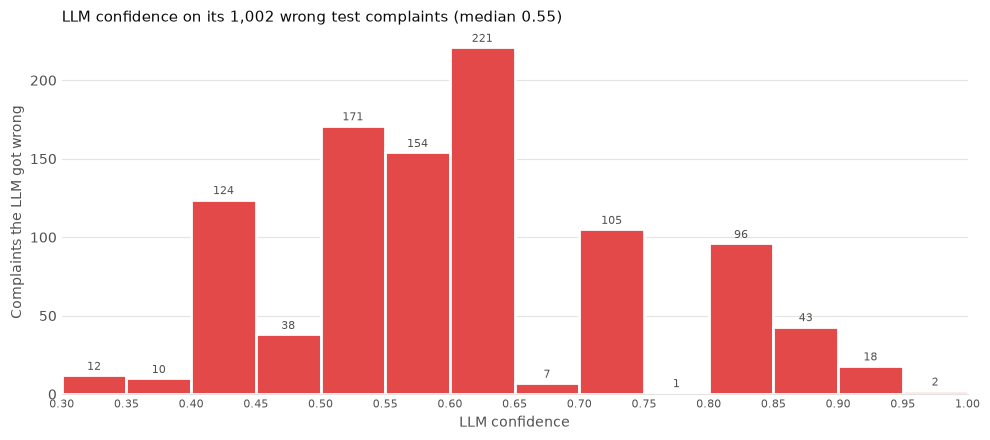

In [ ]:
# --- Human Review: the LLM's confidence on the complaints it gets wrong -----------
# Reads eval_df from Evaluation. Wrong = the LLM's Issue differs from the consumer's
# Bins are 0.05 wide and include their left edge (0.70 falls in 0.70-0.75)
assert "eval_df" in globals(), "Run the Evaluation section first: the chart reads eval_df"

BIN_EDGES = np.round(np.arange(30, 101, 5) / 100, 2)
WRONG_COLOR = "#e34948"   # palette slot 8 (red)
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"   # same chart ink as Explore

wrong_conf = eval_df.loc[eval_df["llm_issue"].ne(eval_df["Issue"]), "llm_confidence"]
counts, _ = np.histogram(wrong_conf, bins=BIN_EDGES)

results = [
    check("every wrong complaint falls in a bin", counts.sum() == len(wrong_conf),
          f"(expected {len(wrong_conf):,}, actual {counts.sum():,})"),
]
assert all(results), "A chart check failed; see the FAIL lines above"

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(BIN_EDGES[:-1], counts, width=0.05, align="edge", color=WRONG_COLOR, edgecolor="white", linewidth=2)
ax.bar_label(bars, labels=[f"{c:,}" if c else "" for c in counts], padding=2, fontsize=8, color=INK_MUTED)

ax.set_xticks(BIN_EDGES)
ax.set_xticklabels([f"{e:.2f}" for e in BIN_EDGES], fontsize=8)
ax.set_xlim(BIN_EDGES[0], BIN_EDGES[-1])
ax.set_xlabel("LLM confidence", color=INK_MUTED)
ax.set_ylabel("Complaints the LLM got wrong", color=INK_MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=INK_MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.set_title(f"LLM confidence on its {len(wrong_conf):,} wrong test complaints "
             f"(median {wrong_conf.median():.2f})", loc="left", fontsize=11, color=INK)
fig.tight_layout()
plt.show()

Confidence on Wrong Complaints

- **The result:** 737 of the LLM's 1,002 errors (74%) have a confidence below 0.70; the median is 0.55 and the largest bin is 0.60-0.65 (221 errors). Above 0.70 the count thins out (105 at 0.70-0.75, 96 at 0.80-0.85) and almost disappears above 0.90.
- **What it means:** most errors come with low confidence, so a cutoff near 0.70 reaches most of them. The chart counts errors only: it shows where the errors sit, not how often the LLM is wrong at each level.
- **Note:** the empty bins at 0.65-0.70 and 0.75-0.80 come from how the LLM states confidence: it reuses a few values (0.60, 0.62, 0.72, 0.80, 0.82) rather than spreading across the scale.

PASS  every test complaint falls in a bin  (expected 2,950, actual 2,950)
PASS  errors match the chart above  (expected 1,002, actual 1,002)


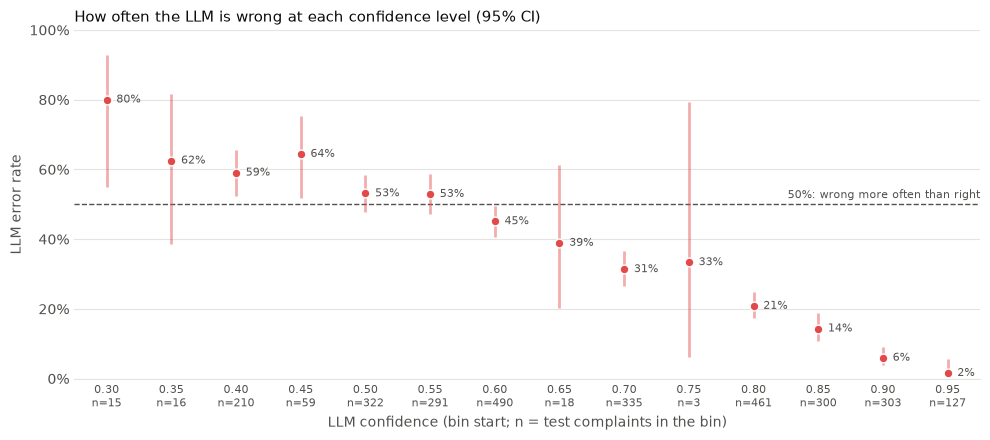

,n,wrong,error_rate,ci_low,ci_high
llm_confidence,,,,,
"[0.3, 0.35)",15,12,80.0%,54.8%,93.0%
"[0.35, 0.4)",16,10,62.5%,38.6%,81.5%
"[0.4, 0.45)",210,124,59.0%,52.3%,65.5%
"[0.45, 0.5)",59,38,64.4%,51.7%,75.4%
"[0.5, 0.55)",322,171,53.1%,47.7%,58.5%
"[0.55, 0.6)",291,154,52.9%,47.2%,58.6%
"[0.6, 0.65)",490,221,45.1%,40.8%,49.5%
"[0.65, 0.7)",18,7,38.9%,20.3%,61.4%
"[0.7, 0.75)",335,105,31.3%,26.6%,36.5%


In [52]:
# --- Human Review: how often the LLM is wrong at each confidence level --------------
# Same bins and colors as the chart above; error rate = wrong / all test complaints in the bin, with a 95% Wilson CI
# Few complaints in a bin = a wide CI: read those rates loosely
assert "BIN_EDGES" in globals(), "Run the confidence chart above first: this chart reuses its bins and colors"

conf_bins = pd.cut(eval_df["llm_confidence"], bins=BIN_EDGES, right=False)
by_bin = (eval_df.assign(wrong=eval_df["llm_issue"].ne(eval_df["Issue"]))
          .groupby(conf_bins, observed=True)["wrong"].agg(n="size", wrong="sum"))
by_bin["error_rate"] = by_bin["wrong"] / by_bin["n"]
by_bin["ci_low"], by_bin["ci_high"] = wilson_ci(by_bin["wrong"], by_bin["n"])

results = [
    check("every test complaint falls in a bin", by_bin["n"].sum() == len(eval_df),
          f"(expected {len(eval_df):,}, actual {by_bin['n'].sum():,})"),
    check("errors match the chart above", by_bin["wrong"].sum() == counts.sum(),
          f"(expected {counts.sum():,}, actual {by_bin['wrong'].sum():,})"),
]
assert all(results), "A chart check failed; see the FAIL lines above"

x = np.arange(len(by_bin))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axhline(0.5, color=INK_MUTED, lw=1, ls="--", zorder=1)
ax.text(x[-1] + 0.5, 0.51, "50%: wrong more often than right", va="bottom", ha="right", fontsize=8, color=INK_MUTED)
ax.vlines(x, by_bin["ci_low"], by_bin["ci_high"], color=WRONG_COLOR, lw=2, alpha=0.45, zorder=2)
ax.scatter(x, by_bin["error_rate"], s=40, color=WRONG_COLOR, edgecolor="white", linewidth=1, zorder=3)
for xi, rate in zip(x, by_bin["error_rate"]):
    ax.annotate(f"{rate:.0%}", (xi, rate), xytext=(7, 0), textcoords="offset points", va="center",
                fontsize=8, color=INK_MUTED)

ax.set_xticks(x)
ax.set_xticklabels([f"{b.left:.2f}\nn={n:,}" for b, n in zip(by_bin.index, by_bin["n"])], fontsize=8)
ax.set_xlim(-0.5, x[-1] + 0.5)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("LLM confidence (bin start; n = test complaints in the bin)", color=INK_MUTED)
ax.set_ylabel("LLM error rate", color=INK_MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=INK_MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.set_title("How often the LLM is wrong at each confidence level (95% CI)", loc="left", fontsize=11, color=INK)
fig.tight_layout()
plt.show()

display(by_bin.style.format({"error_rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"}))

Error Rate by Confidence

- **The result:** the LLM's error rate falls steadily as its confidence rises: 53% at 0.50-0.60, 45% at 0.60-0.65, 31% at 0.70-0.75, 21% at 0.80-0.85 and 2% at 0.95 and above. The stated numbers roughly match what happens (31% wrong at 0.70, 21% at 0.80); at 0.60 the LLM is somewhat overconfident (45% wrong rather than 40%). Four bins hold too few complaints to read (0.30-0.35, 0.35-0.40, 0.65-0.70 and 0.75-0.80, 3 to 18 each).
- **What it means:** confidence is a usable signal of when the LLM is likely wrong. With the count chart, it puts the balance near 0.70: below it sit three quarters of the errors and error rates of 45% and up; above it the LLM is wrong a third of the time or less, so flags there would mostly land on correct labels.
- **The problem with Version 1:** it treats every disagreement alike, so nearly half its flags land on labels the LLM had right, and at 38% of complaints the workload grows with every batch.
- **What we changed:** disagreement stays the trigger, but a disagreement goes to review only when the LLM's confidence is below 0.70.

##### Version 2: Disagreement Plus Low Confidence

Still a complaint-level rule built on the disagreement between the LLM and Classifier B, now narrowed by the LLM's own confidence. The two charts above show that the LLM's confidence tracks how often it is wrong, and that 0.70 balances errors caught against reviewer time.

**Rule.** Send a complaint to human review if the LLM and Classifier B predict different Issues and the LLM's confidence is below 0.70.

The back-test compares Version 1 with the new rule at cutoffs of 0.60, 0.70 and 0.80: complaints flagged (also per 1,000 complaints), LLM errors caught, and the share of flags that are real errors. It then breaks down the errors the rule lets through, and applies the rule to each week of June in the test set as a real-data check.

In [55]:
# --- Governance back-test: Human Review rule ------------------------------------
# Rule: send a complaint to human review if the LLM and Classifier B predict different Issues AND the LLM's
# confidence is below REVIEW_CUTOFF. Reads eval_df from Evaluation; n_flagged / n_caught come from the first-version cell
REVIEW_CUTOFF = 0.70                  # the rule's confidence cutoff, read off the two confidence charts
CUTOFF_SWEEP = [0.60, 0.70, 0.80]     # cutoffs compared in the back-test

assert "eval_df" in globals(), "Run the Evaluation section first: the back-test reads eval_df"

disagree = eval_df["llm_issue"].ne(eval_df["classifier_b_issue"])
wrong = eval_df["llm_issue"].ne(eval_df["Issue"])
review = disagree & eval_df["llm_confidence"].lt(REVIEW_CUTOFF)


def review_summary(flag, errors):
    """Workload and catch for one flag rule: complaints flagged, LLM errors caught, share of flags that are errors."""
    caught = int((flag & errors).sum())
    return {"complaints": len(flag), "flagged": int(flag.sum()), "flagged %": flag.mean(),
            "per 1,000 complaints": 1_000 * flag.mean(), "LLM errors": int(errors.sum()), "LLM errors caught": caught,
            "errors caught %": caught / errors.sum(), "flags that are errors": caught / flag.sum()}


FORMATS = {"complaints": "{:,.0f}", "flagged": "{:,.0f}", "flagged %": "{:.1%}", "per 1,000 complaints": "{:.0f}",
           "LLM errors": "{:,.0f}", "LLM errors caught": "{:,.0f}", "errors caught %": "{:.1%}", "flags that are errors": "{:.1%}"}

# 1. Version 1 against disagreement + confidence at each cutoff
rules = {"Version 1: any disagreement": disagree}
rules.update({f"disagree and confidence < {c:.2f}": disagree & eval_df["llm_confidence"].lt(c) for c in CUTOFF_SWEEP})
comparison = pd.DataFrame({name: review_summary(flag, wrong) for name, flag in rules.items()}).T
v1 = comparison.iloc[0]
assert check("Version 1 row matches the first-version cell", v1["flagged"] == n_flagged and v1["LLM errors caught"] == n_caught,
             f"(expected {n_flagged:,} flagged / {n_caught:,} caught, actual {v1['flagged']:,.0f} / {v1['LLM errors caught']:,.0f})"), \
    "Version 1 mismatch"
display(comparison.drop(columns=["complaints", "LLM errors"]).style.format(FORMATS)
        .set_caption(f"Review workload and LLM errors caught, by rule ({len(eval_df):,} test complaints, "
                     f"{wrong.sum():,} LLM errors)"))

# 2. The LLM errors the rule lets through, and why
missed = pd.Series({
    "both models agree on another Issue": int((wrong & ~disagree).sum()),
    f"models disagree, LLM confidence >= {REVIEW_CUTOFF:.2f}": int((wrong & disagree & ~review).sum()),
}, name="LLM errors not flagged")
assert check("caught + not flagged = all LLM errors", missed.sum() + (wrong & review).sum() == wrong.sum(),
             f"(expected {wrong.sum():,}, actual {missed.sum() + (wrong & review).sum():,})"), "Error count mismatch"
display(missed.to_frame())

# 3. Real-data check: the rule applied to each week of June in the test set
week = eval_df["Date received"].dt.to_period("W-SUN")
weekly = pd.DataFrame({w: review_summary(review[week == w], wrong[week == w]) for w in sorted(week.unique())}).T
weekly.index = [f"{w.start_time:%b %d}-{min(w.end_time, eval_df['Date received'].max()):%b %d}" for w in weekly.index]
display(weekly.style.format(FORMATS)
        .set_caption(f"The rule (disagree and confidence < {REVIEW_CUTOFF:.2f}) on each week of June"))

PASS  Version 1 row matches the first-version cell  (expected 1,124 flagged / 596 caught, actual 1,124 / 596)


,flagged,flagged %,"per 1,000 complaints",LLM errors caught,errors caught %,flags that are errors
Version 1: any disagreement,"1,124",38.1%,381,596,59.5%,53.0%
disagree and confidence < 0.60,544,18.4%,184,349,34.8%,64.2%
disagree and confidence < 0.70,773,26.2%,262,480,47.9%,62.1%
disagree and confidence < 0.80,906,30.7%,307,535,53.4%,59.1%


PASS  caught + not flagged = all LLM errors  (expected 1,002, actual 1,002)


,LLM errors not flagged
both models agree on another Issue,406
"models disagree, LLM confidence >= 0.70",116


,complaints,flagged,flagged %,"per 1,000 complaints",LLM errors,LLM errors caught,errors caught %,flags that are errors
Jun 01-Jun 07,513,119,23.2%,232,172,76,44.2%,63.9%
Jun 08-Jun 14,808,195,24.1%,241,271,118,43.5%,60.5%
Jun 15-Jun 21,626,180,28.8%,288,216,111,51.4%,61.7%
Jun 22-Jun 28,732,206,28.1%,281,242,124,51.2%,60.2%
Jun 29-Jun 30,271,73,26.9%,269,101,51,50.5%,69.9%


In [58]:
# --- Human Review: the trade-off between Version 1 and Version 2 ------------------
# Reads disagree, review and wrong from the Version 2 cell above. Positive = flagged; wrong = the LLM's Issue
# differs from the consumer's. True positive = an LLM error caught; false positive = review time that changes nothing;
# false negative = an LLM error let through
assert "review" in globals(), "Run the Version 2 cell above first: the table reads disagree, review and wrong"


def outcome_counts(flag):
    """Flagged, true / false positives and negatives for one flag rule."""
    return {"Flagged": int(flag.sum()),
            "True positives (flagged, LLM wrong)": int((flag & wrong).sum()),
            "False positives (flagged, LLM right)": int((flag & ~wrong).sum()),
            "False negatives (not flagged, LLM wrong)": int((~flag & wrong).sum()),
            "True negatives (not flagged, LLM right)": int((~flag & ~wrong).sum())}


trade_off = pd.DataFrame({"Version 1 (any disagreement)": outcome_counts(disagree),
                          f"Version 2 (disagreement + confidence < {REVIEW_CUTOFF:.2f})": outcome_counts(review)})
trade_off["Change"] = trade_off.iloc[:, 1] - trade_off.iloc[:, 0]
trade_off["Change per 1,000 complaints"] = 1_000 * trade_off["Change"] / len(eval_df)

results = [check(f"{col}: the four outcomes hold every test complaint", trade_off[col].iloc[1:].sum() == len(eval_df),
                 f"(expected {len(eval_df):,}, actual {trade_off[col].iloc[1:].sum():,})")
           for col in trade_off.columns[:2]]
assert all(results), "An outcome count failed; see the FAIL lines above"

display(trade_off.style.format({col: "{:+,}" if col == "Change" else "{:,}" for col in trade_off.columns[:3]}
                               | {"Change per 1,000 complaints": "{:+.0f}"})
        .set_caption(f"Version 1 vs. Version 2 on the {len(eval_df):,} test complaints ({wrong.sum():,} LLM errors)"))

PASS  Version 1 (any disagreement): the four outcomes hold every test complaint  (expected 2,950, actual 2,950)
PASS  Version 2 (disagreement + confidence < 0.70): the four outcomes hold every test complaint  (expected 2,950, actual 2,950)


,Version 1 (any disagreement),Version 2 (disagreement + confidence < 0.70),Change,"Change per 1,000 complaints"
Flagged,"1,124",773,-351,-119
"True positives (flagged, LLM wrong)",596,480,-116,-39
"False positives (flagged, LLM right)",528,293,-235,-80
"False negatives (not flagged, LLM wrong)",406,522,+116,+39
"True negatives (not flagged, LLM right)","1,420","1,655",+235,+80


- **The result:** the rule flags 773 of the 2,950 test complaints (26.2%, about 262 per 1,000) and catches 480 of the LLM's 1,002 errors (47.9%); 62.1% of its flags are real errors. The cutoffs bracket that choice: 0.60 flags 18.4% and catches 34.8%, while 0.80 flags 30.7% and catches 53.4%, with fewer of its flags being real errors (59.1%).
- **The errors let through:** of the 522, 406 are complaints where both models agree on an Issue other than the consumer's, which Version 1 also missed, and 116 are disagreements where the LLM's confidence is 0.70 or higher.
- **No week of June stands out:** the rule flags 23-29% of complaints and catches 44-51% of errors each week, and 60-70% of its flags are real errors.
- **Trade-off against Version 1:** Version 2 removes 351 flags (about 119 per 1,000 complaints). Two thirds of them (235) were false positives, labels the LLM had right where a reviewer would have changed nothing; the other 116 were LLM errors that now become false negatives. The rule gives up one caught error for about two reviews that would have changed nothing, and the errors it gives up are ones the LLM stated with confidence of 0.70 or higher, where it is wrong far less often.
- **What it means:** the review workload falls by about a third while a larger share of what reviewers see needs fixing (62% of flags against 53%). The false negatives are an upper bound: they assume the consumer's label is right, and in the rating check both raters chose the LLM's Issue on 8 of 10 LLM misses, so some of the 522, especially the 406 where both models agree, may be label ambiguity rather than errors.

#### Quantitative Harm Estimation

The harm of a wrong Issue lands at the company: the complaint arrives in the wrong queue and has to be re-tagged and passed on (Business Case). The cell below gives two figures, projected to the 620,794 complaints received in June 2026.

1. **How many complaints the LLM labels differently from the consumer each month.** The LLM is zero-shot Sonnet 5.5, out of the box with no fine-tuning, so this is its starting point, not its ceiling. It is also an upper bound on real errors: in the human rating, both raters chose the LLM's Issue on 8 of its 10 misses.
2. **The staff time and cost of fixing them, with and without the Version 2 review rule.** One handling is reading the narrative at 238 words per minute (Brysbaert, 2019) plus an assumed 2 minutes to pick the right Issue, re-tag and pass the complaint on, at \$21.53 an hour, the median wage for customer service representatives (BLS, May 2025). Without a rule, every LLM error lands in the wrong queue. With the Version 2 rule, flagged complaints are read once up front and only the unflagged errors land in the wrong queue. A complaint in the wrong queue is handled twice, by the wrong team and then the right one; one handling is shown as the floor.

**Sources.** Brysbaert, M. (2019). How many words do we read per minute? A review and meta-analysis of reading rate. *Journal of Memory and Language*, 109, 104047. U.S. Bureau of Labor Statistics, *Occupational Outlook Handbook*, Customer Service Representatives (median pay, May 2025).

In [61]:
# --- Harm estimate: LLM errors and staff rework, projected to a month of complaints ---
# Reads eval_df and modeling_set (Evaluation), MONTHLY_VOLUMES and projection (LLM Cost), REVIEW_CUTOFF (Human Review)
# Wrong = the LLM's Issue differs from the consumer's; the LLM is zero-shot Sonnet 5.5, out of the box, no fine-tuning
HOURLY_WAGE = 21.53            # BLS median hourly wage, customer service representatives (43-4051), May 2025
READING_WPM = 238              # average adult silent reading rate, English non-fiction (Brysbaert, 2019)
DECIDE_MINUTES = 2             # assumed minutes to pick the right Issue, re-tag and pass the complaint on
DECIDE_SWEEP = [1, 2, 3]       # the same assumption, varied
MISQUEUE_HANDLINGS = 2         # a complaint in the wrong queue is handled twice: the wrong team, then the right team
HANDLINGS_SWEEP = [1, 2]       # 1 = the floor: a wrong queue costs no more than a review read up front
MONTHLY_COMPLAINTS = MONTHLY_VOLUMES["all complaints"]   # June 2026: every complaint received

assert "REVIEW_CUTOFF" in globals() and "projection" in globals(), \
    "Run Evaluation (incl. LLM Cost) and the Human Review back-test first"

# Per test complaint: LLM wrong?, flagged by the Version 2 rule?, minutes to read its narrative
words = (modeling_set.set_index("Complaint ID")["Consumer complaint narrative"].str.split().str.len()
         .reindex(eval_df["Complaint ID"]).to_numpy())
wrong = eval_df["llm_issue"].ne(eval_df["Issue"]).to_numpy()
flagged = (eval_df["llm_issue"].ne(eval_df["classifier_b_issue"]) & eval_df["llm_confidence"].lt(REVIEW_CUTOFF)).to_numpy()
read_minutes = words / READING_WPM
n = len(eval_df)
assert check("every test complaint has a narrative", not np.isnan(words).any() and (words > 0).all(),
             f"({np.isnan(words).sum()} missing)"), "Narrative lookup failed"

# 1. Figure 1: the share of complaints the LLM gets wrong, projected to a month
k = int(wrong.sum())
low, high = wilson_ci(k, n)
figure_1 = pd.DataFrame({"LLM errors": [k], "error rate": [k / n], "95% CI low": [low], "95% CI high": [high],
                         "per month": [MONTHLY_COMPLAINTS * k / n], "per month, CI low": [MONTHLY_COMPLAINTS * low],
                         "per month, CI high": [MONTHLY_COMPLAINTS * high]}, index=["test set"])
display(figure_1.style.format({"LLM errors": "{:,.0f}", "error rate": "{:.1%}", "95% CI low": "{:.1%}", "95% CI high": "{:.1%}",
                               "per month": "{:,.0f}", "per month, CI low": "{:,.0f}", "per month, CI high": "{:,.0f}"})
        .set_caption(f"LLM errors (zero-shot, no fine-tuning) projected to {MONTHLY_COMPLAINTS:,} complaints a month"))


# 2. Figure 2: staff time and its cost, with and without the Version 2 review rule
def monthly_hours(handlings, decide):
    """Staff hours per month: no rule (every error misqueued) vs. Version 2 (flagged read once, unflagged errors misqueued)."""
    handle = read_minutes + decide                        # minutes for one handling of each test complaint
    no_rule = (handlings * handle[wrong]).sum()
    version_2 = handle[flagged].sum() + (handlings * handle[wrong & ~flagged]).sum()
    return {name: MONTHLY_COMPLAINTS * minutes / n / 60 for name, minutes in
            [("No review rule", no_rule), ("Version 2 review rule", version_2)]}


def cost_table(pairs, index_name):
    """Hours and cost per month for both scenarios, and what the rule saves (negative = it costs more)."""
    rows = {}
    for key, (handlings, decide) in pairs.items():
        hours = monthly_hours(handlings, decide)
        rows[key] = {**{f"{s}: hours": h for s, h in hours.items()},
                     **{f"{s}: cost": h * HOURLY_WAGE for s, h in hours.items()},
                     "rule saves per month": (hours["No review rule"] - hours["Version 2 review rule"]) * HOURLY_WAGE}
    table = pd.DataFrame(rows).T
    table.index.name = index_name
    return table


money = {c: ("${:,.0f}" if "cost" in c or "saves" in c else "{:,.0f}") for c in cost_table({1: (1, 1)}, "").columns}
print(f"Complaints touched per month: no rule {MONTHLY_COMPLAINTS * wrong.mean():,.0f} ({wrong.mean():.1%}); Version 2 "
      f"{MONTHLY_COMPLAINTS * flagged.mean():,.0f} read up front ({flagged.mean():.1%}) + "
      f"{MONTHLY_COMPLAINTS * (wrong & ~flagged).mean():,.0f} misqueued ({(wrong & ~flagged).mean():.1%})")
print(f"Narrative length (test set): median {np.median(words):,.0f} words, about {np.median(words) / READING_WPM:.1f} "
      f"minutes to read at {READING_WPM} words per minute")
display(cost_table({h: (h, DECIDE_MINUTES) for h in HANDLINGS_SWEEP}, "handlings per misqueued complaint")
        .style.format(money).set_caption(f"Staff time and cost per month at ${HOURLY_WAGE}/hour, {DECIDE_MINUTES} minutes to decide"))
display(cost_table({d: (MISQUEUE_HANDLINGS, d) for d in DECIDE_SWEEP}, "minutes to decide")
        .style.format(money).set_caption(f"The same, varying the decision time ({MISQUEUE_HANDLINGS} handlings per misqueued complaint)"))

llm_month = projection.loc[("all complaints", "standard"), "per month"]
print(f"For scale: the LLM's own token cost for {MONTHLY_COMPLAINTS:,} complaints a month is about ${llm_month:,.0f} "
      f"at standard (real-time) prices")

PASS  every test complaint has a narrative  (0 missing)


,LLM errors,error rate,95% CI low,95% CI high,per month,"per month, CI low","per month, CI high"
test set,"1,002",34.0%,32.3%,35.7%,"210,860","200,386","221,592"


Complaints touched per month: no rule 210,860 (34.0%); Version 2 162,669 read up front (26.2%) + 109,849 misqueued (17.7%)
Narrative length (test set): median 198 words, about 0.8 minutes to read at 238 words per minute


,No review rule: hours,Version 2 review rule: hours,No review rule: cost,Version 2 review rule: cost,rule saves per month
handlings per misqueued complaint,,,,,
1,"10,628","13,630","$228,821","$293,448","$-64,627"
2,"21,256","19,171","$457,643","$412,761","$44,882"


,No review rule: hours,Version 2 review rule: hours,No review rule: cost,Version 2 review rule: cost,rule saves per month
minutes to decide,,,,,
1,"14,227","12,799","$306,316","$275,555","$30,761"
2,"21,256","19,171","$457,643","$412,761","$44,882"
3,"28,285","25,544","$608,969","$549,967","$59,003"


For scale: the LLM's own token cost for 620,794 complaints a month is about $3,191 at standard (real-time) prices


- **Figure 1:** the LLM's Issue differs from the consumer's on 34.0% of test complaints (95% CI 32.3-35.7%), about 211,000 complaints a month (200,000-222,000).
- **Figure 2:** with two handlings per misqueued complaint, fixing them takes about 21,300 staff hours a month without a review rule (\$457,600) and 19,200 with the Version 2 rule (\$412,800). The rule saves about \$44,900 a month, about \$539,000 a year. Varying the decision time from 1 to 3 minutes moves the saving between \$30,800 and \$59,000 a month.
- **Where the rule stops paying:** if a misqueued complaint costs no more than a read up front (one handling), the rule costs about \$64,600 a month more than no rule, because it also reads the flagged complaints the LLM had right. Its payoff in staff time rests on the wrong queue costing more than a review, and that is before counting the consumer's longer wait.
- **For scale:** the LLM's own token cost for the same month is about \$3,191 at standard prices, under 1% of the rework cost.
- **Limits:** the wage leaves out benefits and overhead, so the cost is conservative. The month is 88% credit reporting, where the LLM's error rate is higher (40.4%) than on the test set overall, so the flat 34.0% likely understates the monthly count. Unpublished complaints are assumed to have narratives of similar length. And every "error" is a difference from the consumer's pick, which the rater finding suggests overstates real mistakes.

### 4. Data Rules

> **To revisit:** still Alex's draft wording; rewrite once the back-test rules are settled.

We send the redacted complaint narrative, `Product`, `Sub-product`, classification instructions, and the corresponding issue menu to the LLM. We use `Complaint ID` to match records and keep the recorded `Issue` separate for evaluation.

We treat the narratives as public-source data that may still contain identifying details. If we find any remaining identifiers, we remove them before sending the narrative. Raw unredacted narratives, personal identifiers, and API credentials are excluded from model inputs and shared project files.

### 5. Human Review and Disclosure

> **To revisit:** still Alex's draft wording; rewrite once the back-test rules are settled.

We flag a complaint for human review whenever Sonnet and Version B predict different Issue labels. Before the label is used, a team member reads the narrative, checks the allowed Issue options, and
records which label they would use and why. A second team member reviews ambiguous cases.

We backtest the rule on all 2,950 shared test complaints. We report the count and share flagged, the count and share of Sonnet’s exact-match errors flagged, and the number of errors missed when both models predict the same
Issue and that Issue differs from the recorded label.

In a separate 20-complaint exercise, both team members use a rubric to score Sonnet’s Issue choice, evidence, reasoning, and confidence. The exercise includes 10 predictions that match the recorded Issue and 10 that differ.

We label model outputs as predicted Issues in tables and charts and identify the recorded CFPB Issue as the reference used for evaluation.

### 6. Prohibited Uses and Escalation

> **To revisit:** still Alex's draft wording; rewrite once the back-test rules are settled.

We use the workflow to evaluate complaint classification. We prohibit using predictions to decide individual complaint outcomes, prioritize access to assistance, or make determinations about consumers or companies.

If Sonnet’s exact-match accuracy exceeds Version B’s by more than 6 percentage points on the same labeled batch, we hold Sonnet’s predicted labels back from use until the team reviews the discrepancy.

For products with at least 30 evaluated complaints, we flag a product if its Sonnet exact-match error rate is more than 1.25 times the lowest error rate among eligible products. A team member reviews the flagged product’s errors before its labels are used.

For each escalation, we record the rule that triggered, the affected batch or product, and the team’s decision about whether to include the results.

## From Results to Design

### What the Results Say About the Menu

Two results point at the menu rather than at the model. When the LLM's Issue differed from the consumer's, both human raters sided with the LLM on 8 of 10 complaints. And a stronger model (Opus 5.5) did not match the consumer's Issue more often than Sonnet 5.5, here (13 vs. 14 of 20 pilot narratives) or in an earlier prompt-testing assignment. Both signals are small, but they fit the weak link set out in the Business Case: part of the gap between the LLM and the consumer is the label, not the model.

### The Proposed Design

The direct fix is a more detailed Issue and Sub-issue menu that names problems the way consumers face them. The trade-off is that a menu detailed enough to be precise is too long for a person to read through. The fix of the fix is an optional suggestion: the consumer picks their Issue, and can then turn on an LLM that reads their narrative and suggests one or more Issues from the menu. The consumer keeps choosing the Product and Sub-product.

This project is the groundwork for that design: before an LLM suggests Issues to consumers, how close does it come to the Issue a person would pick?